In [1]:
from predictive_maintenance.paths import (
    PROJECT_ROOT,
    RAW_DATA_DIR,
    FIGURES_DIR,
)
from predictive_maintenance.config import DATASET_NAME, RANDOM_STATE

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data:     {RAW_DATA_DIR}")
print(f"Figures:      {FIGURES_DIR}")
print(f"Dataset:      {DATASET_NAME}")
print(f"Random state: {RANDOM_STATE}")

Project root: /Users/stuart/repos/ml-predictive-maintenance-mlops
Raw data:     /Users/stuart/repos/ml-predictive-maintenance-mlops/data/raw
Figures:      /Users/stuart/repos/ml-predictive-maintenance-mlops/reports/figures
Dataset:      FD001
Random state: 42


## 0. Notebook setup and reproducible loading

### Question

Can we reproducibly load the raw FD001 files into clearly structured DataFrames with an explicit schema, without modifying the source data?

### Why this matters

Before analyzing the dataset, the project needs a single, reproducible definition of how the raw C-MAPSS files are parsed.

The notebook should not depend on fragile relative paths or manually duplicated parsing logic. Reusable loading code will also make it easier to use the same data definitions later in training, testing, and other project components.

In [2]:
import sys

import pandas as pd

from predictive_maintenance.config import DATASET_NAME, RANDOM_STATE
from predictive_maintenance.data.cmapss import (
    CMAPSS_COLUMNS,
    load_cmapss_subset,
)
from predictive_maintenance.paths import (
    CMAPSS_DATA_DIR,
    FIGURES_DIR,
    PROJECT_ROOT,
)

In [3]:
print(f"Python executable: {sys.executable}")
print(f"Project root:      {PROJECT_ROOT}")
print(f"Dataset:           {DATASET_NAME}")
print(f"C-MAPSS directory: {CMAPSS_DATA_DIR}")
print(f"Figures directory: {FIGURES_DIR}")
print(f"Random state:      {RANDOM_STATE}")

Python executable: /Users/stuart/repos/ml-predictive-maintenance-mlops/.venv/bin/python3
Project root:      /Users/stuart/repos/ml-predictive-maintenance-mlops
Dataset:           FD001
C-MAPSS directory: /Users/stuart/repos/ml-predictive-maintenance-mlops/data/raw/CMAPSSData
Figures directory: /Users/stuart/repos/ml-predictive-maintenance-mlops/reports/figures
Random state:      42


In [4]:
expected_files = [
    CMAPSS_DATA_DIR / f"train_{DATASET_NAME}.txt",
    CMAPSS_DATA_DIR / f"test_{DATASET_NAME}.txt",
    CMAPSS_DATA_DIR / f"RUL_{DATASET_NAME}.txt",
]

for path in expected_files:
    print(f"{path.name}: {path.exists()}")

train_FD001.txt: True
test_FD001.txt: True
RUL_FD001.txt: True


In [5]:
train_df, test_df, test_rul_df = load_cmapss_subset(DATASET_NAME)

In [6]:
loading_summary = pd.DataFrame(
    {
        "dataset": [
            "train",
            "test",
            "test_rul",
        ],
        "rows": [
            len(train_df),
            len(test_df),
            len(test_rul_df),
        ],
        "columns": [
            train_df.shape[1],
            test_df.shape[1],
            test_rul_df.shape[1],
        ],
    }
)

loading_summary

,dataset,rows,columns
0,train,20631,26
1,test,13096,26
2,test_rul,100,1


In [7]:
display(train_df.head())
display(test_df.head())
display(test_rul_df.head())

,unit_no,cycles,op_setting_1,op_setting_2,op_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_12,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


,unit_no,cycles,op_setting_1,op_setting_2,op_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_12,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


,endpoint_rul
0,112
1,98
2,69
3,82
4,91


In [8]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   unit_no                20631 non-null  int64  
 1   cycles                 20631 non-null  int64  
 2   op_setting_1           20631 non-null  float64
 3   op_setting_2           20631 non-null  float64
 4   op_setting_3           20631 non-null  float64
 5   sensor_measurement_1   20631 non-null  float64
 6   sensor_measurement_2   20631 non-null  float64
 7   sensor_measurement_3   20631 non-null  float64
 8   sensor_measurement_4   20631 non-null  float64
 9   sensor_measurement_5   20631 non-null  float64
 10  sensor_measurement_6   20631 non-null  float64
 11  sensor_measurement_7   20631 non-null  float64
 12  sensor_measurement_8   20631 non-null  float64
 13  sensor_measurement_9   20631 non-null  float64
 14  sensor_measurement_10  20631 non-null  float64
 15  sensor_measur

In [9]:
assert not train_df.empty
assert not test_df.empty
assert not test_rul_df.empty

assert list(train_df.columns) == CMAPSS_COLUMNS
assert list(test_df.columns) == CMAPSS_COLUMNS

assert train_df.shape[1] == len(CMAPSS_COLUMNS)
assert test_df.shape[1] == len(CMAPSS_COLUMNS)

print("Basic loading checks passed.")

Basic loading checks passed.


Shape of train_df:
(20631, 26)

Shape of test_df:
(13096, 26)

Shape of test_rul_df:
(100, 1)

One row of train_df represents:
One row of train_df represents the sensor and operation setting readings at the point in time of one engine cycle. This is specific to a single engine and a single cycle.  

Major structural difference between test_df and test_rul_df:
test_df has less rows than train_df. This was to be expected because the test set does not contain run til failure data.

Anything surprising or confusing:
I'm a little confused by the fact that the test training set stops early (if I'm interpreting that correctly). Would it have interfered with this projects goals if both the training set and the test set had run until failure data? I somewhat understand why test_rul is needed, but is it critically important that the test set stops early? 

**Training trajectories run to failure so RUL labels can be constructed retrospectively. Test trajectories are truncated before failure to simulate making a prediction at the current point in an engine's life. The separate test-RUL file provides one ground-truth RUL value for the endpoint of each test engine.**

### Findings

- The FD001 training data contains 20,631 engine-cycle observations and 26 columns.
- The FD001 test data contains 13,096 engine-cycle observations with the same 26-column input schema.
- Each engine-data row represents one engine at one operating cycle, including its operating settings and sensor measurements.
- The test RUL file contains 100 rows and one column: one endpoint RUL label for each test engine.
- Training trajectories continue through failure, while test trajectories are intentionally truncated before failure.

### Modeling implications

- Training RUL can be derived retrospectively because the eventual failure cycle is observed in the training data.
- The final observed cycle of a test engine must not be interpreted as its failure cycle.
- Test predictions should use only information available through each engine's final observed test cycle.
- Future test measurements are deliberately unavailable, which mirrors the information constraints of real RUL inference.

## 1. Understand the dataset structure

### Question

How is FD001 organized in terms of engines, operating cycles, operating settings, sensor measurements, and train/test sequences?

### Why this matters

Before analyzing sensor behavior or constructing features, we need to understand the unit of observation and the hierarchical structure of the dataset.

FD001 is longitudinal data: multiple rows belong to the same engine and are ordered across operating cycles. That structure affects how we visualize the data, construct features, split engines for validation, and eventually perform inference.

In [10]:
from predictive_maintenance.data.cmapss import (
    ID_COLUMNS,
    OPERATING_SETTING_COLUMNS,
    SENSOR_COLUMNS,
)

schema_summary = pd.DataFrame(
    {
        "column_group": [
            "Identifiers / sequence",
            "Operating settings",
            "Sensor measurements",
        ],
        "count": [
            len(ID_COLUMNS),
            len(OPERATING_SETTING_COLUMNS),
            len(SENSOR_COLUMNS),
        ],
        "columns": [
            ", ".join(ID_COLUMNS),
            ", ".join(OPERATING_SETTING_COLUMNS),
            ", ".join(SENSOR_COLUMNS),
        ],
    }
)

schema_summary

,column_group,count,columns
0,Identifiers / sequence,2,"unit_no, cycles"
1,Operating settings,3,"op_setting_1, op_setting_2, op_setting_3"
2,Sensor measurements,21,"sensor_measurement_1, sensor_measurement_2, se..."


In [11]:
print(f"Total train columns: {train_df.shape[1]}")
print(f"Total test columns:  {test_df.shape[1]}")
print(f"Train/test schemas identical: {train_df.columns.equals(test_df.columns)}")

Total train columns: 26
Total test columns:  26
Train/test schemas identical: True


In [12]:
engine_count_summary = pd.DataFrame(
    {
        "dataset": ["train", "test"],
        "unique_engines": [
            train_df["unit_no"].nunique(),
            test_df["unit_no"].nunique(),
        ],
        "observations": [
            len(train_df),
            len(test_df),
        ],
    }
)

engine_count_summary

,dataset,unique_engines,observations
0,train,100,20631
1,test,100,13096


In [13]:
print(f"Test RUL labels: {len(test_rul_df)}")
print(f"Test engines:     {test_df['unit_no'].nunique()}")

Test RUL labels: 100
Test engines:     100


In [14]:
train_engine_lengths = (
    train_df.groupby("unit_no")
    .size()
    .rename("observed_cycles")
)

test_engine_lengths = (
    test_df.groupby("unit_no")
    .size()
    .rename("observed_cycles")
)

In [15]:
display(train_engine_lengths.head(10))
display(test_engine_lengths.head(10))

unit_no
1     192
2     287
3     179
4     189
5     269
6     188
7     259
8     150
9     201
10    222
Name: observed_cycles, dtype: int64

unit_no
1      31
2      49
3     126
4     106
5      98
6     105
7     160
8     166
9      55
10    192
Name: observed_cycles, dtype: int64

In [16]:
engine_length_summary = pd.DataFrame(
    {
        "train": train_engine_lengths.describe(),
        "test": test_engine_lengths.describe(),
    }
)

engine_length_summary

,train,test
count,100.000000,100.000000
mean,206.310000,130.960000
std,46.342749,53.593479
min,128.000000,31.000000
25%,177.000000,88.750000
50%,199.000000,133.500000
75%,229.250000,164.250000
max,362.000000,303.000000


In [17]:
example_unit = train_df["unit_no"].iloc[0]

example_engine = train_df.loc[
    train_df["unit_no"] == example_unit
]

print(f"Example engine: {example_unit}")
print(f"Number of observations: {len(example_engine)}")

display(example_engine.head())
display(example_engine.tail())

Example engine: 1
Number of observations: 192


,unit_no,cycles,op_setting_1,op_setting_2,op_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_12,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


,unit_no,cycles,op_setting_1,op_setting_2,op_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_12,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21
187,1,188,-0.0067,0.0003,100.0,518.67,643.75,1602.38,1422.78,14.62,...,519.79,2388.23,8117.69,8.5207,0.03,396,2388,100.0,38.51,22.9588
188,1,189,-0.0006,0.0002,100.0,518.67,644.18,1596.17,1428.01,14.62,...,519.58,2388.33,8117.51,8.5183,0.03,395,2388,100.0,38.48,23.1127
189,1,190,-0.0027,0.0001,100.0,518.67,643.64,1599.22,1425.95,14.62,...,520.04,2388.35,8112.58,8.5223,0.03,398,2388,100.0,38.49,23.0675
190,1,191,-0.0000,-0.0004,100.0,518.67,643.34,1602.36,1425.77,14.62,...,519.57,2388.30,8114.61,8.5174,0.03,394,2388,100.0,38.45,23.1295
191,1,192,0.0009,-0.0000,100.0,518.67,643.54,1601.41,1427.20,14.62,...,520.08,2388.32,8110.93,8.5113,0.03,396,2388,100.0,38.48,22.9649


In [18]:
example_engine[["unit_no", "cycles"]]

,unit_no,cycles
0,1,1
1,1,2
2,1,3
3,1,4
4,1,5
...,...,...
187,1,188
188,1,189
189,1,190
190,1,191


In [19]:
train_sequence_summary = (
    train_df.groupby("unit_no")["cycles"]
    .agg(
        first_observed_cycle="min",
        last_observed_cycle="max",
        number_of_rows="size",
    )
)

train_sequence_summary.head(10)

,first_observed_cycle,last_observed_cycle,number_of_rows
unit_no,,,
1,1,192,192
2,1,287,287
3,1,179,179
4,1,189,189
5,1,269,269
6,1,188,188
7,1,259,259
8,1,150,150
9,1,201,201


In [20]:
test_sequence_summary = (
    test_df.groupby("unit_no")["cycles"]
    .agg(
        first_observed_cycle="min",
        last_observed_cycle="max",
        number_of_rows="size",
    )
)

test_sequence_summary.head(10)

,first_observed_cycle,last_observed_cycle,number_of_rows
unit_no,,,
1,1,31,31
2,1,49,49
3,1,126,126
4,1,106,106
5,1,98,98
6,1,105,105
7,1,160,160
8,1,166,166
9,1,55,55


In [21]:
test_endpoint_summary = (
    test_sequence_summary
    .reset_index()
    .copy()
)

test_endpoint_summary["endpoint_rul"] = test_rul_df["endpoint_rul"].to_numpy()

test_endpoint_summary.head(10)

,unit_no,first_observed_cycle,last_observed_cycle,number_of_rows,endpoint_rul
0,1,1,31,31,112
1,2,1,49,49,98
2,3,1,126,126,69
3,4,1,106,106,82
4,5,1,98,98,91
5,6,1,105,105,93
6,7,1,160,160,91
7,8,1,166,166,95
8,9,1,55,55,111
9,10,1,192,192,96


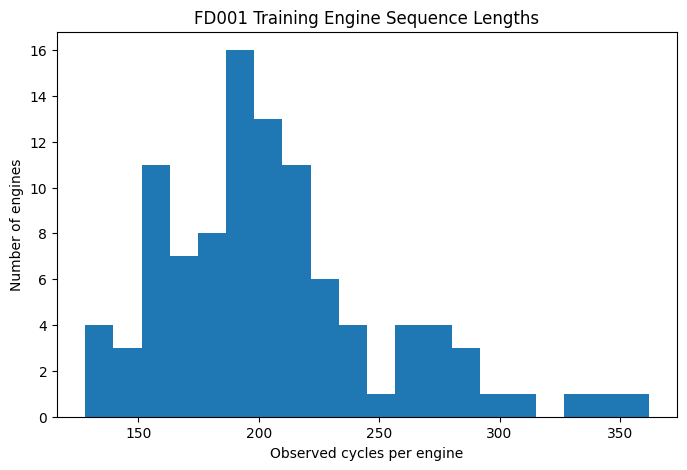

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(train_engine_lengths, bins=20)
plt.xlabel("Observed cycles per engine")
plt.ylabel("Number of engines")
plt.title("FD001 Training Engine Sequence Lengths")
plt.show()

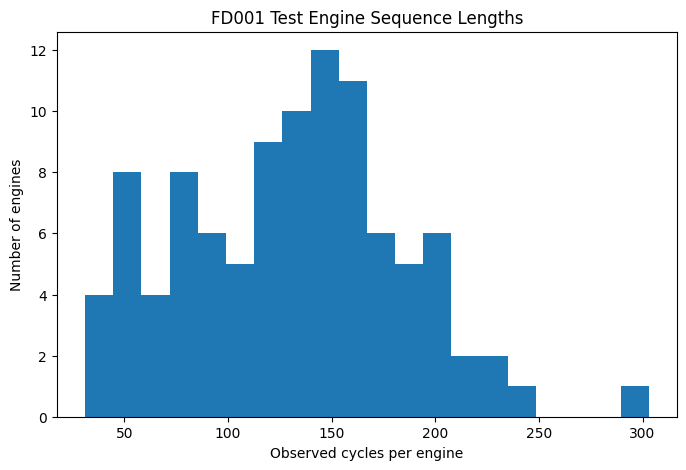

In [23]:
plt.figure(figsize=(8, 5))
plt.hist(test_engine_lengths, bins=20)
plt.xlabel("Observed cycles per engine")
plt.ylabel("Number of engines")
plt.title("FD001 Test Engine Sequence Lengths")
plt.show()

How many unique engines are in the training set and test set?
The training set and the test set each have 100 unique training engines. 

How are the 26 engine-data columns divided conceptually?
There are three types of columns: identifiers, operation settings, and sensor measurements. 

Do all engines have the same sequence length? What range of lengths do you observe in train and test?
No, effectively all of them have different sequence lengths. They range from 128 to 362 in the training set, and 31 to 303 in the test set.

What does cycles appear to represent within one engine?
A length of time in between data collections. 

What relationship do you see between the number of test engines and the number of rows in test_rul_df?
They're equal, meaning there is one true RUL associated with each test engine that we can compare to any predictions we make. 

What does one row of test_endpoint_summary mean?
One row of test_endpoint_summary is a collection of critical features of a single engine: the engine identifier, the first and last observed number of cycles, the number of rows associated with that engine, and the true endpoint RUL. 

Looking at the sequence-length histograms, what stands out to you?
Both appear to be skewed distributions that do not fit a conventional gaussian. Each have outliers in the right region (i.e., engines with especially long lifetimes) but not so much in the left region (engines with unusually short lifetimes). 

Does anything remain confusing or surprising?
No, I think I'm a bit more confident with this set of question compared to the last set of questions.

### Findings

- FD001 contains 100 training engines and 100 separate test engines.
- Each engine-data observation contains 26 columns:
  - 2 identifier/sequence columns (`unit_no`, `cycles`)
  - 3 operating-setting columns
  - 21 sensor-measurement columns
- Rows belonging to the same engine form an ordered sequence across operating cycles.
- Training engines have variable run-to-failure sequence lengths, ranging from 128 to 362 observed cycles.
- Test engines also have variable observed-history lengths, ranging from 31 to 303 cycles, but their sequences are truncated before failure.
- `cycles` is an operating-cycle index rather than a known unit of clock time.
- The test set contains 100 engines and the test-RUL file contains 100 labels, providing one endpoint RUL value for each test engine.
- Sequence-length distributions have longer right tails, meaning some engines contribute substantially more observations than others.m

### Modeling implications

- FD001 must be treated as longitudinal, grouped data rather than a collection of independent rows.
- Engine identity must be preserved when analyzing trajectories, constructing temporal features, and creating validation splits.
- Different engines contribute different numbers of observations, so row-level evaluation can implicitly give longer sequences more influence.
- The final observed cycle of a training engine represents failure, whereas the final observed cycle of a test engine represents only the prediction endpoint.
- Test sequence length should not be interpreted as the engine's true lifetime.

## 2. Construct and validate the training RUL target

### Question

How can we construct a valid RUL target for every training observation, and how can we verify that the resulting labels behave as expected?

### Why this matters

Supervised learning requires a target value for every training observation.

Because each FD001 training engine is observed through failure, its final operating cycle can be used retrospectively to calculate how many operating cycles remained at every earlier observation.

This target-construction logic must be explicitly validated because an incorrect RUL target would invalidate every modeling result that follows.

In [24]:
"""Target construction utilities for C-MAPSS training data."""

import pandas as pd


def add_training_rul(df: pd.DataFrame) -> pd.DataFrame:
    """Add final-cycle and RUL columns to run-to-failure training data."""

    required_columns = {"unit_no", "cycles"}
    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {sorted(missing_columns)}"
        )

    labeled_df = df.copy()

    labeled_df["final_cycle"] = (
        labeled_df.groupby("unit_no")["cycles"]
        .transform("max")
    )

    labeled_df["rul"] = (
        labeled_df["final_cycle"]
        - labeled_df["cycles"]
    )

    return labeled_df

In [25]:
# --- Construct RUL labels from complete training trajectories ---

from predictive_maintenance.data.targets import add_training_rul

train_labeled_df = add_training_rul(train_df)

train_labeled_df.head()

,unit_no,cycles,op_setting_1,op_setting_2,op_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21,final_cycle,rul
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,192,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,192,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,192,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,192,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,192,187


In [26]:
# --- Inspect the beginning and end of one labeled engine trajectory ---

example_unit = train_labeled_df["unit_no"].iloc[0]

example_labeled_engine = train_labeled_df.loc[
    train_labeled_df["unit_no"] == example_unit,
    ["unit_no", "cycles", "final_cycle", "rul"],
]

display(example_labeled_engine.head(10))
display(example_labeled_engine.tail(10))

,unit_no,cycles,final_cycle,rul
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


,unit_no,cycles,final_cycle,rul
182,1,183,192,9
183,1,184,192,8
184,1,185,192,7
185,1,186,192,6
186,1,187,192,5
187,1,188,192,4
188,1,189,192,3
189,1,190,192,2
190,1,191,192,1
191,1,192,192,0


In [27]:
# --- Verify every training engine reaches RUL = 0 at its final observation ---

training_endpoints = (
    train_labeled_df
    .sort_values(["unit_no", "cycles"])
    .groupby("unit_no")
    .tail(1)
)

training_endpoints[
    ["unit_no", "cycles", "final_cycle", "rul"]
].head(10)

,unit_no,cycles,final_cycle,rul
191,1,192,192,0
478,2,287,287,0
657,3,179,179,0
846,4,189,189,0
1115,5,269,269,0
1303,6,188,188,0
1562,7,259,259,0
1712,8,150,150,0
1913,9,201,201,0
2135,10,222,222,0


In [28]:
# --- Confirm all training endpoints have zero remaining useful life ---

endpoint_rul_values = training_endpoints["rul"].unique()

print(f"Unique endpoint RUL values: {endpoint_rul_values}")

assert (training_endpoints["rul"] == 0).all()

print("All training engines end at RUL = 0.")

Unique endpoint RUL values: [0]
All training engines end at RUL = 0.


In [29]:
# --- Validate final_cycle against the observed maximum cycle for every engine ---

final_cycle_check = (
    train_labeled_df.groupby("unit_no")
    .agg(
        observed_max_cycle=("cycles", "max"),
        derived_final_cycle=("final_cycle", "first"),
    )
)

final_cycle_check["matches"] = (
    final_cycle_check["observed_max_cycle"]
    == final_cycle_check["derived_final_cycle"]
)

display(final_cycle_check.head())

assert final_cycle_check["matches"].all()

print("Derived final cycles match observed training endpoints.")

,observed_max_cycle,derived_final_cycle,matches
unit_no,,,
1,192,192,True
2,287,287,True
3,179,179,True
4,189,189,True
5,269,269,True


Derived final cycles match observed training endpoints.


In [30]:
# --- Calculate successive RUL changes within each engine ---

rul_changes = (
    train_labeled_df
    .sort_values(["unit_no", "cycles"])
    .groupby("unit_no")["rul"]
    .diff()
    .dropna()
)

rul_changes.value_counts().sort_index()

rul
-1.0    20531
Name: count, dtype: int64

In [31]:
# --- Confirm RUL decreases by exactly one between consecutive observations ---

assert (rul_changes == -1).all()

print("RUL decreases by exactly one across consecutive training observations.")

RUL decreases by exactly one across consecutive training observations.


In [32]:
# --- Verify all constructed training RUL values are nonnegative ---

print(f"Minimum training RUL: {train_labeled_df['rul'].min()}")
print(f"Maximum training RUL: {train_labeled_df['rul'].max()}")

assert train_labeled_df["rul"].ge(0).all()

print("All training RUL values are nonnegative.")

Minimum training RUL: 0
Maximum training RUL: 361
All training RUL values are nonnegative.


In [33]:
# --- Inspect each engine's starting RUL relative to its final cycle ---

training_starts = (
    train_labeled_df
    .sort_values(["unit_no", "cycles"])
    .groupby("unit_no")
    .head(1)
)

training_starts[
    ["unit_no", "cycles", "final_cycle", "rul"]
].head(10)

,unit_no,cycles,final_cycle,rul
0,1,1,192,191
192,2,1,287,286
479,3,1,179,178
658,4,1,189,188
847,5,1,269,268
1116,6,1,188,187
1304,7,1,259,258
1563,8,1,150,149
1713,9,1,201,200
1914,10,1,222,221


In [34]:
# --- Validate the expected RUL at the first observed cycle ---

expected_starting_rul = (
    training_starts["final_cycle"]
    - training_starts["cycles"]
)

assert (
    training_starts["rul"]
    == expected_starting_rul
).all()

print("Starting RUL values are consistent with each engine's final cycle.")

Starting RUL values are consistent with each engine's final cycle.


### Target-construction warning

`final_cycle` is valid for constructing training labels because the training trajectories are historical run-to-failure records.

However, `final_cycle` represents future information from the perspective of an earlier operating cycle.

Therefore:

- `final_cycle` must never be used as a predictive feature.
- `rul` is the supervised-learning target and must never appear among the input features.
- The equivalent true failure cycle is not available during real inference.

The model must learn to predict RUL from information available at or before the current operating cycle, not from information revealed by the engine's eventual failure.

How is final_cycle calculated for a training engine?
The training sets run until failure, so we simply get the cycle number of the final row associated with a unique engine.

How is RUL calculated for one particular engine-cycle observation?
We take the difference of two values. We subtract the current cycle from the final_cycle. 

What RUL does the final training observation of every engine have, and why?
0, because that means we're at the point where there are no more rows of data and a failure has occurred. 

How does RUL change as an engine advances from one cycle to the next?
RUL decreases linearly, i.e., but just 1 cycle with each passing row. 

What are the minimum and maximum RUL values you observed?
The minimum training RUL was 0, which is the final observation of any engine. The maximum RUL value was 361, which we could expect is from the engine with the longest lifetime. 

Why are we allowed to use final_cycle to construct the training target but not as  an input feature?
Because having final_cycle among the input features would create leakage in the data? The goal is to predict the final_cycle given the input data, if it were already in the input data then we would be predicting something we already have access to. 

**final_cycle can be used to construct the training label because the training data contains completed historical run-to-failure trajectories. Looking retrospectively, we know when each engine eventually failed, so we can calculate RUL at earlier cycles. But at actual inference time the eventual failure cycle is future information and therefore unavailable. Using it as an input feature would leak the answer into the model.**


Suppose an engine's final training cycle is 250. What is its RUL at cycle 100, and what information would actually be known at cycle 100 during inference?
150. The information at cycle 100 will be all the data rows leading up to cycle 100. So we have all information from previous cycles but not from future cycles. 

Does anything in the results surprise or confuse you?
Question #6 is a question I've never had to consider before.

### Findings

- Each FD001 training trajectory is observed through failure, allowing the engine's final cycle to be determined retrospectively.
- `final_cycle` is the maximum observed cycle for each training engine.
- Training RUL is calculated as `final_cycle - cycles`.
- Every training engine reaches RUL = 0 at its failure endpoint.
- RUL decreases by exactly one for each successive operating cycle.
- Training RUL ranges from 0 to 361 cycles in FD001.
- The longest training engine contains 362 cycles, giving its first observation an RUL of 361.

### Modeling implications

- `rul` is the supervised-learning target and must never be included among model inputs.
- `final_cycle` is valid for retrospective target construction but must never be used as a predictive feature because it contains future information.
- At inference time, the model may use only information available at or before the current cycle.
- Temporal features must therefore be causal: earlier observations may inform later predictions, but future observations may never inform earlier predictions.
- The uncapped RUL target will remain our reference target until later EDA and modeling experiments provide evidence for alternative formulations.

## 3. Engine-sequence integrity

### Question

Are the engine histories internally consistent, uniquely ordered, and suitable for longitudinal analysis and temporal feature engineering?

### Why this matters

FD001 is sequential data. Later analyses and features will assume that each engine has a valid ordered history.

Before creating lags, rolling statistics, trends, or grouped validation logic, we need to verify that:

- each engine-cycle pair is unique,
- cycles are ordered correctly within each engine,
- cycle numbers progress as expected,
- engine histories do not overlap or mix together,
- and sequence boundaries are preserved.

In [35]:
# --- Check whether each engine-cycle observation is unique ---

duplicate_engine_cycles = (
    train_labeled_df
    .duplicated(subset=["unit_no", "cycles"], keep=False)
)

print(
    f"Duplicate engine-cycle rows in training data: "
    f"{duplicate_engine_cycles.sum()}"
)

Duplicate engine-cycle rows in training data: 0


In [36]:
# --- Check engine-cycle uniqueness in the test data ---

duplicate_test_engine_cycles = (
    test_df
    .duplicated(subset=["unit_no", "cycles"], keep=False)
)

print(
    f"Duplicate engine-cycle rows in test data: "
    f"{duplicate_test_engine_cycles.sum()}"
)

Duplicate engine-cycle rows in test data: 0


In [37]:
# --- Check whether training rows are already ordered by engine and cycle ---

train_sorted_index = (
    train_labeled_df
    .sort_values(["unit_no", "cycles"])
    .index
)

train_is_sorted = train_sorted_index.equals(train_labeled_df.index)

print(f"Training data already sorted: {train_is_sorted}")

Training data already sorted: True


In [38]:
# --- Check whether test rows are already ordered by engine and cycle ---

test_sorted_index = (
    test_df
    .sort_values(["unit_no", "cycles"])
    .index
)

test_is_sorted = test_sorted_index.equals(test_df.index)

print(f"Test data already sorted: {test_is_sorted}")

Test data already sorted: True


In [39]:
# --- Check the first observed cycle for every training engine ---

train_first_cycles = (
    train_labeled_df
    .groupby("unit_no")["cycles"]
    .min()
)

train_first_cycles.value_counts().sort_index()

cycles
1    100
Name: count, dtype: int64

In [40]:
# --- Check the first observed cycle for every test engine ---

test_first_cycles = (
    test_df
    .groupby("unit_no")["cycles"]
    .min()
)

test_first_cycles.value_counts().sort_index()

cycles
1    100
Name: count, dtype: int64

In [41]:
# --- Calculate cycle-to-cycle increments within each training engine ---

train_cycle_steps = (
    train_labeled_df
    .sort_values(["unit_no", "cycles"])
    .groupby("unit_no")["cycles"]
    .diff()
    .dropna()
)

train_cycle_steps.value_counts().sort_index()

cycles
1.0    20531
Name: count, dtype: int64

In [42]:
# --- Verify training cycles advance one step at a time ---

assert (train_cycle_steps == 1).all()

print("Training cycles advance consecutively by one.")

Training cycles advance consecutively by one.


In [43]:
# --- Calculate and validate cycle increments in test histories ---

test_cycle_steps = (
    test_df
    .sort_values(["unit_no", "cycles"])
    .groupby("unit_no")["cycles"]
    .diff()
    .dropna()
)

print(test_cycle_steps.value_counts().sort_index())

assert (test_cycle_steps == 1).all()

print("Test cycles advance consecutively by one.")

cycles
1.0    12996
Name: count, dtype: int64
Test cycles advance consecutively by one.


In [44]:
# --- Compare training row counts with each engine's observed cycle range ---

train_sequence_integrity = (
    train_labeled_df
    .groupby("unit_no")["cycles"]
    .agg(
        first_cycle="min",
        last_cycle="max",
        row_count="size",
    )
)

train_sequence_integrity["expected_rows"] = (
    train_sequence_integrity["last_cycle"]
    - train_sequence_integrity["first_cycle"]
    + 1
)

train_sequence_integrity["complete_sequence"] = (
    train_sequence_integrity["row_count"]
    == train_sequence_integrity["expected_rows"]
)

display(train_sequence_integrity.head())

print(
    "Complete training sequences:",
    train_sequence_integrity["complete_sequence"].sum(),
    "/",
    len(train_sequence_integrity),
)

,first_cycle,last_cycle,row_count,expected_rows,complete_sequence
unit_no,,,,,
1,1,192,192,192,True
2,1,287,287,287,True
3,1,179,179,179,True
4,1,189,189,189,True
5,1,269,269,269,True


Complete training sequences: 100 / 100


In [45]:
# --- Compare test row counts with each engine's observed cycle range ---

test_sequence_integrity = (
    test_df
    .groupby("unit_no")["cycles"]
    .agg(
        first_cycle="min",
        last_cycle="max",
        row_count="size",
    )
)

test_sequence_integrity["expected_rows"] = (
    test_sequence_integrity["last_cycle"]
    - test_sequence_integrity["first_cycle"]
    + 1
)

test_sequence_integrity["complete_sequence"] = (
    test_sequence_integrity["row_count"]
    == test_sequence_integrity["expected_rows"]
)

display(test_sequence_integrity.head())

print(
    "Complete test sequences:",
    test_sequence_integrity["complete_sequence"].sum(),
    "/",
    len(test_sequence_integrity),
)

,first_cycle,last_cycle,row_count,expected_rows,complete_sequence
unit_no,,,,,
1,1,31,31,31,True
2,1,49,49,49,True
3,1,126,126,126,True
4,1,106,106,106,True
5,1,98,98,98,True


Complete test sequences: 100 / 100


In [46]:
# --- Inspect the range of engine identifiers ---

print(
    f"Training engine IDs: "
    f"{train_labeled_df['unit_no'].min()} "
    f"to {train_labeled_df['unit_no'].max()}"
)

print(
    f"Test engine IDs: "
    f"{test_df['unit_no'].min()} "
    f"to {test_df['unit_no'].max()}"
)

Training engine IDs: 1 to 100
Test engine IDs: 1 to 100


In [47]:
# --- Inspect whether engine IDs form a consecutive sequence ---

train_units = sorted(train_labeled_df["unit_no"].unique())
test_units = sorted(test_df["unit_no"].unique())

print(
    "Training IDs consecutive:",
    train_units == list(range(1, len(train_units) + 1)),
)

print(
    "Test IDs consecutive:",
    test_units == list(range(1, len(test_units) + 1)),
)

Training IDs consecutive: True
Test IDs consecutive: True


In [48]:
# --- Inspect the boundary between two engine sequences ---

boundary_rows = (
    train_labeled_df[
        ["unit_no", "cycles", "rul"]
    ]
    .loc[
        train_labeled_df["unit_no"].isin([1, 2])
    ]
)

display(boundary_rows.tail(5))

,unit_no,cycles,rul
474,2,283,4
475,2,284,3
476,2,285,2
477,2,286,1
478,2,287,0


In [49]:
# --- Show the end of engine 1 and beginning of engine 2 ---

display(
    train_labeled_df.loc[
        train_labeled_df["unit_no"] == 1,
        ["unit_no", "cycles", "rul"],
    ].tail(3)
)

display(
    train_labeled_df.loc[
        train_labeled_df["unit_no"] == 2,
        ["unit_no", "cycles", "rul"],
    ].head(3)
)

,unit_no,cycles,rul
189,1,190,2
190,1,191,1
191,1,192,0


,unit_no,cycles,rul
192,2,1,286
193,2,2,285
194,2,3,284


In [50]:
# --- Summarize sequence-integrity checks for train and test ---

sequence_check_summary = pd.DataFrame(
    {
        "check": [
            "Duplicate engine-cycle pairs",
            "Starts at cycle 1",
            "Cycle increments equal 1",
            "Row count matches cycle range",
        ],
        "train": [
            duplicate_engine_cycles.sum() == 0,
            (train_first_cycles == 1).all(),
            (train_cycle_steps == 1).all(),
            train_sequence_integrity["complete_sequence"].all(),
        ],
        "test": [
            duplicate_test_engine_cycles.sum() == 0,
            (test_first_cycles == 1).all(),
            (test_cycle_steps == 1).all(),
            test_sequence_integrity["complete_sequence"].all(),
        ],
    }
)

sequence_check_summary

,check,train,test
0,Duplicate engine-cycle pairs,True,True
1,Starts at cycle 1,True,True
2,Cycle increments equal 1,True,True
3,Row count matches cycle range,True,True


In [51]:
# --- Summarize whether each sequence-integrity requirement passes ---

sequence_check_summary = pd.DataFrame(
    {
        "requirement": [
            "Engine-cycle pairs are unique",
            "Every engine starts at cycle 1",
            "Cycles advance consecutively",
            "Row counts match cycle ranges",
        ],
        "train_passes": [
            duplicate_engine_cycles.sum() == 0,
            (train_first_cycles == 1).all(),
            (train_cycle_steps == 1).all(),
            train_sequence_integrity["complete_sequence"].all(),
        ],
        "test_passes": [
            duplicate_test_engine_cycles.sum() == 0,
            (test_first_cycles == 1).all(),
            (test_cycle_steps == 1).all(),
            test_sequence_integrity["complete_sequence"].all(),
        ],
    }
)

sequence_check_summary

,requirement,train_passes,test_passes
0,Engine-cycle pairs are unique,True,True
1,Every engine starts at cycle 1,True,True
2,Cycles advance consecutively,True,True
3,Row counts match cycle ranges,True,True


Are (unit_no, cycles) pairs unique in both train and test?
Yes, zero duplicate rows were found in each. 

Do all engines begin at cycle 1?
Yes, all 100 engines in the training and testing data start at 1. 

Do cycles advance consecutively by exactly one within every engine?
Yes, we asserted that cycle_steps were 1 for all rows in the training and test data. 

Does each engine's row count match its observed cycle range?
Yes, the row count and the expected rows were a match for all 200 unique engines across both datasets. 

Are the engine IDs consecutive, and does that make unit_no a meaningful numeric predictor?
Yes, both were confirmed to be consecutive across all data. unit_no is not a meaningful numeric predictor because it's simply an identifier and not something that came as a result of measuring or observing. 

Why must temporal operations like shift() and rolling windows be grouped by unit_no?
Because a change in unit_no means the dataset has shifted onto another engine and the current engine that was being examined reached its final cycle. 

What would happen if a lag feature were created with a plain .shift(1) over the entire DataFrame?
That I do not know. The concept of shift and lag is new to me. 

Based on these checks, do you trust the basic sequence structure enough to proceed to sensor-level EDA?
Yes, we can trust all sensor readings to be data points that evolve in time and can be assumed dependent on previous readings for future readings. 
**The sequence structure is trustworthy enough to begin sensor-level EDA, but whether individual sensors contain useful temporal or degradation signal remains an empirical question. Also, Valid temporal ordering does not automatically imply useful temporal dependence.**

Anything surprising or confusing?
The temporal operations were new to me and I hadn't thought about anything in those questions before. 

### Findings

- `(unit_no, cycles)` uniquely identifies every training and test observation.
- All 100 training engines and all 100 test engines begin at cycle 1.
- Cycle numbers increase consecutively by one within every engine, with no observed internal gaps.
- Each engine's number of rows agrees with its observed cycle range.
- Engine identifiers are consecutive, but `unit_no` is an identifier rather than a meaningful quantitative measurement.
- Engine boundaries are explicit: cycle numbering resets when a new engine sequence begins.

### Modeling implications

- The dataset has a coherent sequential structure suitable for longitudinal analysis.
- Temporal operations must always respect engine boundaries.
- Lagged and rolling features must be grouped by `unit_no` so values from one engine cannot leak into another engine's history.
- Temporal feature-generation code should explicitly sort by `unit_no` and `cycles` rather than relying on the existing row order.
- `unit_no` should be retained for grouping, splitting, joining, and traceability, but not treated as an ordinary numeric predictive feature.
- Sequence integrity alone does not establish that a sensor contains useful temporal or degradation signal; that must be investigated empirically.

## 4. General data-quality audit

### Question

Do the FD001 training and test datasets contain missing, non-finite, duplicated, incorrectly typed, or otherwise suspicious values that need to be understood before sensor-level analysis?

### Why this matters

Machine-learning pipelines can fail or produce misleading results when the underlying data contain missing values, invalid numeric values, unexpected types, duplicate observations, or unexplained extreme measurements.

However, predictive-maintenance data may naturally contain unusual values as equipment degrades. Therefore, this audit should identify suspicious observations without automatically treating statistically unusual values as errors.

In [52]:
# --- Inspect data types in the training and test datasets ---

dtype_summary = pd.DataFrame(
    {
        "train_dtype": train_df.dtypes.astype(str),
        "test_dtype": test_df.dtypes.astype(str),
    }
)

dtype_summary

,train_dtype,test_dtype
unit_no,int64,int64
cycles,int64,int64
op_setting_1,float64,float64
op_setting_2,float64,float64
op_setting_3,float64,float64
sensor_measurement_1,float64,float64
sensor_measurement_2,float64,float64
sensor_measurement_3,float64,float64
sensor_measurement_4,float64,float64
sensor_measurement_5,float64,float64


In [53]:
# --- Check whether train and test use the same data type for each column ---

dtype_summary["matches"] = (
    dtype_summary["train_dtype"]
    == dtype_summary["test_dtype"]
)

print(
    f"Columns with matching train/test dtypes: "
    f"{dtype_summary['matches'].sum()} / {len(dtype_summary)}"
)

display(dtype_summary)

Columns with matching train/test dtypes: 26 / 26


,train_dtype,test_dtype,matches
unit_no,int64,int64,True
cycles,int64,int64,True
op_setting_1,float64,float64,True
op_setting_2,float64,float64,True
op_setting_3,float64,float64,True
sensor_measurement_1,float64,float64,True
sensor_measurement_2,float64,float64,True
sensor_measurement_3,float64,float64,True
sensor_measurement_4,float64,float64,True
sensor_measurement_5,float64,float64,True


In [54]:
# --- Count missing values in every training column ---

train_missing = (
    train_df
    .isna()
    .sum()
    .sort_values(ascending=False)
)

train_missing[train_missing > 0]

Series([], dtype: int64)

In [55]:
# --- Count missing values in every test column ---

test_missing = (
    test_df
    .isna()
    .sum()
    .sort_values(ascending=False)
)

test_missing[test_missing > 0]

Series([], dtype: int64)

In [56]:
# --- Summarize missing-value counts across train and test ---

missing_summary = pd.DataFrame(
    {
        "dataset": ["train", "test"],
        "missing_values": [
            train_df.isna().sum().sum(),
            test_df.isna().sum().sum(),
        ],
        "rows_with_missing_values": [
            train_df.isna().any(axis=1).sum(),
            test_df.isna().any(axis=1).sum(),
        ],
    }
)

missing_summary

,dataset,missing_values,rows_with_missing_values
0,train,0,0
1,test,0,0


In [57]:
# --- Count positive and negative infinity values in training data ---

import numpy as np

train_infinite_counts = (
    np.isinf(train_df.select_dtypes(include="number"))
    .sum()
    .sort_values(ascending=False)
)

train_infinite_counts[train_infinite_counts > 0]

Series([], dtype: int64)

In [58]:
# --- Count positive and negative infinity values in test data ---

test_infinite_counts = (
    np.isinf(test_df.select_dtypes(include="number"))
    .sum()
    .sort_values(ascending=False)
)

test_infinite_counts[test_infinite_counts > 0]

Series([], dtype: int64)

In [59]:
# --- Summarize whether any non-finite numeric values were detected ---

train_inf_total = int(
    np.isinf(train_df.select_dtypes(include="number")).sum().sum()
)

test_inf_total = int(
    np.isinf(test_df.select_dtypes(include="number")).sum().sum()
)

print(f"Infinite training values: {train_inf_total}")
print(f"Infinite test values:     {test_inf_total}")

Infinite training values: 0
Infinite test values:     0


In [60]:
# --- Check for exact duplicate rows in training and test data ---

train_exact_duplicates = train_df.duplicated().sum()
test_exact_duplicates = test_df.duplicated().sum()

print(f"Exact duplicate training rows: {train_exact_duplicates}")
print(f"Exact duplicate test rows:     {test_exact_duplicates}")

Exact duplicate training rows: 0
Exact duplicate test rows:     0


In [61]:
# --- Select operating-setting and sensor measurement columns ---

measurement_columns = (
    OPERATING_SETTING_COLUMNS
    + SENSOR_COLUMNS
)

print(f"Measurement columns: {len(measurement_columns)}")

Measurement columns: 24


In [62]:
# --- Summarize training measurement distributions ---

train_measurement_summary = (
    train_df[measurement_columns]
    .describe()
    .T
)

train_measurement_summary

,count,mean,std,min,25%,50%,75%,max
op_setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
op_setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
op_setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_measurement_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_measurement_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_measurement_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_measurement_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_measurement_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200
sensor_measurement_6,20631.0,21.609803,1.388985e-03,21.6000,21.6100,21.6100,21.6100,21.6100
sensor_measurement_7,20631.0,553.367711,8.850923e-01,549.8500,552.8100,553.4400,554.0100,556.0600


In [63]:
# --- Summarize test measurement distributions ---

test_measurement_summary = (
    test_df[measurement_columns]
    .describe()
    .T
)

test_measurement_summary

,count,mean,std,min,25%,50%,75%,max
op_setting_1,13096.0,-0.000011,2.202685e-03,-0.0082,-0.0015,-0.0000,0.0015,0.0078
op_setting_2,13096.0,0.000004,2.940306e-04,-0.0006,-0.0002,-0.0000,0.0003,0.0007
op_setting_3,13096.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_measurement_1,13096.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_measurement_2,13096.0,642.475088,4.008993e-01,641.1300,642.1975,642.4600,642.7400,644.3000
sensor_measurement_3,13096.0,1588.099204,5.003274e+00,1569.0400,1584.6000,1587.9900,1591.3625,1607.5500
sensor_measurement_4,13096.0,1404.735362,6.688309e+00,1384.3900,1399.9500,1404.4400,1409.0500,1433.3600
sensor_measurement_5,13096.0,14.620000,1.776425e-15,14.6200,14.6200,14.6200,14.6200,14.6200
sensor_measurement_6,13096.0,21.609701,1.704085e-03,21.6000,21.6100,21.6100,21.6100,21.6100
sensor_measurement_7,13096.0,553.757523,6.812861e-01,550.8800,553.3100,553.8000,554.2400,555.8400


In [64]:
# --- Compare observed measurement ranges between train and test ---

range_comparison = pd.DataFrame(
    {
        "train_min": train_df[measurement_columns].min(),
        "train_max": train_df[measurement_columns].max(),
        "test_min": test_df[measurement_columns].min(),
        "test_max": test_df[measurement_columns].max(),
    }
)

range_comparison["test_below_train_min"] = (
    range_comparison["test_min"]
    < range_comparison["train_min"]
)

range_comparison["test_above_train_max"] = (
    range_comparison["test_max"]
    > range_comparison["train_max"]
)

range_comparison

,train_min,train_max,test_min,test_max,test_below_train_min,test_above_train_max
op_setting_1,-0.0087,0.0087,-0.0082,0.0078,False,False
op_setting_2,-0.0006,0.0006,-0.0006,0.0007,False,True
op_setting_3,100.0000,100.0000,100.0000,100.0000,False,False
sensor_measurement_1,518.6700,518.6700,518.6700,518.6700,False,False
sensor_measurement_2,641.2100,644.5300,641.1300,644.3000,True,False
sensor_measurement_3,1571.0400,1616.9100,1569.0400,1607.5500,True,False
sensor_measurement_4,1382.2500,1441.4900,1384.3900,1433.3600,False,False
sensor_measurement_5,14.6200,14.6200,14.6200,14.6200,False,False
sensor_measurement_6,21.6000,21.6100,21.6000,21.6100,False,False
sensor_measurement_7,549.8500,556.0600,550.8800,555.8400,False,False


In [65]:
# --- Identify measurements whose test range extends beyond the training range ---

range_extensions = range_comparison.loc[
    range_comparison["test_below_train_min"]
    | range_comparison["test_above_train_max"]
]

print(
    f"Columns with test values beyond the observed training range: "
    f"{len(range_extensions)}"
)

range_extensions

Columns with test values beyond the observed training range: 7


,train_min,train_max,test_min,test_max,test_below_train_min,test_above_train_max
op_setting_2,-0.0006,0.0006,-0.0006,0.0007,False,True
sensor_measurement_2,641.2100,644.5300,641.1300,644.3000,True,False
sensor_measurement_3,1571.0400,1616.9100,1569.0400,1607.5500,True,False
sensor_measurement_8,2387.9000,2388.5600,2387.8900,2388.3000,True,False
sensor_measurement_11,46.8500,48.5300,46.8000,48.2600,True,False
sensor_measurement_12,518.6900,523.3800,519.3800,523.7600,False,True
sensor_measurement_21,22.8942,23.6184,22.9354,23.6419,False,True


In [66]:
# --- Inspect central and extreme quantiles for training measurements ---

train_quantiles = (
    train_df[measurement_columns]
    .quantile(
        [
            0.001,
            0.01,
            0.50,
            0.99,
            0.999,
        ]
    )
    .T
)

train_quantiles.columns = [
    "q_0.1%",
    "q_1%",
    "median",
    "q_99%",
    "q_99.9%",
]

train_quantiles

,q_0.1%,q_1%,median,q_99%,q_99.9%
op_setting_1,-0.006737,-0.0051,0.0000,0.00500,0.006737
op_setting_2,-0.000600,-0.0005,0.0000,0.00050,0.000600
op_setting_3,100.000000,100.0000,100.0000,100.00000,100.000000
sensor_measurement_1,518.670000,518.6700,518.6700,518.67000,518.670000
sensor_measurement_2,641.370000,641.6500,642.6400,643.93000,644.230000
sensor_measurement_3,1574.219300,1577.6130,1590.1000,1605.87100,1609.978100
sensor_measurement_4,1388.256300,1391.8830,1408.0400,1431.51700,1436.653700
sensor_measurement_5,14.620000,14.6200,14.6200,14.62000,14.620000
sensor_measurement_6,21.600000,21.6000,21.6100,21.61000,21.610000
sensor_measurement_7,550.626300,551.1600,553.4400,555.07000,555.490000


In [67]:
# --- Count very-low and very-high observations as an exploratory screen ---

extreme_value_summary = []

for column in measurement_columns:
    lower = train_df[column].quantile(0.001)
    upper = train_df[column].quantile(0.999)

    extreme_value_summary.append(
        {
            "column": column,
            "below_q_0.1%": int(
                (train_df[column] < lower).sum()
            ),
            "above_q_99.9%": int(
                (train_df[column] > upper).sum()
            ),
            "lower_threshold": lower,
            "upper_threshold": upper,
        }
    )

extreme_value_summary = pd.DataFrame(extreme_value_summary)

extreme_value_summary

,column,below_q_0.1%,above_q_99.9%,lower_threshold,upper_threshold
0,op_setting_1,21,21,-0.006737,0.006737
1,op_setting_2,0,0,-0.000600,0.000600
2,op_setting_3,0,0,100.000000,100.000000
3,sensor_measurement_1,0,0,518.670000,518.670000
4,sensor_measurement_2,19,20,641.370000,644.230000
5,sensor_measurement_3,21,21,1574.219300,1609.978100
6,sensor_measurement_4,21,21,1388.256300,1436.653700
7,sensor_measurement_5,0,0,14.620000,14.620000
8,sensor_measurement_6,0,0,21.600000,21.610000
9,sensor_measurement_7,21,19,550.626300,555.490000


In [68]:
# --- Select one highly variable sensor for contextual inspection ---

sensor_std = train_df[SENSOR_COLUMNS].std()

example_sensor = sensor_std.idxmax()

print(f"Example high-variability sensor: {example_sensor}")
print(f"Standard deviation: {sensor_std[example_sensor]:.4f}")

Example high-variability sensor: sensor_measurement_9
Standard deviation: 22.0829


In [69]:
# --- Inspect the highest observed values for the example sensor ---

highest_sensor_rows = (
    train_labeled_df[
        [
            "unit_no",
            "cycles",
            "rul",
            example_sensor,
        ]
    ]
    .nlargest(10, example_sensor)
)

highest_sensor_rows

,unit_no,cycles,rul,sensor_measurement_9
10121,51,213,0,9244.59
1913,9,201,0,9239.76
9495,48,231,0,9228.53
10120,51,212,1,9226.60
1912,9,200,1,9224.87
3775,18,195,0,9224.53
3774,18,194,1,9223.56
9494,48,230,1,9221.31
1911,9,199,2,9220.88
10119,51,211,2,9219.81


In [70]:
# --- Inspect the lowest observed values for the example sensor ---

lowest_sensor_rows = (
    train_labeled_df[
        [
            "unit_no",
            "cycles",
            "rul",
            example_sensor,
        ]
    ]
    .nsmallest(10, example_sensor)
)

lowest_sensor_rows

,unit_no,cycles,rul,sensor_measurement_9
1294,6,179,9,9021.73
15139,75,210,19,9023.85
14544,72,207,6,9024.27
15156,75,227,2,9024.42
15113,75,184,45,9025.22
15148,75,219,10,9025.29
15158,75,229,0,9026.08
14546,72,209,4,9026.17
14532,72,195,18,9026.19
14539,72,202,11,9026.66


In [71]:
# --- Summarize the major data-quality checks ---

data_quality_summary = pd.DataFrame(
    {
        "requirement": [
            "No missing values",
            "No infinite values",
            "No exact duplicate rows",
            "Train/test dtypes match",
        ],
        "train_passes": [
            train_df.isna().sum().sum() == 0,
            train_inf_total == 0,
            train_exact_duplicates == 0,
            dtype_summary["matches"].all(),
        ],
        "test_passes": [
            test_df.isna().sum().sum() == 0,
            test_inf_total == 0,
            test_exact_duplicates == 0,
            dtype_summary["matches"].all(),
        ],
    }
)

data_quality_summary

,requirement,train_passes,test_passes
0,No missing values,True,True
1,No infinite values,True,True
2,No exact duplicate rows,True,True
3,Train/test dtypes match,True,True


In [72]:
# --- Summarize the major data-quality checks ---

data_quality_summary = pd.DataFrame(
    {
        "requirement": [
            "No missing values",
            "No infinite values",
            "No exact duplicate rows",
            "Train/test dtypes match",
        ],
        "train_passes": [
            train_df.isna().sum().sum() == 0,
            train_inf_total == 0,
            train_exact_duplicates == 0,
            dtype_summary["matches"].all(),
        ],
        "test_passes": [
            test_df.isna().sum().sum() == 0,
            test_inf_total == 0,
            test_exact_duplicates == 0,
            dtype_summary["matches"].all(),
        ],
    }
)

data_quality_summary

,requirement,train_passes,test_passes
0,No missing values,True,True
1,No infinite values,True,True
2,No exact duplicate rows,True,True
3,Train/test dtypes match,True,True


### Data-cleaning caution

Statistically unusual sensor measurements should not automatically be removed.

In predictive-maintenance data, extreme measurements may represent real degradation behavior and could contain valuable information about approaching failure.

Any future removal, clipping, transformation, or imputation of observations should therefore be justified by evidence that the values are erroneous or incompatible with the intended model, rather than simply because they are rare.

Did train and test columns have consistent data types? Were any types unexpected?
Yes, datatypes were consistent across all columns between the datasets. The only unexpected types were two sensor columns that were integers rather than floats. This would be unexpected because it would mean two of the sensors might be collecting data as discreet rather than continuous measurements.

Were any missing values found?
No missing values were found.

Were any infinite values found?
No infinite values were found.

Were any exact duplicate rows found?
No duplicate rows were found. 

Did any test measurements extend beyond the minimum or maximum observed in training? If so, which ones or how many?
Yes, a total of 7 columns were found where a test measurement fell outside of the training window. There was 1 operation setting and 6 sensor measurements. 

Looking at the descriptive statistics, do any measurement scales or ranges stand out to you?
Sensors 15 and 16 have little to no variance in their measurements. 16 in particular has a near-zero variance in readings, meaning it could plausibly be dropped from the datasets and not affect predictions. 

Which sensor had the largest standard deviation in your screen?
Sensor measurement 9 seems to have the largest standard deviation. But that's aligned with the fact that it has the largest measurement quantities, so nothing unexpected there. 

When you inspected that sensor's largest and smallest values alongside cycle and RUL, did anything interesting appear?
No, I don't believe so. The fact that sensor measurment 9 has the largest values kind of makes the large variance unnoteworthy.

Why would automatically deleting statistical “outliers” be risky in this dataset?
Yes, because statistical outliers (particularly on the shorter end of lifecycles) could be representative of a failure mode that would need to be corrected or have more prevention resources dedicated to it. 

Based on these checks, is there anything you currently believe actually needs to be cleaned or removed?
I think Sensor 16 can be removed because all the sensor readings are the same. 

Anything surprising or confusing?
No, nothing terrible confusing in this set of questions.

### Findings

- Training and test datasets use consistent data types across all 26 engine-data columns.
- All parsed features are numeric; some sensor channels contain only integer-valued observations.
- No missing values were detected in either training or test data.
- No infinite values were detected.
- No exact duplicate rows were detected.
- Seven measurement columns contain test values extending beyond the exact range observed in training: one operating setting and six sensor measurements.
- Several sensors appear to have very low variability and warrant dedicated constant/near-constant analysis.
- Sensor 9 has the largest raw standard deviation among the sensors, but it also operates on a relatively large numerical scale, illustrating that raw standard deviation alone is not a measure of predictive usefulness.
- Inspection of extreme values did not reveal an obvious data-quality defect requiring removal.

### Modeling implications

- No general missing-value, infinity, or duplicate-row cleaning is currently required.
- Test observations outside the exact training range should be noted but should not automatically be treated as invalid.
- Statistical extremes should not be removed solely because they are rare; extreme sensor values may represent legitimate degradation behavior.
- Raw variance cannot be compared directly across sensors with different numerical scales.
- No sensor should be removed based on this general audit alone. Constant and near-constant features will be evaluated explicitly in the next analysis.
- Any future cleaning rule should be justified by evidence of measurement error or incompatibility with the modeling pipeline rather than generic outlier heuristics.

## 5. Constant and near-constant feature analysis

### Question

Which operating settings and sensor measurements are constant or nearly constant in FD001, and what should that imply for the baseline feature set?

### Why this matters

A feature that has exactly the same value for every training observation cannot help a supervised model distinguish between observations and therefore carries no predictive information within this dataset.

Near-constant features are more ambiguous. Rare changes may still contain useful degradation information, so low variability alone is not sufficient justification for removing them.

This analysis distinguishes features that are provably uninformative from features that merely deserve closer inspection.

In [73]:
# --- Define the measurement features to evaluate for variability ---

candidate_measurement_columns = (
    OPERATING_SETTING_COLUMNS
    + SENSOR_COLUMNS
)

print(f"Measurement features being evaluated: {len(candidate_measurement_columns)}")

Measurement features being evaluated: 24


In [74]:
# --- Summarize training variability for every operating setting and sensor ---

train_variability = pd.DataFrame(
    {
        "unique_values": train_df[candidate_measurement_columns].nunique(),
        "minimum": train_df[candidate_measurement_columns].min(),
        "maximum": train_df[candidate_measurement_columns].max(),
        "mean": train_df[candidate_measurement_columns].mean(),
        "std": train_df[candidate_measurement_columns].std(),
        "q25": train_df[candidate_measurement_columns].quantile(0.25),
        "median": train_df[candidate_measurement_columns].median(),
        "q75": train_df[candidate_measurement_columns].quantile(0.75),
    }
)

train_variability["range"] = (
    train_variability["maximum"]
    - train_variability["minimum"]
)

train_variability["iqr"] = (
    train_variability["q75"]
    - train_variability["q25"]
)

train_variability

,unique_values,minimum,maximum,mean,std,q25,median,q75,range,iqr
op_setting_1,158,-0.0087,0.0087,-0.000009,2.187313e-03,-0.0015,0.0000,0.0015,0.0174,0.0030
op_setting_2,13,-0.0006,0.0006,0.000002,2.930621e-04,-0.0002,0.0000,0.0003,0.0012,0.0005
op_setting_3,1,100.0000,100.0000,100.000000,0.000000e+00,100.0000,100.0000,100.0000,0.0000,0.0000
sensor_measurement_1,1,518.6700,518.6700,518.670000,0.000000e+00,518.6700,518.6700,518.6700,0.0000,0.0000
sensor_measurement_2,310,641.2100,644.5300,642.680934,5.000533e-01,642.3250,642.6400,643.0000,3.3200,0.6750
sensor_measurement_3,3012,1571.0400,1616.9100,1590.523119,6.131150e+00,1586.2600,1590.1000,1594.3800,45.8700,8.1200
sensor_measurement_4,4051,1382.2500,1441.4900,1408.933782,9.000605e+00,1402.3600,1408.0400,1414.5550,59.2400,12.1950
sensor_measurement_5,1,14.6200,14.6200,14.620000,5.329200e-15,14.6200,14.6200,14.6200,0.0000,0.0000
sensor_measurement_6,2,21.6000,21.6100,21.609803,1.388985e-03,21.6100,21.6100,21.6100,0.0100,0.0000
sensor_measurement_7,513,549.8500,556.0600,553.367711,8.850923e-01,552.8100,553.4400,554.0100,6.2100,1.2000


In [75]:
# --- Measure how strongly each feature is dominated by its most common value ---

dominant_value_fraction = {}

for column in candidate_measurement_columns:
    value_frequencies = train_df[column].value_counts(normalize=True)
    dominant_value_fraction[column] = value_frequencies.iloc[0]

train_variability["dominant_fraction"] = pd.Series(
    dominant_value_fraction
)

train_variability["dominant_percent"] = (
    100 * train_variability["dominant_fraction"]
)

train_variability.sort_values(
    "dominant_fraction",
    ascending=False,
)

,unique_values,minimum,maximum,mean,std,q25,median,q75,range,iqr,dominant_fraction,dominant_percent
sensor_measurement_10,1,1.3000,1.3000,1.300000,0.000000e+00,1.3000,1.3000,1.3000,0.0000,0.0000,1.000000,100.000000
op_setting_3,1,100.0000,100.0000,100.000000,0.000000e+00,100.0000,100.0000,100.0000,0.0000,0.0000,1.000000,100.000000
sensor_measurement_1,1,518.6700,518.6700,518.670000,0.000000e+00,518.6700,518.6700,518.6700,0.0000,0.0000,1.000000,100.000000
sensor_measurement_19,1,100.0000,100.0000,100.000000,0.000000e+00,100.0000,100.0000,100.0000,0.0000,0.0000,1.000000,100.000000
sensor_measurement_18,1,2388.0000,2388.0000,2388.000000,0.000000e+00,2388.0000,2388.0000,2388.0000,0.0000,0.0000,1.000000,100.000000
sensor_measurement_5,1,14.6200,14.6200,14.620000,5.329200e-15,14.6200,14.6200,14.6200,0.0000,0.0000,1.000000,100.000000
sensor_measurement_16,1,0.0300,0.0300,0.030000,3.469531e-18,0.0300,0.0300,0.0300,0.0000,0.0000,1.000000,100.000000
sensor_measurement_6,2,21.6000,21.6100,21.609803,1.388985e-03,21.6100,21.6100,21.6100,0.0100,0.0000,0.980321,98.032088
sensor_measurement_17,13,388.0000,400.0000,393.210654,1.548763e+00,392.0000,393.0000,394.0000,12.0000,2.0000,0.263923,26.392322
op_setting_2,13,-0.0006,0.0006,0.000002,2.930621e-04,-0.0002,0.0000,0.0003,0.0012,0.0005,0.101982,10.198245


In [76]:
# --- Identify features that are exactly constant in the training data ---

constant_train_features = (
    train_variability
    .loc[train_variability["unique_values"] == 1]
    .index
    .tolist()
)

print(f"Number of constant training features: {len(constant_train_features)}")

for feature in constant_train_features:
    print(feature)

Number of constant training features: 7
op_setting_3
sensor_measurement_1
sensor_measurement_5
sensor_measurement_10
sensor_measurement_16
sensor_measurement_18
sensor_measurement_19


In [77]:
# --- Inspect the single observed value of every constant training feature ---

constant_feature_values = pd.DataFrame(
    {
        "feature": constant_train_features,
        "training_value": [
            train_df[feature].iloc[0]
            for feature in constant_train_features
        ],
    }
)

constant_feature_values

,feature,training_value
0,op_setting_3,100.00
1,sensor_measurement_1,518.67
2,sensor_measurement_5,14.62
3,sensor_measurement_10,1.30
4,sensor_measurement_16,0.03
5,sensor_measurement_18,2388.00
6,sensor_measurement_19,100.00


In [78]:
# --- Identify features that are exactly constant in the test data ---

test_unique_counts = (
    test_df[candidate_measurement_columns]
    .nunique()
)

constant_test_features = (
    test_unique_counts[
        test_unique_counts == 1
    ]
    .index
    .tolist()
)

print(f"Number of constant test features: {len(constant_test_features)}")

for feature in constant_test_features:
    print(feature)

Number of constant test features: 7
op_setting_3
sensor_measurement_1
sensor_measurement_5
sensor_measurement_10
sensor_measurement_16
sensor_measurement_18
sensor_measurement_19


In [79]:
# --- Compare constant-feature behavior between training and test data ---

constant_comparison = pd.DataFrame(
    {
        "feature": candidate_measurement_columns,
    }
)

constant_comparison["constant_in_train"] = (
    constant_comparison["feature"]
    .isin(constant_train_features)
)

constant_comparison["constant_in_test"] = (
    constant_comparison["feature"]
    .isin(constant_test_features)
)

constant_comparison.loc[
    constant_comparison["constant_in_train"]
    | constant_comparison["constant_in_test"]
]

,feature,constant_in_train,constant_in_test
2,op_setting_3,True,True
3,sensor_measurement_1,True,True
7,sensor_measurement_5,True,True
12,sensor_measurement_10,True,True
18,sensor_measurement_16,True,True
20,sensor_measurement_18,True,True
21,sensor_measurement_19,True,True


In [80]:
# --- Flag nonconstant features with highly concentrated training values ---

train_variability["is_constant"] = (
    train_variability["unique_values"] == 1
)

train_variability["near_constant_candidate"] = (
    ~train_variability["is_constant"]
    & (
        (train_variability["dominant_fraction"] >= 0.99)
        | (train_variability["iqr"] == 0)
    )
)

near_constant_features = (
    train_variability
    .loc[train_variability["near_constant_candidate"]]
    .sort_values(
        "dominant_fraction",
        ascending=False,
    )
)

near_constant_features[
    [
        "unique_values",
        "std",
        "range",
        "iqr",
        "dominant_percent",
    ]
]

,unique_values,std,range,iqr,dominant_percent
sensor_measurement_6,2,0.001389,0.01,0.0,98.032088


In [81]:
# --- Inspect the most common values of each near-constant candidate ---

for feature in near_constant_features.index:
    print(f"\n{feature}")
    print(
        train_df[feature]
        .value_counts(normalize=True)
        .head(10)
        .mul(100)
        .round(3)
        .rename("percent")
    )


sensor_measurement_6
sensor_measurement_6
21.61    98.032
21.60     1.968
Name: percent, dtype: float64


In [82]:
# --- Rank nonconstant features by interquartile spread ---

nonconstant_variability = (
    train_variability
    .loc[~train_variability["is_constant"]]
    .sort_values("iqr")
)

nonconstant_variability[
    [
        "unique_values",
        "std",
        "range",
        "iqr",
        "dominant_percent",
    ]
].head(10)

,unique_values,std,range,iqr,dominant_percent
sensor_measurement_6,2,0.001389,0.0100,0.0000,98.032088
op_setting_2,13,0.000293,0.0012,0.0005,10.198245
op_setting_1,158,0.002187,0.0174,0.0030,2.001842
sensor_measurement_15,1918,0.037505,0.2599,0.0507,0.184189
sensor_measurement_8,53,0.070985,0.6600,0.0900,5.724395
sensor_measurement_13,56,0.071919,0.6800,0.1000,5.641995
sensor_measurement_21,4745,0.108251,0.7242,0.1450,0.111483
sensor_measurement_20,120,0.180746,1.2900,0.2500,2.350831
sensor_measurement_11,159,0.267087,1.6800,0.3500,1.652853
sensor_measurement_2,310,0.500053,3.3200,0.6750,0.920944


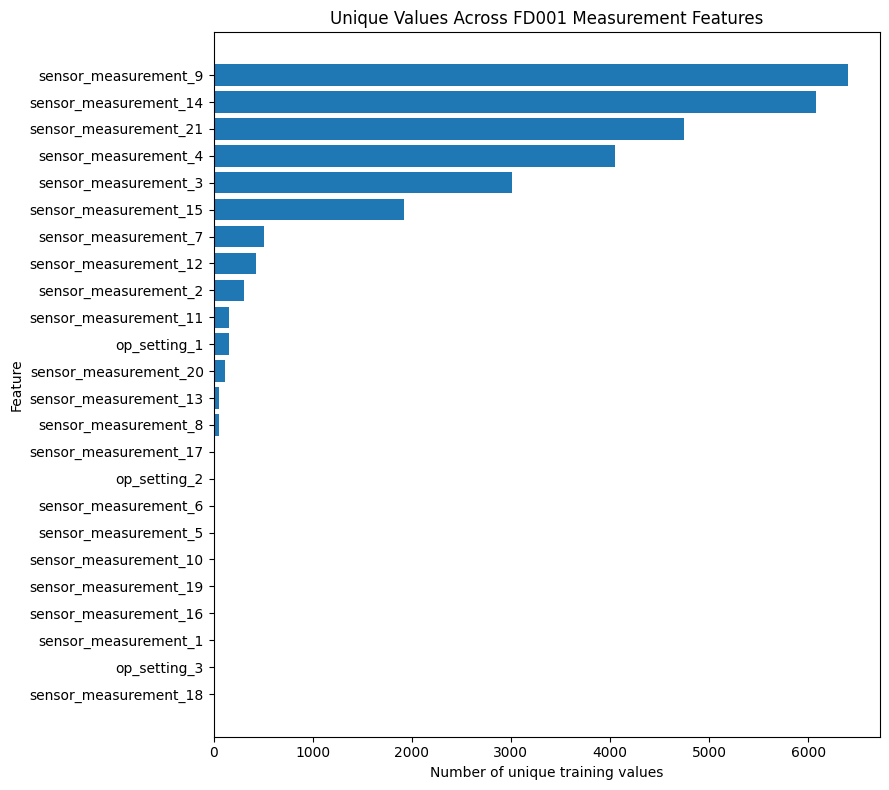

In [83]:
# --- Visualize the number of unique training values for each measurement feature ---

unique_value_counts = (
    train_variability["unique_values"]
    .sort_values()
)

plt.figure(figsize=(9, 8))
plt.barh(
    unique_value_counts.index,
    unique_value_counts.values,
)

plt.xlabel("Number of unique training values")
plt.ylabel("Feature")
plt.title("Unique Values Across FD001 Measurement Features")
plt.tight_layout()
plt.show()

In [84]:
# --- Define the measurement features retained after removing exact constants ---

baseline_measurement_features = [
    feature
    for feature in candidate_measurement_columns
    if feature not in constant_train_features
]

print(
    f"Original measurement features: "
    f"{len(candidate_measurement_columns)}"
)

print(
    f"Constant features removed: "
    f"{len(constant_train_features)}"
)

print(
    f"Measurement features retained: "
    f"{len(baseline_measurement_features)}"
)

Original measurement features: 24
Constant features removed: 7
Measurement features retained: 17


In [85]:
# --- Display the proposed baseline measurement feature set ---

baseline_feature_decision = pd.DataFrame(
    {
        "feature": candidate_measurement_columns,
        "decision": [
            "remove: constant in training"
            if feature in constant_train_features
            else (
                "retain: near-constant candidate"
                if feature in near_constant_features.index
                else "retain"
            )
            for feature in candidate_measurement_columns
        ],
    }
)

baseline_feature_decision

,feature,decision
0,op_setting_1,retain
1,op_setting_2,retain
2,op_setting_3,remove: constant in training
3,sensor_measurement_1,remove: constant in training
4,sensor_measurement_2,retain
5,sensor_measurement_3,retain
6,sensor_measurement_4,retain
7,sensor_measurement_5,remove: constant in training
8,sensor_measurement_6,retain: near-constant candidate
9,sensor_measurement_7,retain


### Near-constant feature policy

Exactly constant training features can be removed because they contain no variation from which a supervised model could learn.

Near-constant features will be retained initially.

A feature with rare variation could still contain useful degradation information, particularly if its uncommon values occur systematically near failure. Removing such features based only on low variability could discard predictive signal.

The value of near-constant features can be evaluated later through controlled feature-ablation experiments.

### Variability does not equal predictive value

This analysis determines whether features vary, not whether their variation predicts RUL.

A highly variable sensor may contain mostly noise, while a sensor with relatively small changes could contain a strong degradation trend.

Predictive usefulness will therefore be investigated through within-engine trajectories, modeling experiments, and later feature ablations rather than inferred from variance alone.

Which measurement features are exactly constant in the training data?
There are 7 of them. One operation setting and 6 sensor measurements. 

op_setting_3
sensor_measurement_1
sensor_measurement_5
sensor_measurement_10
sensor_measurement_16
sensor_measurement_18
sensor_measurement_19

Are the same features also constant in the test data? Are there any differences?
The contant features in the test data were found to be: 

Number of constant test features: 7
op_setting_3
sensor_measurement_1
sensor_measurement_5
sensor_measurement_10
sensor_measurement_16
sensor_measurement_18
sensor_measurement_19

So yes, it's a match and there are no differences.


Why can an exactly constant training feature safely be removed from the predictive feature set?
Because it has zero variance, it also causes zero change to predictions. A prediction that gets made will be the same with or without that training feature in the dataset.

**An exactly constant feature contains no information that distinguishes one training observation from another, so it cannot help the model learn differences in RUL.**

Which features were flagged as near-constant candidates by our screening rule?
Sensor measurement 6 was flagged as near constant.

What specifically makes those features “near constant” rather than exactly constant?
Exactly constant features have strictly one unique value. Sensor 6 has exactly two unique values, resulting in a nonzero variance.

Why are we keeping the near-constant features initially instead of removing them now?
Because we do not have sufficient evidence that they will have a negligible effect on predictions.

Why would a feature that is constant in training but varies in test still be unusable to the trained model?
Yes, because the model was blind to any variations in that feature. 

Does a sensor having many unique values or high variance mean it is useful for predicting RUL? Why or why not?
Yes, zero variance means zero value to predictive capabilities. High variance means high value to predictive capabilities. 

**Zero variance guarantees no predictive value from variation. High variance does not guarantee predictive value.**

How many of the original 24 measurement features remain after removing exact constants?
17

Was your earlier hypothesis about Sensor 16 correct?
Yes. 

Anything surprising or confusing?
I'm having trouble answering the question about high variance being desirable or undesirable for prediction capapbilities.

### Findings

- Seven of the 24 measurement features are exactly constant throughout the FD001 training data:
  - `op_setting_3`
  - `sensor_measurement_1`
  - `sensor_measurement_5`
  - `sensor_measurement_10`
  - `sensor_measurement_16`
  - `sensor_measurement_18`
  - `sensor_measurement_19`
- The same seven features are also constant in the test data.
- Sensor 6 is not constant but was flagged as a near-constant candidate because its observations are highly concentrated across only two unique values.
- Removing the seven exact constants leaves 17 candidate measurement features.
- Feature variability differs substantially across the remaining measurements.
- Variability alone does not establish predictive usefulness.

### Modeling implications

- Exactly constant training features should be removed from the baseline predictive feature set because they cannot distinguish among training observations.
- Near-constant features should be retained initially because rare variation may still contain useful degradation information.
- Sensor 6 should therefore remain in the initial feature set and can later be evaluated through controlled feature-ablation experiments.
- Feature-selection decisions should be based on training data rather than relying on variation that appears only in the test set.
- High variance should not be interpreted as high predictive value; the relationship between feature behavior and degradation must be examined separately.
- The baseline measurement feature set currently contains 17 nonconstant features.

## 6. Global distributions

### Question

What do the global distributions of the nonconstant operating settings and sensor measurements look like, and how similar are those distributions between the training and test populations?

### Why this matters

Global feature distributions reveal differences in numerical scale, skewness, concentration, discreteness, and train/test coverage.

These characteristics can influence preprocessing and help identify features that deserve closer investigation.

However, global distributions collapse observations from all engines and operating cycles together. They therefore cannot determine whether a feature changes systematically as an individual engine approaches failure.

In [86]:
# --- Confirm the nonconstant measurement features used for distribution analysis ---

print(f"Number of retained measurement features: {len(baseline_measurement_features)}")

baseline_measurement_features

Number of retained measurement features: 17


['op_setting_1',
 'op_setting_2',
 'sensor_measurement_2',
 'sensor_measurement_3',
 'sensor_measurement_4',
 'sensor_measurement_6',
 'sensor_measurement_7',
 'sensor_measurement_8',
 'sensor_measurement_9',
 'sensor_measurement_11',
 'sensor_measurement_12',
 'sensor_measurement_13',
 'sensor_measurement_14',
 'sensor_measurement_15',
 'sensor_measurement_17',
 'sensor_measurement_20',
 'sensor_measurement_21']

In [87]:
# --- Summarize global training distributions for retained measurement features ---

distribution_summary = pd.DataFrame(
    {
        "mean": train_df[baseline_measurement_features].mean(),
        "std": train_df[baseline_measurement_features].std(),
        "min": train_df[baseline_measurement_features].min(),
        "q25": train_df[baseline_measurement_features].quantile(0.25),
        "median": train_df[baseline_measurement_features].median(),
        "q75": train_df[baseline_measurement_features].quantile(0.75),
        "max": train_df[baseline_measurement_features].max(),
        "skew": train_df[baseline_measurement_features].skew(),
        "unique_values": train_df[baseline_measurement_features].nunique(),
    }
)

distribution_summary["iqr"] = (
    distribution_summary["q75"]
    - distribution_summary["q25"]
)

distribution_summary

,mean,std,min,q25,median,q75,max,skew,unique_values,iqr
op_setting_1,-0.000009,0.002187,-0.0087,-0.0015,0.0000,0.0015,0.0087,-0.024766,158,0.0030
op_setting_2,0.000002,0.000293,-0.0006,-0.0002,0.0000,0.0003,0.0006,0.009085,13,0.0005
sensor_measurement_2,642.680934,0.500053,641.2100,642.3250,642.6400,643.0000,644.5300,0.316526,310,0.6750
sensor_measurement_3,1590.523119,6.131150,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100,0.308946,3012,8.1200
sensor_measurement_4,1408.933782,9.000605,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900,0.443194,4051,12.1950
sensor_measurement_6,21.609803,0.001389,21.6000,21.6100,21.6100,21.6100,21.6100,-6.916813,2,0.0000
sensor_measurement_7,553.367711,0.885092,549.8500,552.8100,553.4400,554.0100,556.0600,-0.394329,513,1.2000
sensor_measurement_8,2388.096652,0.070985,2387.9000,2388.0500,2388.0900,2388.1400,2388.5600,0.479411,53,0.0900
sensor_measurement_9,9065.242941,22.082880,9021.7300,9053.1000,9060.6600,9069.4200,9244.5900,2.555365,6403,16.3200
sensor_measurement_11,47.541168,0.267087,46.8500,47.3500,47.5100,47.7000,48.5300,0.469329,159,0.3500


In [88]:
# --- Rank retained features by absolute distribution skewness ---

skew_summary = (
    distribution_summary[["skew"]]
    .assign(abs_skew=lambda df: df["skew"].abs())
    .sort_values("abs_skew", ascending=False)
)

skew_summary

,skew,abs_skew
sensor_measurement_6,-6.916813,6.916813
sensor_measurement_9,2.555365,2.555365
sensor_measurement_14,2.372554,2.372554
sensor_measurement_8,0.479411,0.479411
sensor_measurement_13,0.469792,0.469792
sensor_measurement_11,0.469329,0.469329
sensor_measurement_4,0.443194,0.443194
sensor_measurement_12,-0.442407,0.442407
sensor_measurement_7,-0.394329,0.394329
sensor_measurement_15,0.388259,0.388259


In [89]:
# --- Compare numerical scales across retained measurement features ---

scale_summary = distribution_summary[
    [
        "min",
        "max",
        "mean",
        "std",
        "iqr",
    ]
].copy()

scale_summary["range"] = (
    scale_summary["max"]
    - scale_summary["min"]
)

scale_summary.sort_values(
    "range",
    ascending=False,
)

,min,max,mean,std,iqr,range
sensor_measurement_9,9021.7300,9244.5900,9065.242941,22.082880,16.3200,222.8600
sensor_measurement_14,8099.9400,8293.7200,8143.752722,19.076176,15.0650,193.7800
sensor_measurement_4,1382.2500,1441.4900,1408.933782,9.000605,12.1950,59.2400
sensor_measurement_3,1571.0400,1616.9100,1590.523119,6.131150,8.1200,45.8700
sensor_measurement_17,388.0000,400.0000,393.210654,1.548763,2.0000,12.0000
sensor_measurement_7,549.8500,556.0600,553.367711,0.885092,1.2000,6.2100
sensor_measurement_12,518.6900,523.3800,521.413470,0.737553,0.9900,4.6900
sensor_measurement_2,641.2100,644.5300,642.680934,0.500053,0.6750,3.3200
sensor_measurement_11,46.8500,48.5300,47.541168,0.267087,0.3500,1.6800
sensor_measurement_20,38.1400,39.4300,38.816271,0.180746,0.2500,1.2900


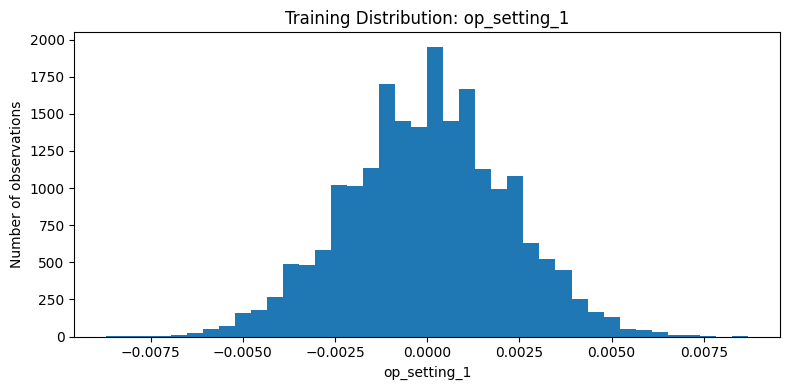

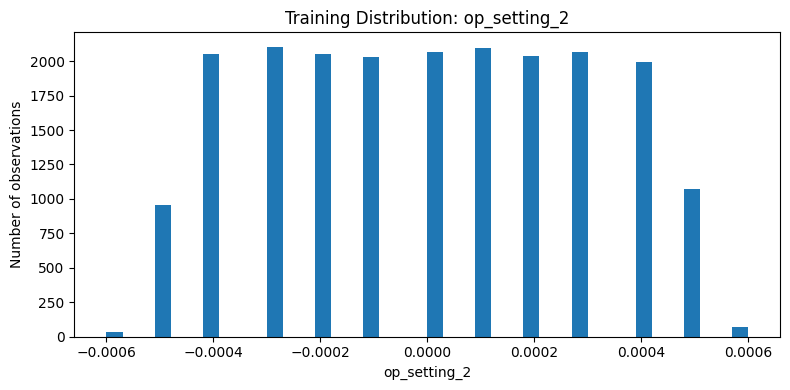

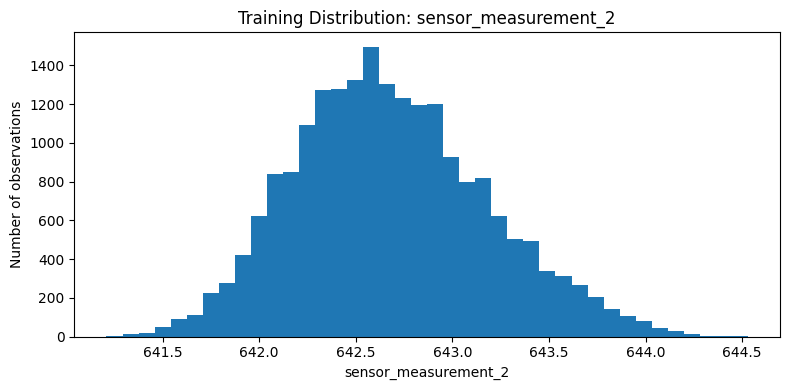

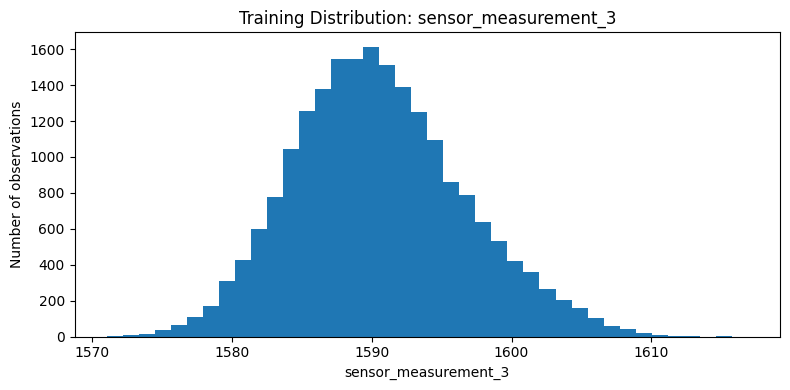

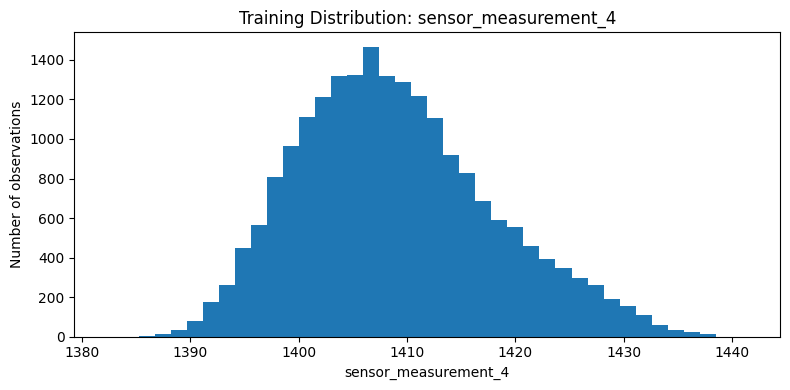

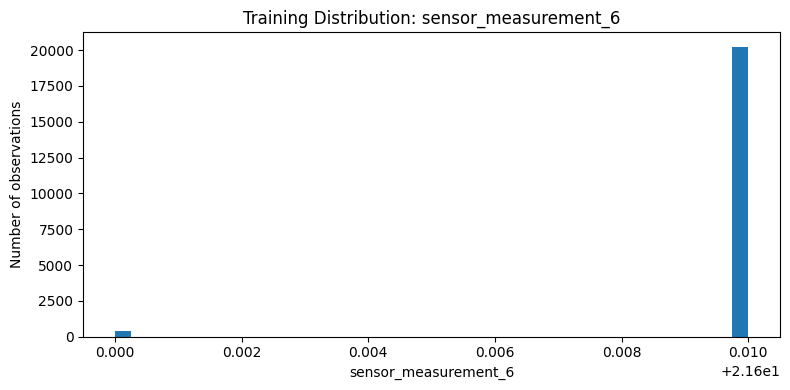

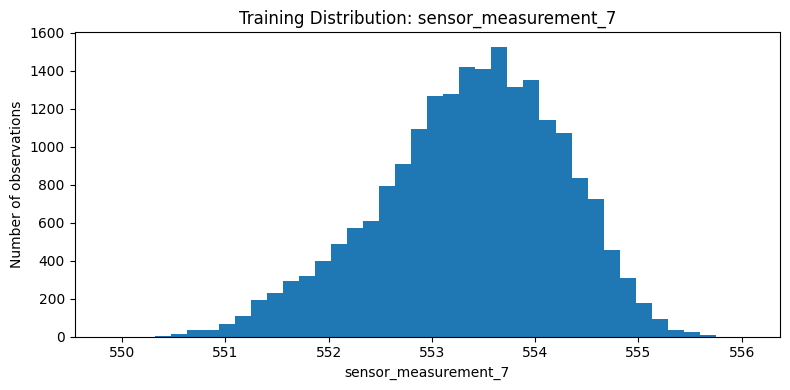

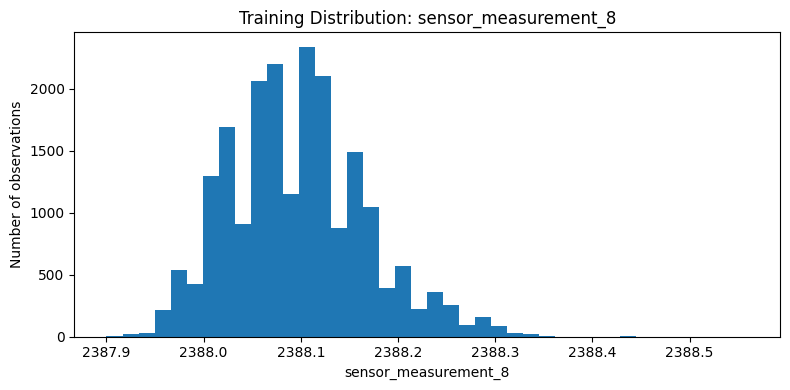

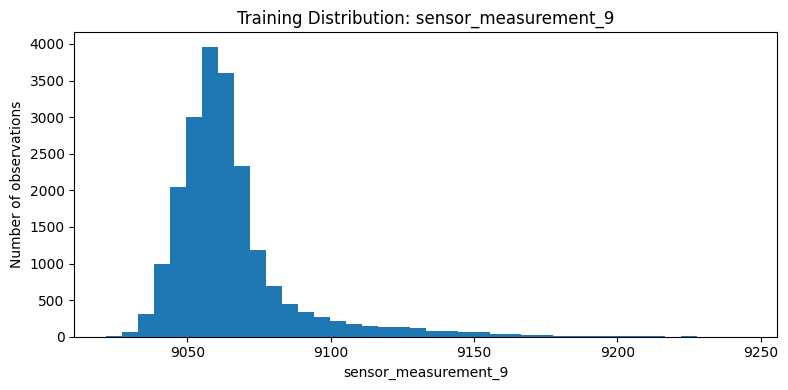

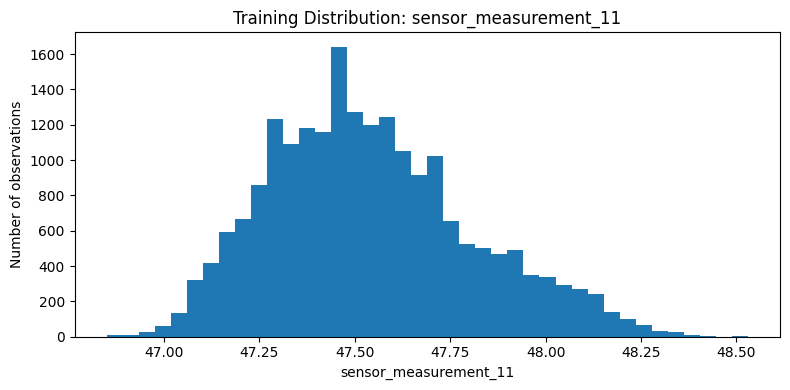

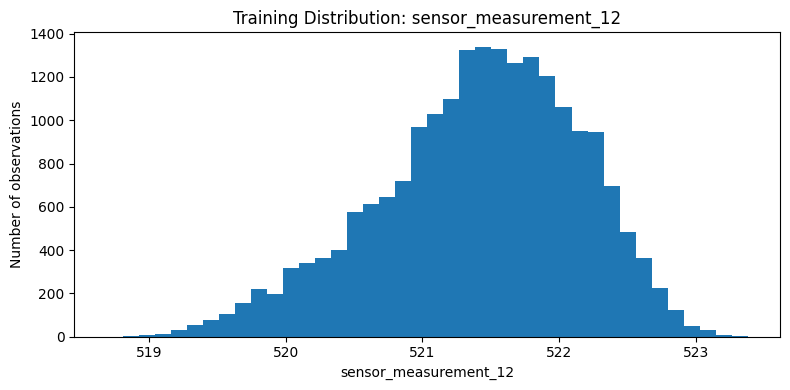

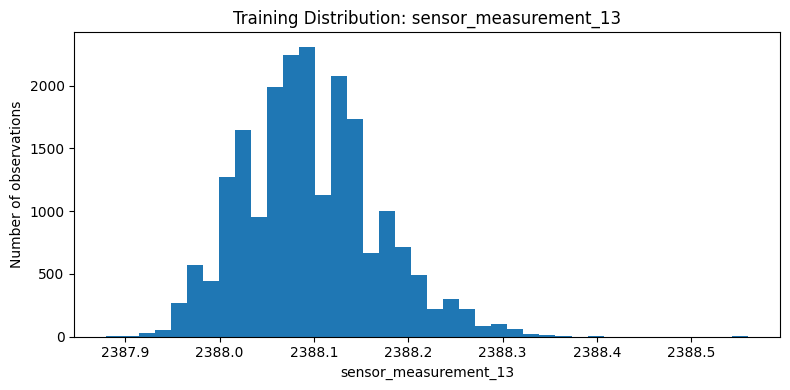

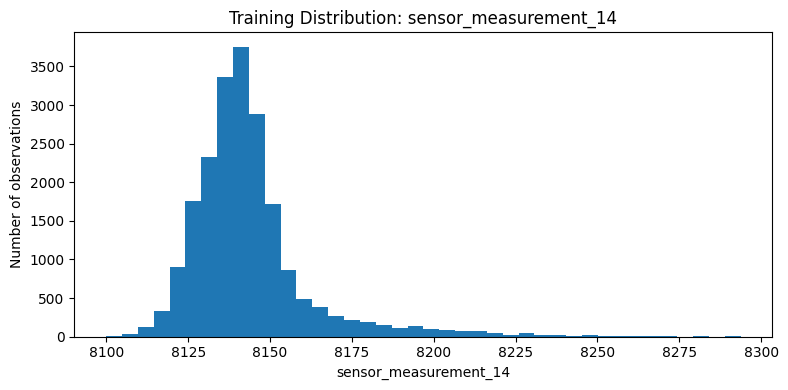

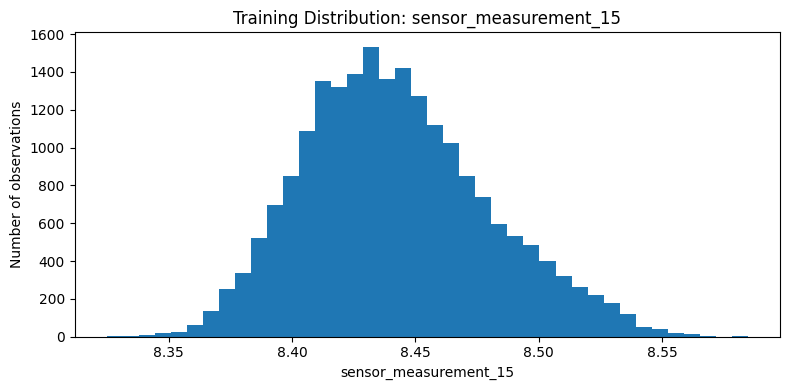

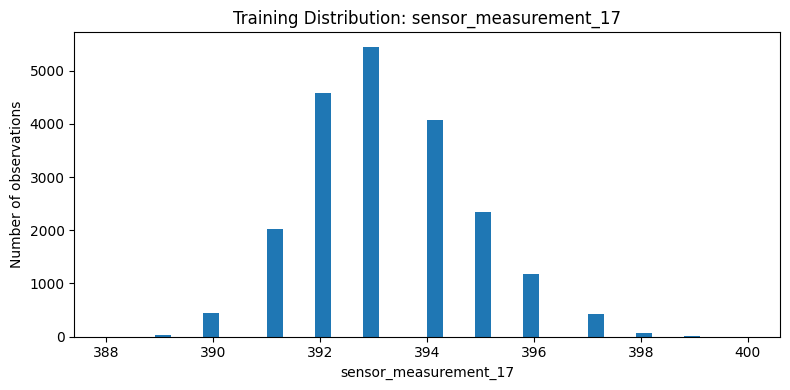

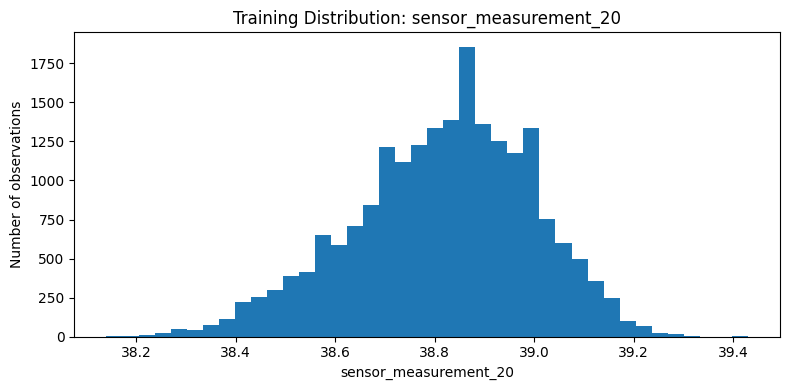

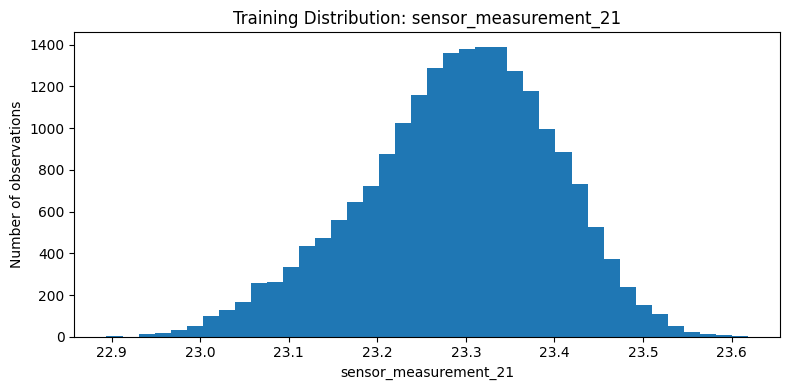

In [90]:
# --- Plot the global training distribution of each retained measurement feature ---

for feature in baseline_measurement_features:
    plt.figure(figsize=(8, 4))

    plt.hist(
        train_df[feature],
        bins=40,
    )

    plt.xlabel(feature)
    plt.ylabel("Number of observations")
    plt.title(f"Training Distribution: {feature}")
    plt.tight_layout()
    plt.show()

In [91]:
# --- Inspect the global frequency distribution of near-constant Sensor 6 ---

sensor_6_counts = (
    train_df["sensor_measurement_6"]
    .value_counts()
    .sort_index()
)

sensor_6_percent = (
    train_df["sensor_measurement_6"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

sensor_6_summary = pd.DataFrame(
    {
        "count": sensor_6_counts,
        "percent": sensor_6_percent,
    }
)

sensor_6_summary

,count,percent
sensor_measurement_6,,
21.60,406,1.967912
21.61,20225,98.032088


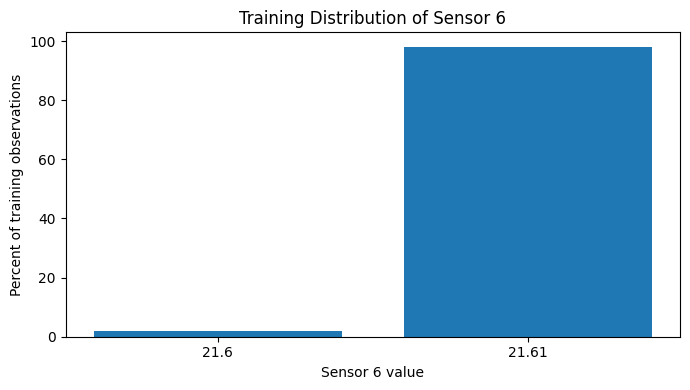

In [92]:
# --- Visualize the two observed values of Sensor 6 ---

plt.figure(figsize=(7, 4))

plt.bar(
    sensor_6_summary.index.astype(str),
    sensor_6_summary["percent"],
)

plt.xlabel("Sensor 6 value")
plt.ylabel("Percent of training observations")
plt.title("Training Distribution of Sensor 6")
plt.tight_layout()
plt.show()

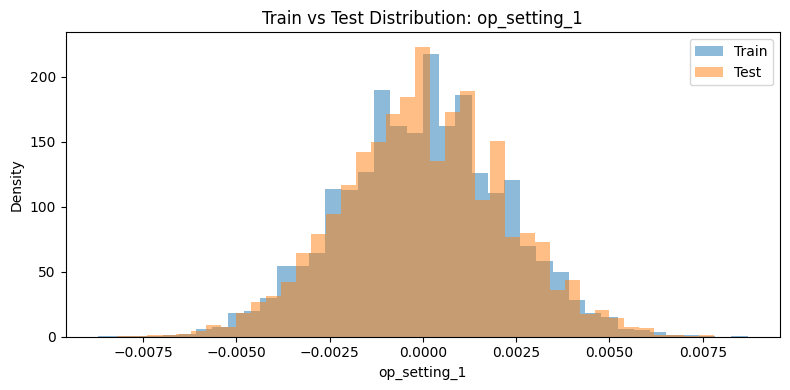

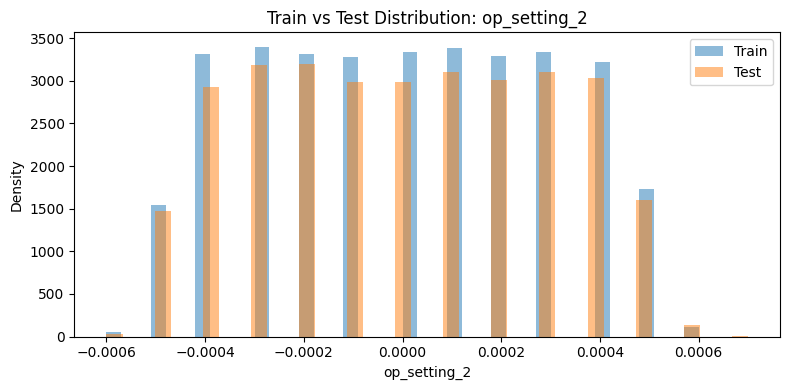

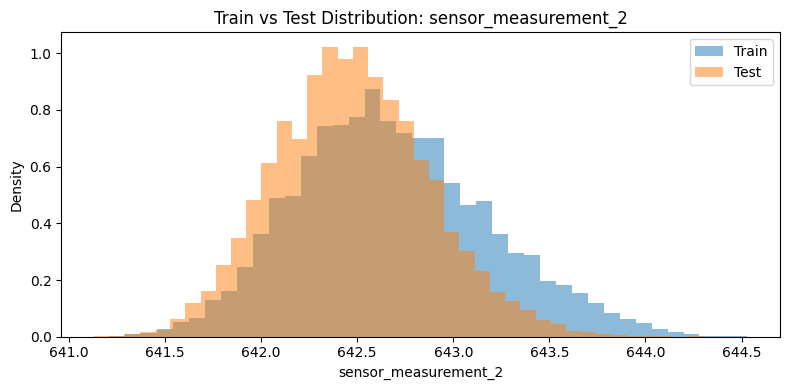

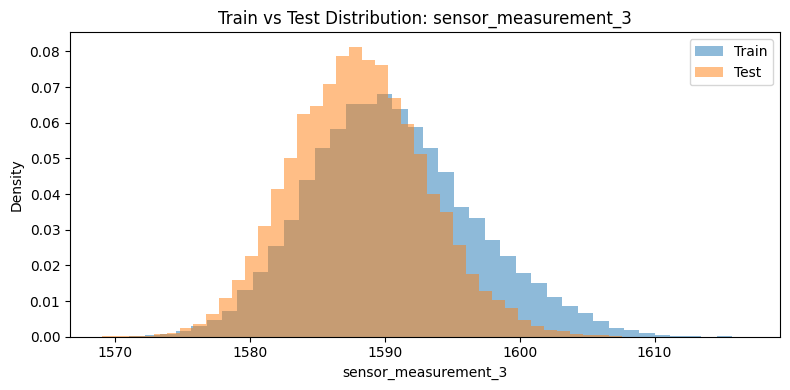

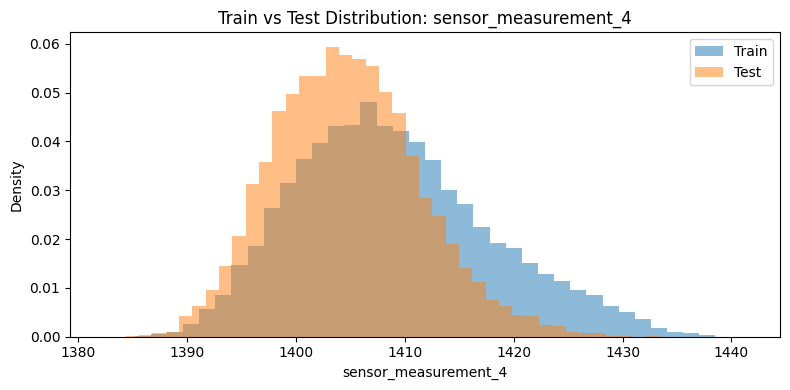

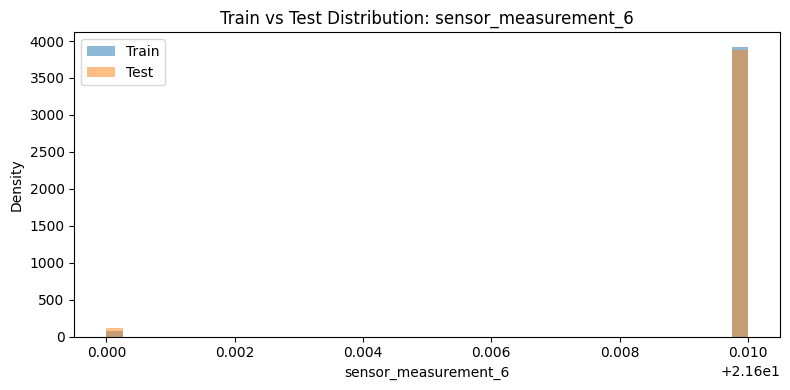

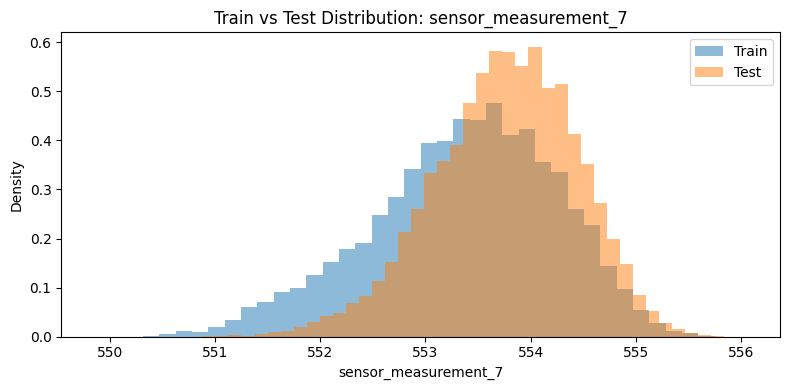

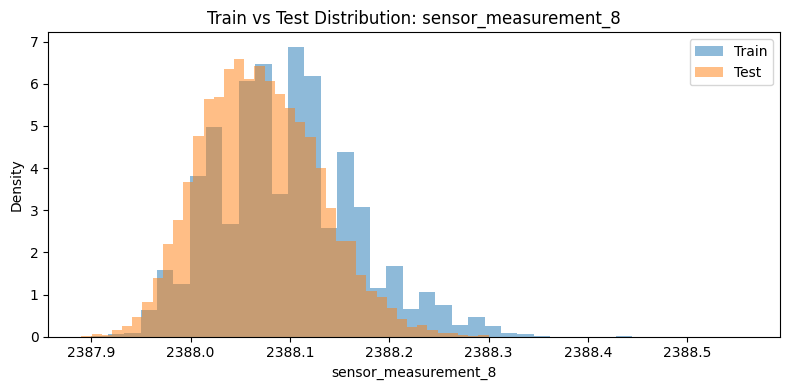

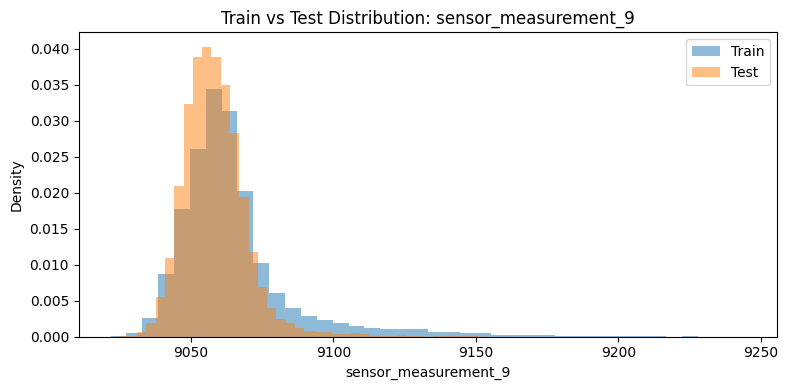

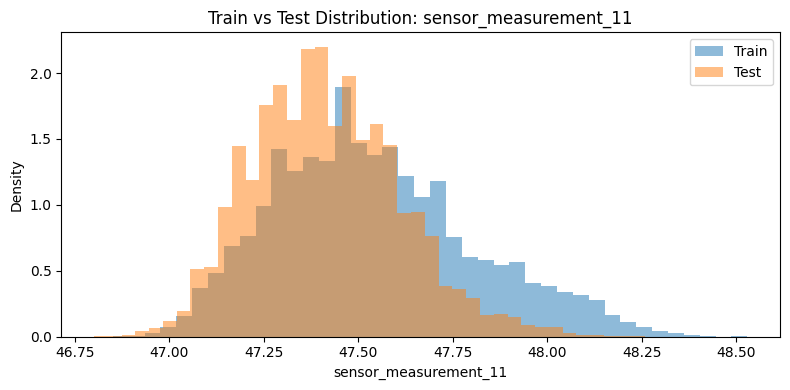

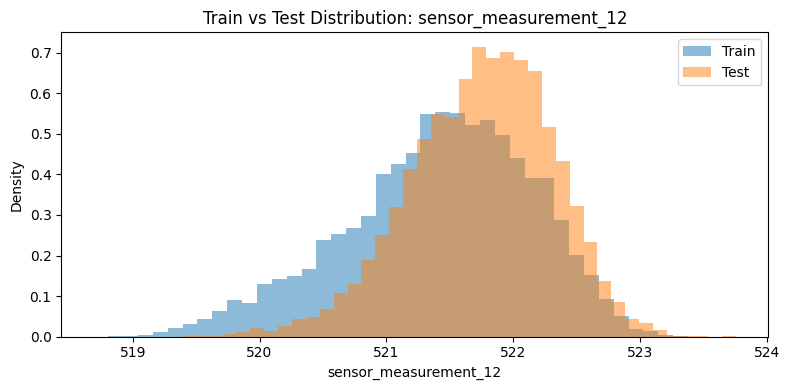

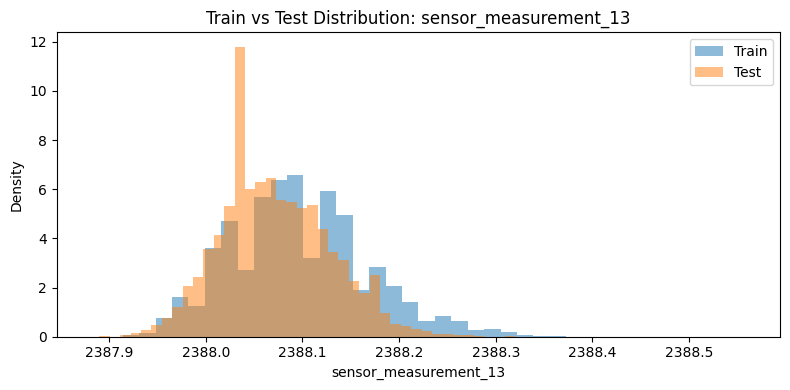

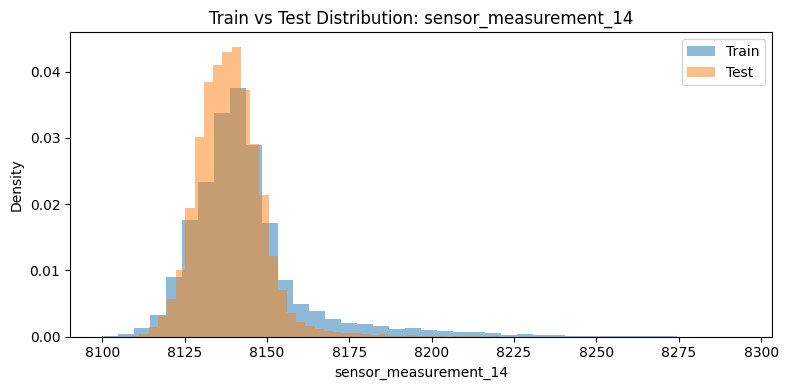

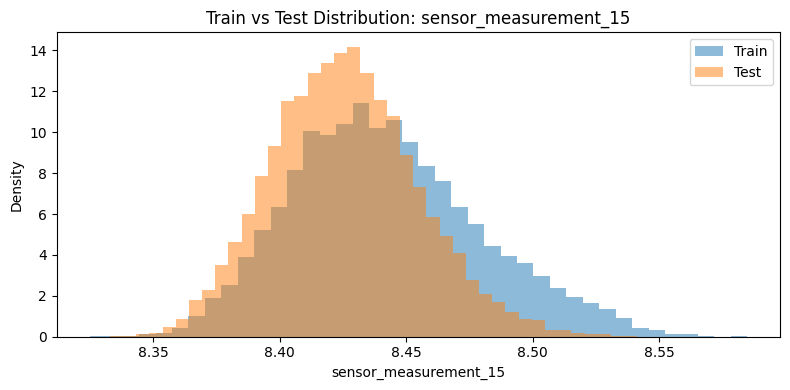

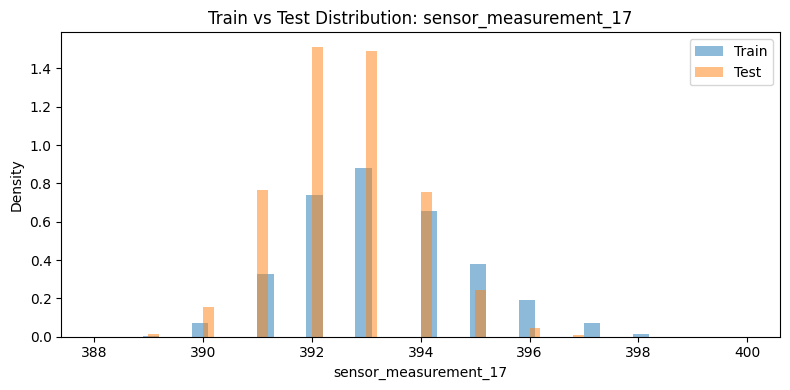

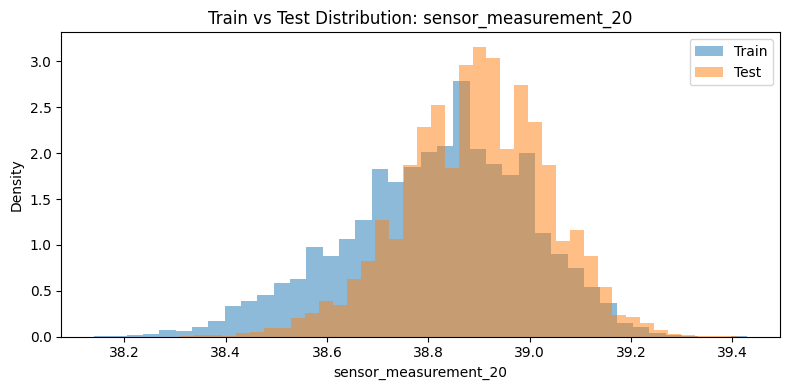

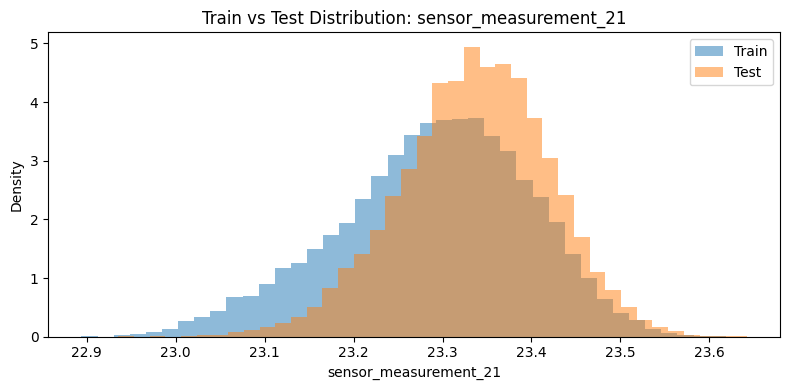

In [93]:
# --- Compare train and test distributions for each retained feature ---

for feature in baseline_measurement_features:
    plt.figure(figsize=(8, 4))

    plt.hist(
        train_df[feature],
        bins=40,
        density=True,
        alpha=0.5,
        label="Train",
    )

    plt.hist(
        test_df[feature],
        bins=40,
        density=True,
        alpha=0.5,
        label="Test",
    )

    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.title(f"Train vs Test Distribution: {feature}")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [94]:
# --- Compare train and test distribution statistics feature by feature ---

train_test_distribution_summary = pd.DataFrame(
    {
        "train_mean": train_df[baseline_measurement_features].mean(),
        "test_mean": test_df[baseline_measurement_features].mean(),
        "train_median": train_df[baseline_measurement_features].median(),
        "test_median": test_df[baseline_measurement_features].median(),
        "train_std": train_df[baseline_measurement_features].std(),
        "test_std": test_df[baseline_measurement_features].std(),
    }
)

train_test_distribution_summary["mean_difference"] = (
    train_test_distribution_summary["test_mean"]
    - train_test_distribution_summary["train_mean"]
)

train_test_distribution_summary

,train_mean,test_mean,train_median,test_median,train_std,test_std,mean_difference
op_setting_1,-0.000009,-0.000011,0.0000,0.0000,0.002187,0.002203,-0.000002
op_setting_2,0.000002,0.000004,0.0000,0.0000,0.000293,0.000294,0.000002
sensor_measurement_2,642.680934,642.475088,642.6400,642.4600,0.500053,0.400899,-0.205846
sensor_measurement_3,1590.523119,1588.099204,1590.1000,1587.9900,6.131150,5.003274,-2.423914
sensor_measurement_4,1408.933782,1404.735362,1408.0400,1404.4400,9.000605,6.688309,-4.198420
sensor_measurement_6,21.609803,21.609701,21.6100,21.6100,0.001389,0.001704,-0.000103
sensor_measurement_7,553.367711,553.757523,553.4400,553.8000,0.885092,0.681286,0.389812
sensor_measurement_8,2388.096652,2388.070964,2388.0900,2388.0700,0.070985,0.057442,-0.025687
sensor_measurement_9,9065.242941,9058.407363,9060.6600,9057.3200,22.082880,11.436261,-6.835577
sensor_measurement_11,47.541168,47.416204,47.5100,47.4100,0.267087,0.195917,-0.124964


In [95]:
# --- Standardize train/test mean differences using training variability ---

train_test_distribution_summary["standardized_mean_difference"] = (
    train_test_distribution_summary["mean_difference"]
    / train_test_distribution_summary["train_std"]
)

train_test_distribution_summary.sort_values(
    "standardized_mean_difference",
    key=lambda series: series.abs(),
    ascending=False,
)

,train_mean,test_mean,train_median,test_median,train_std,test_std,mean_difference,standardized_mean_difference
sensor_measurement_11,47.541168,47.416204,47.5100,47.4100,0.267087,0.195917,-0.124964,-0.467877
sensor_measurement_4,1408.933782,1404.735362,1408.0400,1404.4400,9.000605,6.688309,-4.198420,-0.466460
sensor_measurement_12,521.413470,521.747724,521.4800,521.7800,0.737553,0.559627,0.334254,0.453193
sensor_measurement_7,553.367711,553.757523,553.4400,553.8000,0.885092,0.681286,0.389812,0.440419
sensor_measurement_15,8.442146,8.425844,8.4389,8.4249,0.037505,0.029009,-0.016302,-0.434651
sensor_measurement_21,23.289705,23.335743,23.2979,23.3392,0.108251,0.084120,0.046037,0.425284
sensor_measurement_20,38.816271,38.892502,38.8300,38.9000,0.180746,0.141681,0.076231,0.421756
sensor_measurement_17,393.210654,392.571625,393.0000,393.0000,1.548763,1.233577,-0.639029,-0.412606
sensor_measurement_2,642.680934,642.475088,642.6400,642.4600,0.500053,0.400899,-0.205846,-0.411648
sensor_measurement_3,1590.523119,1588.099204,1590.1000,1587.9900,6.131150,5.003274,-2.423914,-0.395344


### Limitation of global distributions

A global histogram pools observations from different engines and different stages of engine life.

Therefore, two very different temporal behaviors could produce similar global distributions.

For example, a sensor might:

- gradually increase as every engine degrades,
- remain stable for most of an engine's life and change only near failure,
- fluctuate randomly around a constant level,
- or vary primarily because of operating conditions.

A global distribution alone cannot distinguish among these possibilities.

Within-engine trajectories are required to determine how sensor values evolve over operating cycles.

What major differences in numerical scale did you notice among the retained features?
The operation settings have very small numerical scales, whereas the sensor measurements have a bit more intervariance. Magnitudes range from the 10's to the 1000's. But the magnitude generally doesn't seem to cross ~10,000 across the entire dataset.

Which features appeared especially skewed or asymmetric?
There are 3 measurements that have noteworthy skew: 
sensor_measurement_6	-6.916813	6.916813
sensor_measurement_9	2.555365	2.555365
sensor_measurement_14	2.372554	2.372554

Which distributions looked roughly smooth/continuous, and which looked highly concentrated or discrete?
Sensor measurements 2, 3, and 4 seemed especially smooth and continuous. 
Operation setting 2 with sensor measurements 6 and 17 seemed highly discrete.

What did Sensor 6's distribution show about why we called it near constant?
There is a small number of points preventing that sensor from having strictly one unique value.

Did any features appear obviously multimodal? If so, which ones?
Operation setting 2 with sensor measurements 6 and 17 seemed highly discreet, which could also be stated as being multimodal.

**Operating Setting 2 and Sensors 6 and 17 appear strongly discretized or concentrated into a small number of values. Some may also show multiple peaks, but discreteness alone does not establish multimodality.**

How similar did the train and test distributions look overall? Were there particular features with noticeable differences?
They seemed reasonably matched. But some of the ones that took on a gaussian distributions had a visible lack of overlap. And Sensor measurement 13 had a set of measurements that were very high in clustered number in a way that was not seeing in the training set.

Which features had the largest standardized train/test mean differences?
9, 14, and 4 among the sensor measurements had the highest train/test differences in mean.

Why shouldn't we immediately call those differences “data drift”?
Because there could be other factors, such as the measurements naturally posting much larger quantities than most others in the dataset. That would naturally make the differences in mean larger between train and test sets.

**Train and test contain different mixtures of lifecycle stages. Training trajectories run all the way to failure, while test trajectories are truncated at varying points before failure. Therefore, their row-level feature distributions can differ even if they come from the same underlying process.**

Why doesn't a global histogram tell us whether a sensor contains degradation signal?
Because degradation is a phenomenon that takes place with a temporal component. In a global histogram were are blind to which part of the lifecycle points came from.

Do any of these distribution results currently justify removing additional features?
No. The only one that was on the cusp of being removed was sensor measurement 6, but we do not know the reason behind the lack of a single unique value in that set of the data. So it wouldn't be good to remove it just yet.

Anything surprising or confusing?
No, I think I didn't struggle much answering this batch of questions.

### Findings

- The retained measurement features operate on substantially different numerical scales.
- Several sensors have approximately smooth, continuous-looking global distributions, while others are highly concentrated or take relatively few distinct values.
- Sensor 6 is strongly near-constant: almost all observations share one value, with a small number taking a second value.
- Sensors 6, 9, and 14 show comparatively strong global skew.
- Train and test distributions are broadly similar for many features, but several sensors show noticeable differences in mean or shape.
- Sensors 9, 14, and 4 show some of the largest standardized train/test mean differences.
- Sensor 13 shows a visible test-distribution concentration that warrants later contextual inspection.
- Discrete feature behavior should not be confused automatically with multimodality.

### Modeling implications

- Feature scale differences may matter for models that are sensitive to feature magnitude, so preprocessing decisions should depend on the model family used.
- Global skewness, variance, or visual prominence should not be interpreted as predictive usefulness.
- Train/test marginal differences should not automatically be labeled data drift because the training and test datasets contain different mixtures of engine lifecycle stages.
- Sensor 6 should remain in the candidate feature set until its rare variation is examined in temporal context or through later ablation experiments.
- No additional features should be removed based on global distributions alone.
- Within-engine trajectories are required to determine whether sensor variation is systematically related to degradation.

## 7. Within-engine trajectories and degradation signal

### Question

How do individual sensor measurements evolve over an engine's operating life, and which sensors appear to contain temporal patterns that could help predict remaining useful life?

### Why this matters

Global distributions pool observations from different engines and lifecycle stages together.

Predictive maintenance is inherently temporal: useful degradation signal should appear as systematic changes within an engine's history as it approaches failure.

Inspecting within-engine trajectories can reveal:

- gradual degradation trends,
- late-life changes,
- stable or noisy sensors,
- differences between engines,
- and candidate sensors for temporal feature engineering.

In [96]:
# --- Select representative training engines with short, median, and long lifetimes ---

engine_lifetimes = (
    train_labeled_df
    .groupby("unit_no")["final_cycle"]
    .first()
)

short_engine = engine_lifetimes.idxmin()

median_lifetime = engine_lifetimes.median()
median_engine = (
    (engine_lifetimes - median_lifetime)
    .abs()
    .idxmin()
)

long_engine = engine_lifetimes.idxmax()

representative_engines = [
    short_engine,
    median_engine,
    long_engine,
]

print("Representative engines:", representative_engines)

display(
    engine_lifetimes.loc[representative_engines]
    .rename("lifetime")
)

Representative engines: [np.int64(39), np.int64(26), np.int64(69)]


unit_no
39    128
26    199
69    362
Name: lifetime, dtype: int64

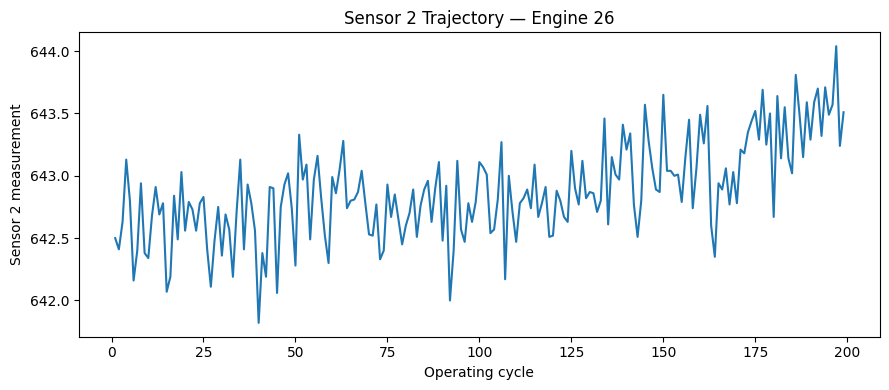

In [97]:
# --- Plot Sensor 2 across the lifetime of one example engine ---

example_unit = median_engine

example_trajectory = (
    train_labeled_df
    .loc[
        train_labeled_df["unit_no"] == example_unit,
        ["cycles", "rul", "sensor_measurement_2"],
    ]
    .sort_values("cycles")
)

plt.figure(figsize=(9, 4))

plt.plot(
    example_trajectory["cycles"],
    example_trajectory["sensor_measurement_2"],
)

plt.xlabel("Operating cycle")
plt.ylabel("Sensor 2 measurement")
plt.title(f"Sensor 2 Trajectory — Engine {example_unit}")
plt.tight_layout()
plt.show()

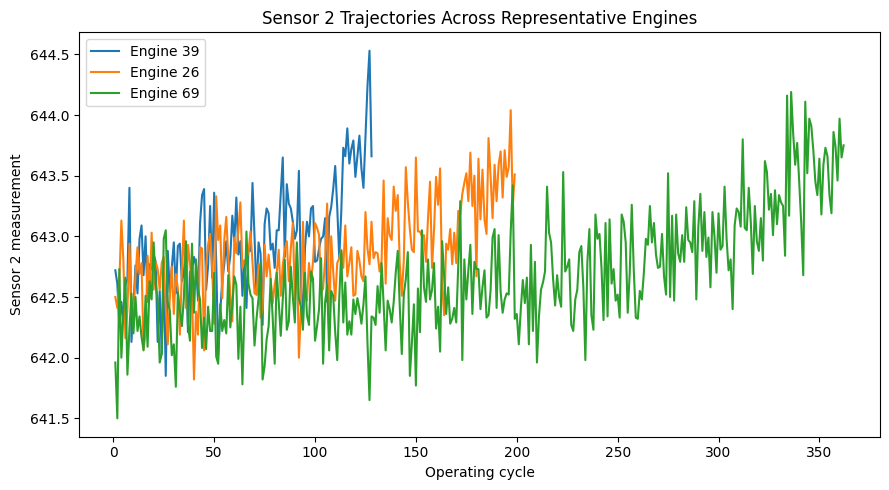

In [98]:
# --- Compare Sensor 2 trajectories across representative engines ---

plt.figure(figsize=(9, 5))

for unit in representative_engines:
    engine_data = (
        train_labeled_df
        .loc[
            train_labeled_df["unit_no"] == unit
        ]
        .sort_values("cycles")
    )

    plt.plot(
        engine_data["cycles"],
        engine_data["sensor_measurement_2"],
        label=f"Engine {unit}",
    )

plt.xlabel("Operating cycle")
plt.ylabel("Sensor 2 measurement")
plt.title("Sensor 2 Trajectories Across Representative Engines")
plt.legend()
plt.tight_layout()
plt.show()

In [99]:
# --- Create normalized lifecycle position for trajectory comparison ---

trajectory_df = train_labeled_df.copy()

trajectory_df["lifecycle_fraction"] = (
    trajectory_df["cycles"]
    / trajectory_df["final_cycle"]
)

### Leakage warning

`lifecycle_fraction` uses `final_cycle`, so it is valid only for retrospective visualization of completed training trajectories.

It must never be used as a predictive feature because the true final cycle is unknown at inference time.

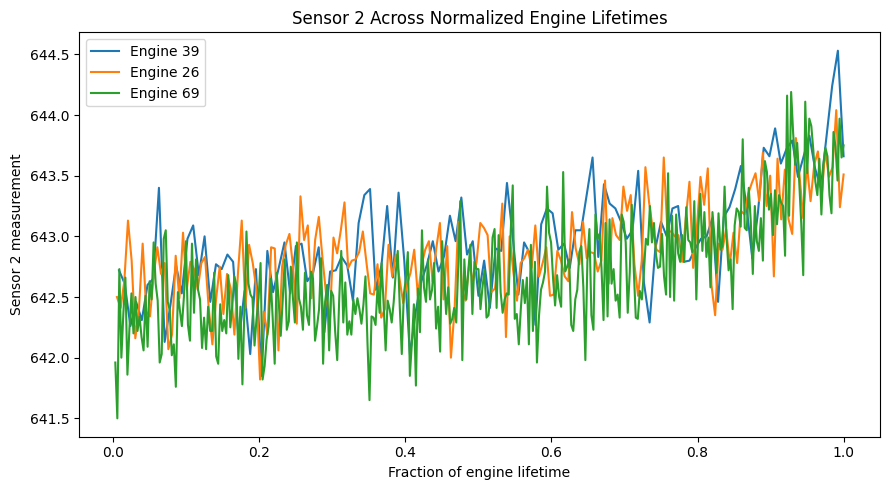

In [100]:
# --- Compare Sensor 2 against normalized lifecycle position ---

plt.figure(figsize=(9, 5))

for unit in representative_engines:
    engine_data = (
        trajectory_df
        .loc[
            trajectory_df["unit_no"] == unit
        ]
        .sort_values("lifecycle_fraction")
    )

    plt.plot(
        engine_data["lifecycle_fraction"],
        engine_data["sensor_measurement_2"],
        label=f"Engine {unit}",
    )

plt.xlabel("Fraction of engine lifetime")
plt.ylabel("Sensor 2 measurement")
plt.title("Sensor 2 Across Normalized Engine Lifetimes")
plt.legend()
plt.tight_layout()
plt.show()

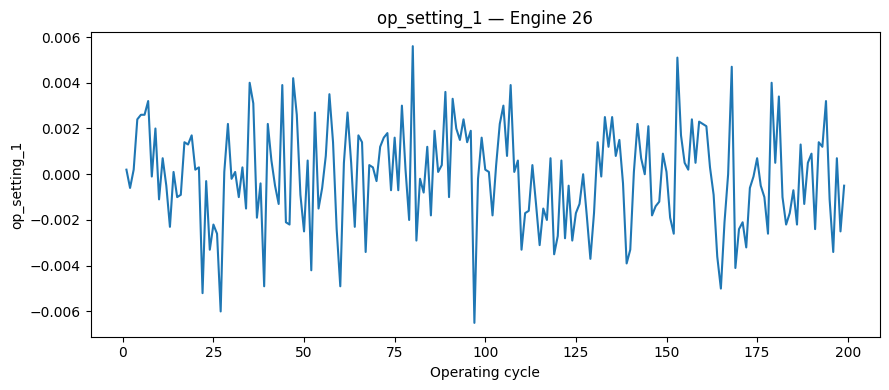

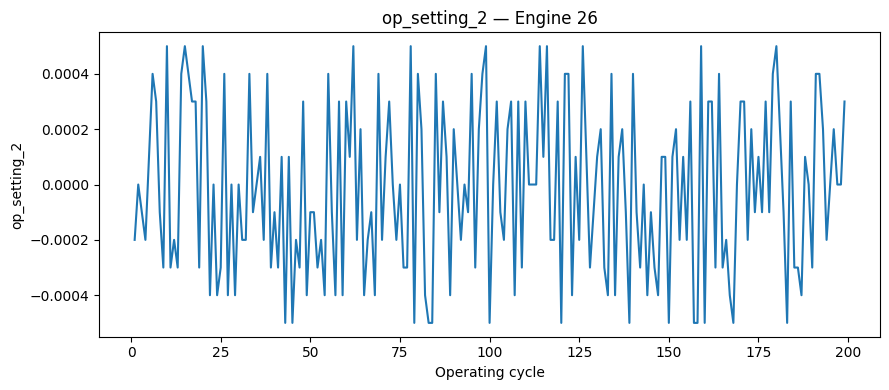

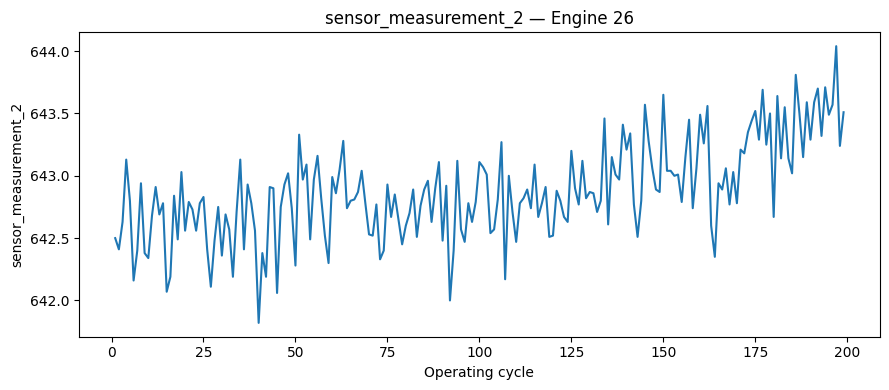

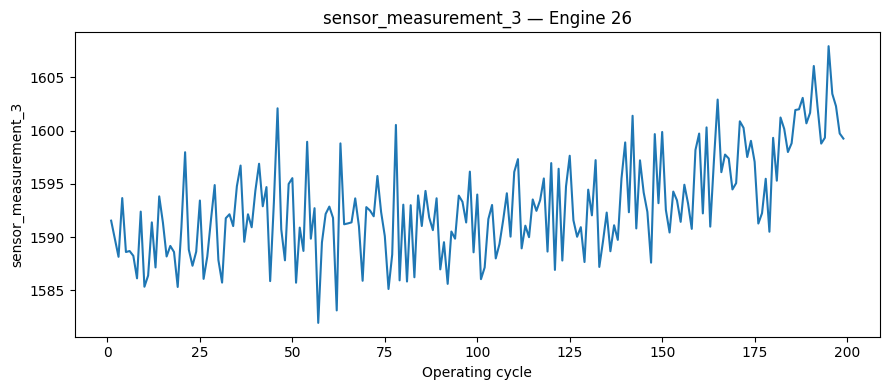

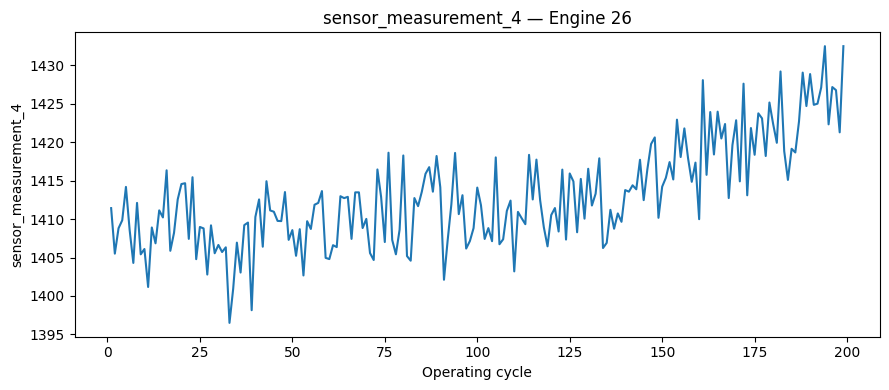

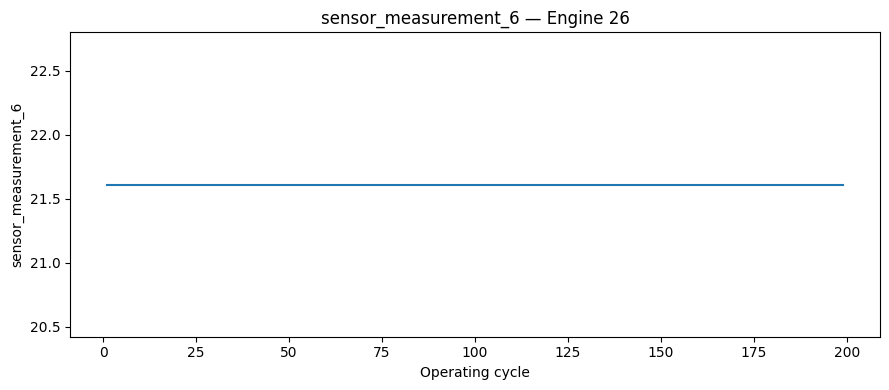

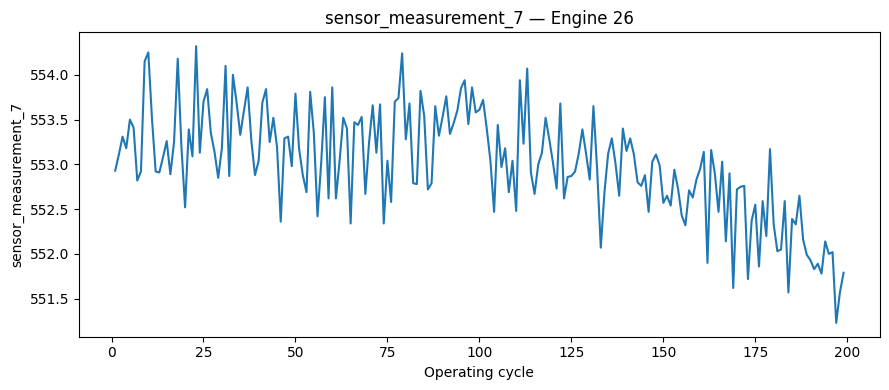

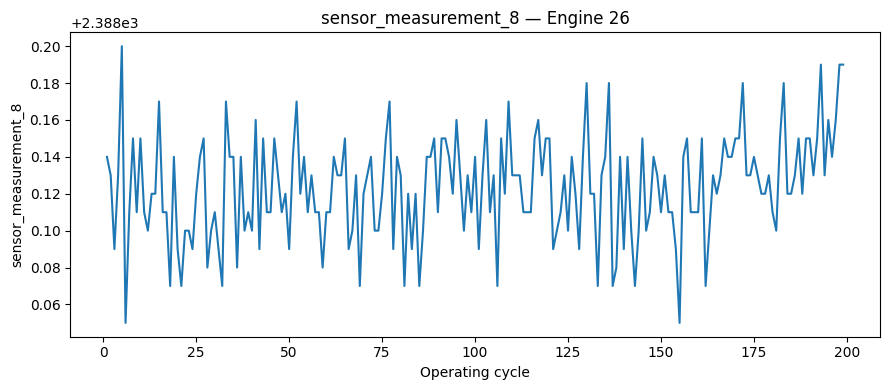

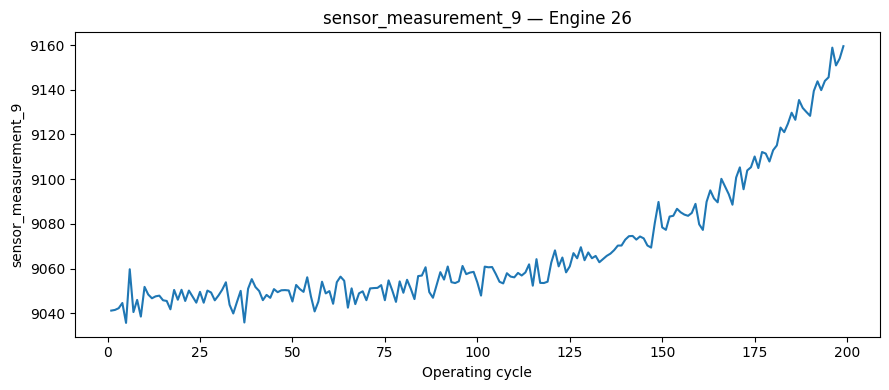

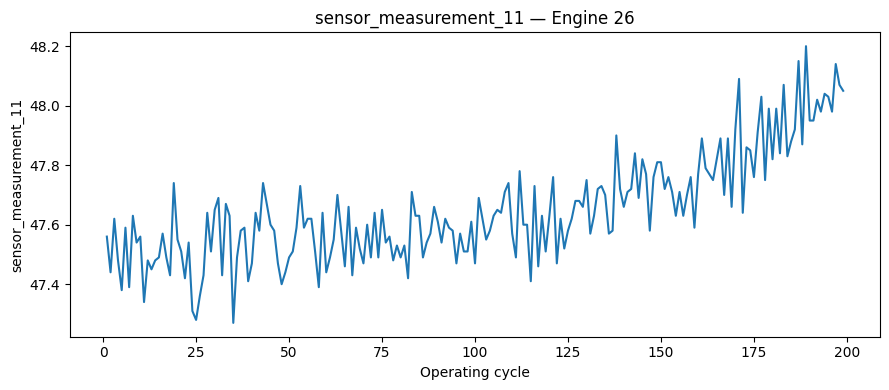

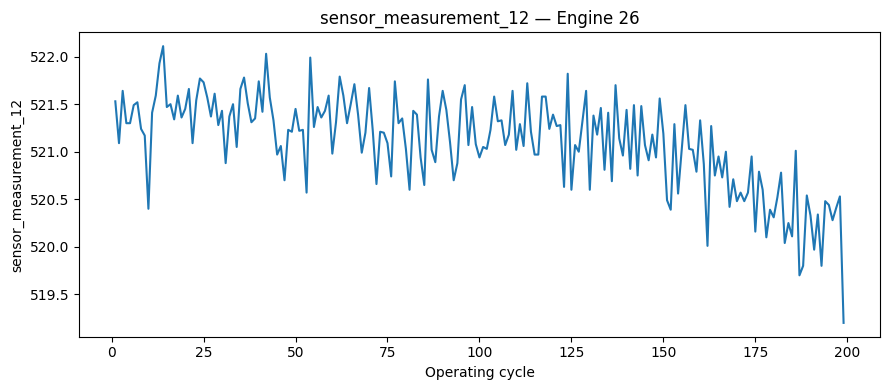

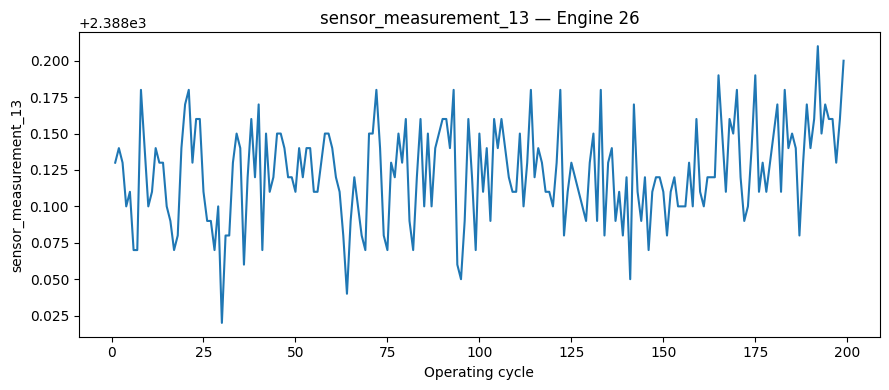

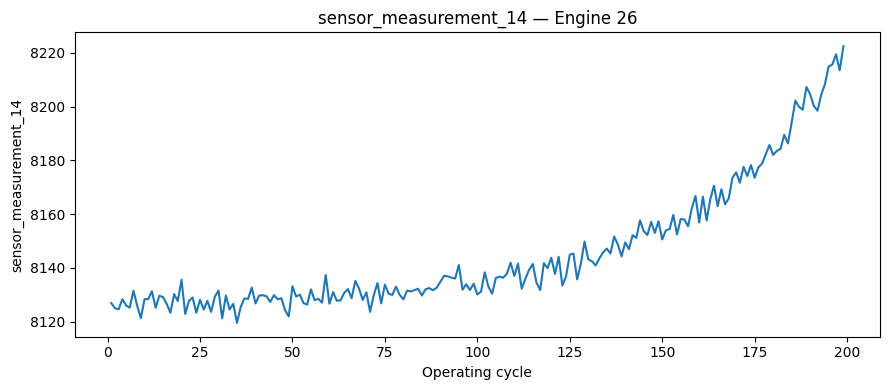

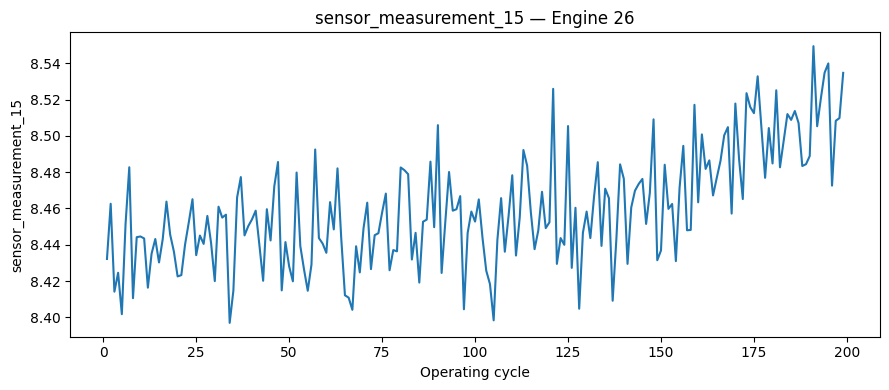

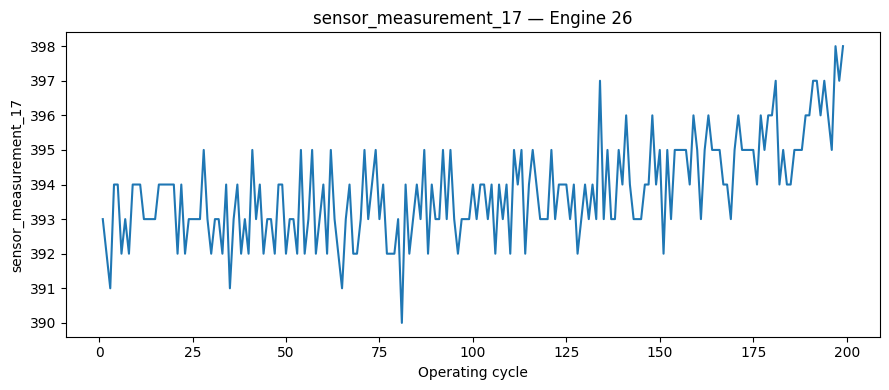

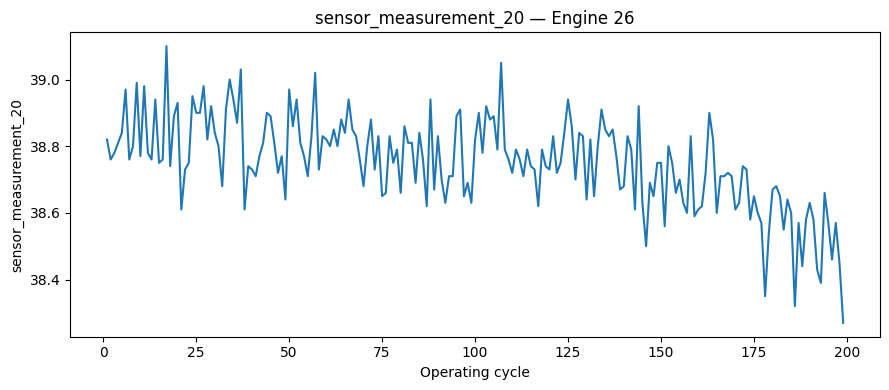

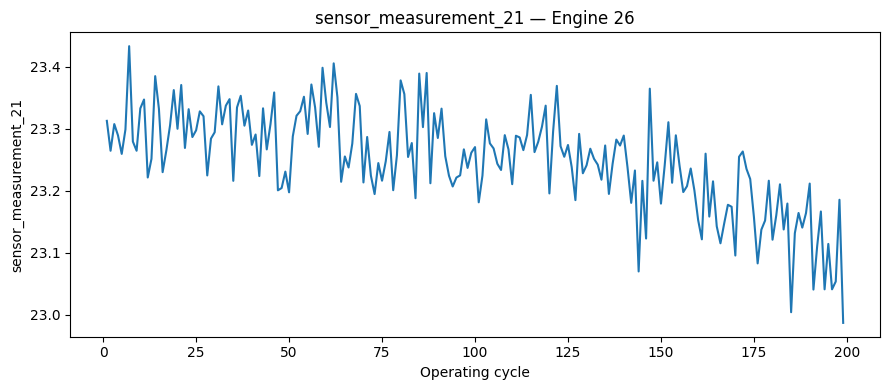

In [101]:
# --- Plot each retained measurement across one representative engine's lifetime ---

example_unit = median_engine

example_engine_data = (
    train_labeled_df
    .loc[
        train_labeled_df["unit_no"] == example_unit
    ]
    .sort_values("cycles")
)

for feature in baseline_measurement_features:
    plt.figure(figsize=(9, 4))

    plt.plot(
        example_engine_data["cycles"],
        example_engine_data[feature],
    )

    plt.xlabel("Operating cycle")
    plt.ylabel(feature)
    plt.title(f"{feature} — Engine {example_unit}")
    plt.tight_layout()
    plt.show()

In [102]:
# --- Calculate within-engine cycle correlations, handling constant trajectories ---

within_engine_correlations = []

for feature in baseline_measurement_features:
    for unit, engine_data in train_labeled_df.groupby("unit_no"):

        # Correlation is undefined if this feature is constant
        # throughout the selected engine's trajectory.
        if engine_data[feature].nunique() < 2:
            correlation = np.nan
        else:
            correlation = engine_data["cycles"].corr(
                engine_data[feature]
            )

        within_engine_correlations.append(
            {
                "feature": feature,
                "unit_no": unit,
                "cycle_correlation": correlation,
            }
        )

within_engine_correlations = pd.DataFrame(
    within_engine_correlations
)

within_engine_correlations.head()

,feature,unit_no,cycle_correlation
0,op_setting_1,1,-0.038848
1,op_setting_1,2,-0.077614
2,op_setting_1,3,0.029608
3,op_setting_1,4,-0.064539
4,op_setting_1,5,0.006900


In [103]:
# --- Summarize within-engine trend strength and correlation coverage ---

within_engine_trend_summary = (
    within_engine_correlations
    .groupby("feature")
    .agg(
        median_correlation=("cycle_correlation", "median"),
        mean_correlation=("cycle_correlation", "mean"),
        min_correlation=("cycle_correlation", "min"),
        max_correlation=("cycle_correlation", "max"),
        engines_with_valid_correlation=("cycle_correlation", "count"),
    )
)

within_engine_trend_summary["engines_with_undefined_correlation"] = (
    train_labeled_df["unit_no"].nunique()
    - within_engine_trend_summary["engines_with_valid_correlation"]
)

within_engine_trend_summary["median_abs_correlation"] = (
    within_engine_trend_summary["median_correlation"].abs()
)

within_engine_trend_summary.sort_values(
    "median_abs_correlation",
    ascending=False,
)

,median_correlation,mean_correlation,min_correlation,max_correlation,engines_with_valid_correlation,engines_with_undefined_correlation,median_abs_correlation
feature,,,,,,,
sensor_measurement_11,0.816341,0.810601,0.676283,0.870180,100,0,0.816341
sensor_measurement_12,-0.810574,-0.789662,-0.859885,-0.643126,100,0,0.810574
sensor_measurement_4,0.790356,0.781614,0.635681,0.836064,100,0,0.790356
sensor_measurement_7,-0.783062,-0.761514,-0.855186,-0.592720,100,0,0.783062
sensor_measurement_8,0.777609,0.683526,0.147402,0.855629,100,0,0.777609
sensor_measurement_13,0.774206,0.687316,0.128698,0.864538,100,0,0.774206
sensor_measurement_9,0.746635,0.385955,-0.768151,0.864349,100,0,0.746635
sensor_measurement_15,0.734957,0.724844,0.618344,0.813026,100,0,0.734957
sensor_measurement_21,-0.730344,-0.716710,-0.804916,-0.584850,100,0,0.730344


In [104]:
# --- Measure trend-direction consistency only where correlation is defined ---

valid_correlations = (
    within_engine_correlations
    .dropna(subset=["cycle_correlation"])
    .copy()
)

valid_correlations["positive"] = (
    valid_correlations["cycle_correlation"] > 0
)

valid_correlations["negative"] = (
    valid_correlations["cycle_correlation"] < 0
)

directional_consistency = (
    valid_correlations
    .groupby("feature")
    .agg(
        positive_fraction=("positive", "mean"),
        negative_fraction=("negative", "mean"),
        engines_evaluated=("unit_no", "count"),
    )
)

directional_consistency["positive_percent"] = (
    100 * directional_consistency["positive_fraction"]
)

directional_consistency["negative_percent"] = (
    100 * directional_consistency["negative_fraction"]
)

directional_consistency[
    [
        "positive_percent",
        "negative_percent",
        "engines_evaluated",
    ]
].sort_values(
    "positive_percent",
    ascending=False,
)

,positive_percent,negative_percent,engines_evaluated
feature,,,
sensor_measurement_2,100.000000,0.000000,100
sensor_measurement_3,100.000000,0.000000,100
sensor_measurement_11,100.000000,0.000000,100
sensor_measurement_8,100.000000,0.000000,100
sensor_measurement_13,100.000000,0.000000,100
sensor_measurement_15,100.000000,0.000000,100
sensor_measurement_17,100.000000,0.000000,100
sensor_measurement_4,100.000000,0.000000,100
sensor_measurement_6,98.387097,1.612903,62


In [105]:
# --- Compare early-life and late-life sensor values within each engine ---

trajectory_df["lifecycle_stage"] = pd.cut(
    trajectory_df["lifecycle_fraction"],
    bins=[0, 0.2, 0.8, 1.0],
    labels=[
        "early",
        "middle",
        "late",
    ],
    include_lowest=True,
)

early_late_summary = []

for feature in baseline_measurement_features:
    stage_means = (
        trajectory_df
        .groupby(
            ["unit_no", "lifecycle_stage"],
            observed=True,
        )[feature]
        .mean()
        .unstack()
    )

    stage_means["late_minus_early"] = (
        stage_means["late"]
        - stage_means["early"]
    )

    early_late_summary.append(
        {
            "feature": feature,
            "median_late_minus_early": (
                stage_means["late_minus_early"].median()
            ),
            "mean_late_minus_early": (
                stage_means["late_minus_early"].mean()
            ),
        }
    )

early_late_summary = pd.DataFrame(
    early_late_summary
)

early_late_summary.sort_values(
    "median_late_minus_early",
)

,feature,median_late_minus_early,mean_late_minus_early
6,sensor_measurement_7,-1.721835,-1.733609
10,sensor_measurement_12,-1.469830,-1.480071
15,sensor_measurement_20,-0.333648,-0.342949
16,sensor_measurement_21,-0.205490,-0.206677
1,op_setting_2,0.000009,0.000008
0,op_setting_1,0.000023,0.000023
5,sensor_measurement_6,0.000159,0.000427
13,sensor_measurement_15,0.072271,0.071964
7,sensor_measurement_8,0.125361,0.118055
11,sensor_measurement_13,0.126868,0.120074


In [106]:
# --- Standardize early-to-late sensor changes by training standard deviation ---

training_sensor_std = (
    train_df[baseline_measurement_features]
    .std()
)

early_late_summary["train_std"] = (
    early_late_summary["feature"]
    .map(training_sensor_std)
)

early_late_summary["standardized_late_minus_early"] = (
    early_late_summary["median_late_minus_early"]
    / early_late_summary["train_std"]
)

early_late_summary.sort_values(
    "standardized_late_minus_early",
    key=lambda series: series.abs(),
    ascending=False,
)

,feature,median_late_minus_early,mean_late_minus_early,train_std,standardized_late_minus_early
9,sensor_measurement_11,0.541692,0.555684,0.267087,2.028145
4,sensor_measurement_4,18.161383,18.284928,9.000605,2.017796
10,sensor_measurement_12,-1.469830,-1.480071,0.737553,-1.992846
6,sensor_measurement_7,-1.721835,-1.733609,0.885092,-1.945373
13,sensor_measurement_15,0.072271,0.071964,0.037505,1.926965
16,sensor_measurement_21,-0.205490,-0.206677,0.108251,-1.898278
15,sensor_measurement_20,-0.333648,-0.342949,0.180746,-1.845944
14,sensor_measurement_17,2.845286,2.824853,1.548763,1.837135
7,sensor_measurement_8,0.125361,0.118055,0.070985,1.766008
11,sensor_measurement_13,0.126868,0.120074,0.071919,1.764045


In [107]:
# --- Select sensors with the strongest typical within-engine trends ---

strong_trend_features = (
    within_engine_trend_summary
    .sort_values(
        "median_abs_correlation",
        ascending=False,
    )
    .head(5)
    .index
    .tolist()
)

strong_trend_features

['sensor_measurement_11',
 'sensor_measurement_12',
 'sensor_measurement_4',
 'sensor_measurement_7',
 'sensor_measurement_8']

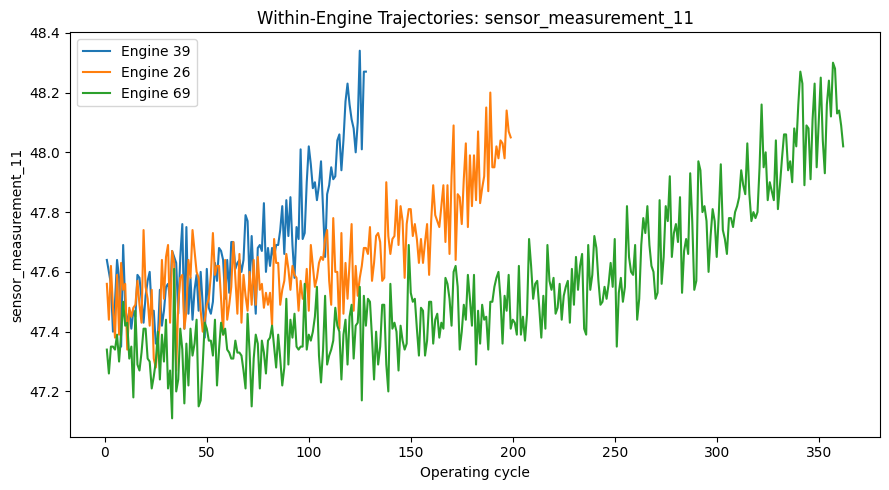

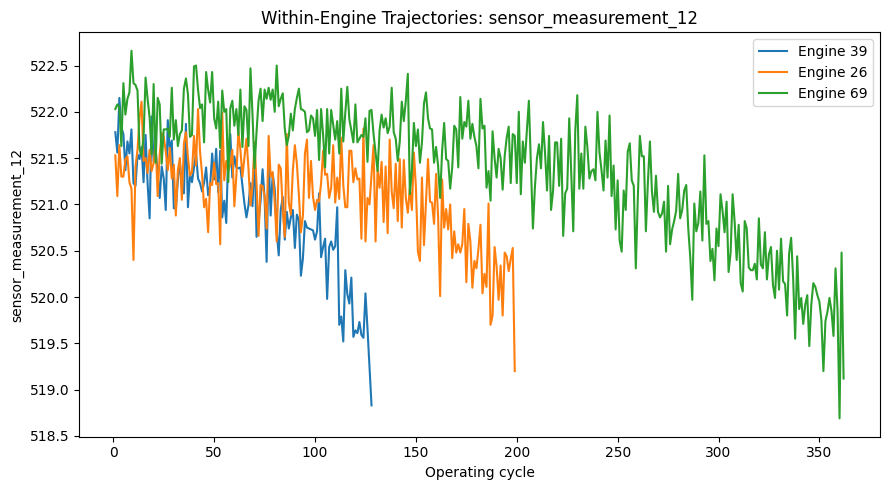

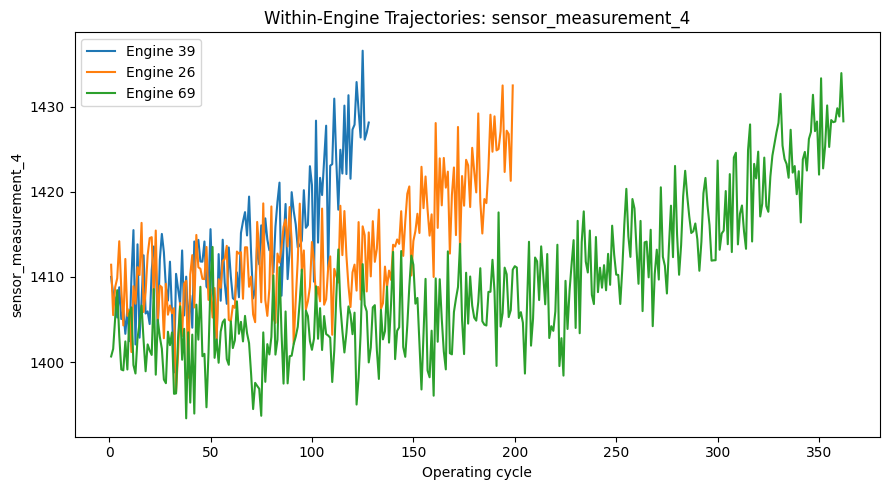

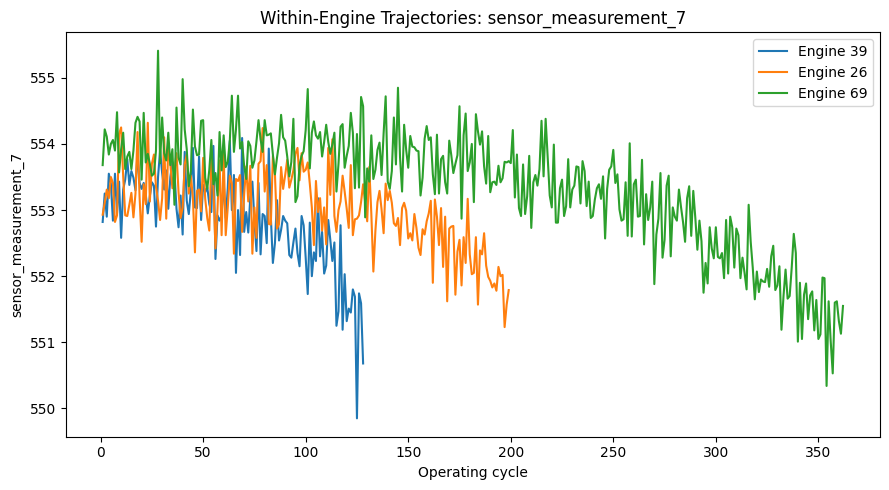

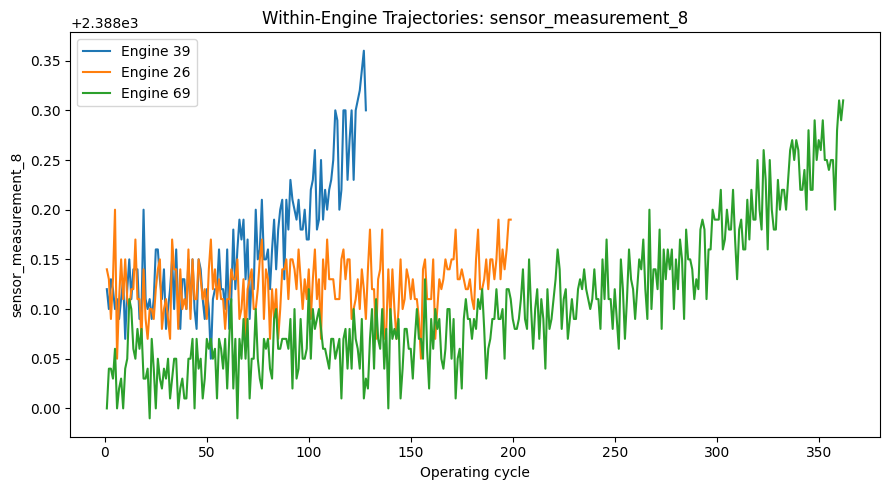

In [108]:
# --- Plot strong-trend features across representative engines ---

for feature in strong_trend_features:
    plt.figure(figsize=(9, 5))

    for unit in representative_engines:
        engine_data = (
            train_labeled_df
            .loc[
                train_labeled_df["unit_no"] == unit
            ]
            .sort_values("cycles")
        )

        plt.plot(
            engine_data["cycles"],
            engine_data[feature],
            label=f"Engine {unit}",
        )

    plt.xlabel("Operating cycle")
    plt.ylabel(feature)
    plt.title(f"Within-Engine Trajectories: {feature}")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [109]:
# --- Locate the rare Sensor 6 values within engine lifecycles ---

sensor_6_counts = (
    train_labeled_df["sensor_measurement_6"]
    .value_counts()
    .sort_values()
)

sensor_6_counts

sensor_measurement_6
21.60      406
21.61    20225
Name: count, dtype: int64

In [110]:
# --- Identify and inspect observations with the rare Sensor 6 value ---

rare_sensor_6_value = (
    train_labeled_df["sensor_measurement_6"]
    .value_counts()
    .idxmin()
)

sensor_6_rare_rows = (
    train_labeled_df
    .loc[
        train_labeled_df["sensor_measurement_6"]
        == rare_sensor_6_value,
        [
            "unit_no",
            "cycles",
            "final_cycle",
            "rul",
            "sensor_measurement_6",
        ],
    ]
    .copy()
)

sensor_6_rare_rows["lifecycle_fraction"] = (
    sensor_6_rare_rows["cycles"]
    / sensor_6_rare_rows["final_cycle"]
)

display(sensor_6_rare_rows.head(20))

sensor_6_rare_rows["lifecycle_fraction"].describe()

,unit_no,cycles,final_cycle,rul,sensor_measurement_6,lifecycle_fraction
192,2,1,287,286,21.6,0.003484
194,2,3,287,284,21.6,0.010453
196,2,5,287,282,21.6,0.017422
200,2,9,287,278,21.6,0.031359
201,2,10,287,277,21.6,0.034843
243,2,52,287,235,21.6,0.181185
246,2,55,287,232,21.6,0.191638
256,2,65,287,222,21.6,0.226481
265,2,74,287,213,21.6,0.257840
266,2,75,287,212,21.6,0.261324


count    406.000000
mean       0.255006
std        0.183756
min        0.003484
25%        0.100093
50%        0.222780
75%        0.371567
max        0.796537
Name: lifecycle_fraction, dtype: float64

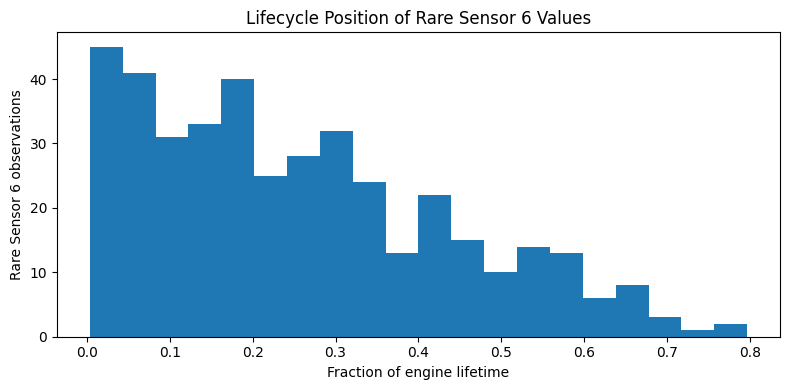

In [111]:
# --- Visualize where rare Sensor 6 values occur across normalized lifetimes ---

plt.figure(figsize=(8, 4))

plt.hist(
    sensor_6_rare_rows["lifecycle_fraction"],
    bins=20,
)

plt.xlabel("Fraction of engine lifetime")
plt.ylabel("Rare Sensor 6 observations")
plt.title("Lifecycle Position of Rare Sensor 6 Values")
plt.tight_layout()
plt.show()

### Limitation of simple trend statistics

Correlation between cycle number and sensor value is only a screening tool.

A low correlation does not mean a sensor is useless.

A sensor may:

- change nonlinearly,
- remain stable until shortly before failure,
- respond to operating conditions,
- contain useful short-term variation,
- or interact with other sensors.

Therefore, within-engine correlation and early-vs-late differences are used to identify patterns worth investigating, not to make final feature-selection decisions.

### Temporal-analysis boundary

Retrospective EDA may use complete training trajectories and known failure endpoints to understand degradation behavior.

Predictive features, however, must remain causal.

A prediction at cycle `t` may use:

- measurements at cycle `t`,
- measurements from cycles before `t`,
- and summaries derived only from that available history.

It may never use measurements from cycles after `t` or the engine's eventual failure cycle.

In [112]:
# --- Calculate within-engine cycle correlation for each retained feature ---

within_engine_correlations = []

for feature in baseline_measurement_features:
    for unit, engine_data in train_labeled_df.groupby("unit_no"):
        correlation = engine_data["cycles"].corr(
            engine_data[feature]
        )

        within_engine_correlations.append(
            {
                "feature": feature,
                "unit_no": unit,
                "cycle_correlation": correlation,
            }
        )

within_engine_correlations = pd.DataFrame(
    within_engine_correlations
)

within_engine_correlations.head()

/Users/stuart/repos/ml-predictive-maintenance-mlops/.venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/stuart/repos/ml-predictive-maintenance-mlops/.venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,feature,unit_no,cycle_correlation
0,op_setting_1,1,-0.038848
1,op_setting_1,2,-0.077614
2,op_setting_1,3,0.029608
3,op_setting_1,4,-0.064539
4,op_setting_1,5,0.006900


Which retained features show the clearest upward trends within engines?

There are several features that show upward trends as cycle count increases: Sensor measurements 2, 3, 4, 9, 11, 14, 15, 17

But Sensor Measurements 9 and 14 show a very clear upward trend. 

Which show the clearest downward trends?

Sensor measurements 7, 12, 20, 21 all show downward trends. But they are nowhere near as obvious as sensor measurements 9 and 14 from the upward trends.

Which appear mostly flat, noisy, step-like, or difficult to interpret?

Operation settings appear noisy with no upward or downward trend (Setting 2 is especially noisy). Sensor measurement 6 is completely flat. 

Do the same general trends appear across the short-, median-, and long-lived representative engines?

Yes, the classification as upward or downward trending remains consistent across the three lifecycle representatives.

Did normalized lifecycle position make any patterns easier to see than absolute cycle number?

Yes, the upward trend that was examined for Sensor 2 seemed to become matched across the 3 difference engines when normalized to percentage of engine lifetime.

Which features had the largest absolute median within-engine cycle correlations?

The largest positive correlation can from Sensor Measurement 4 at 0.79. The largest negative correlation can from Sensor Measurement 12 at -0.81.

Which sensors showed the most consistent trend direction across engines?

There were several features that showed a 100-percent upward trend direction across engines: Sensor Measurements 2, 3, 11, 8, 13, 15, 17, 4

Which features showed the largest standardized early-vs-late differences?

Sensor Measurements 11 and 4 had the top two largest positive standardized differences at 2.028 and 2.017, respectively. Sensor Measurements 12 and 7 and the top two largest negative standardized differences at -1.993 and -1.945, respectively. 

Where do the rare Sensor 6 observations tend to occur within engine lifetimes? Does that make Sensor 6 seem more or less interesting?

The mean percentage of lifetime where the rare observation occurs is at 0.255, but the standard deviation on that measurement is 0.184. This makes is seem less interesting given that it doesn't consistently occur at the same portion of lifetime across all the engines.

Why doesn't strong cycle correlation automatically mean a feature is highly predictive of RUL?

There is a possibility that something with a strong cycle correlation is contributing positively to the total lifetime, i.e., the large a value is the more likely it is that the engine is functioning with good health.

**Strong within-engine correlation with cycle identifies a consistent temporal trend, but predictive usefulness depends on whether that trend helps distinguish remaining life across unseen engines beyond information already provided by cycle number and other features.**

Why doesn't weak cycle correlation automatically mean a feature is useless?

A weak trend correlation can be associated with a bimodal (or more) type of phenomenon. Failures can occur due to a phenomenon that looks more like a step function rather than a linear function, and step functions are known to not create strong correlation values.

What did within-engine trajectories reveal that the global histograms could not?

It revealed the temporal component of the measurements increasing or decreasing as cycle counts increased.

Do any results now suggest promising candidates for future lag, rolling, difference, or slope features?

Conceptually I don't really know how to spot those things. But Sensor Measurements 9 and 14 show a very clear upward trend, so those seem like the best candidates.

Anything surprising or confusing?

I don't particularly know how to answer the question about future lag, rolling, difference, or slope features. 

### Findings

- Multiple retained sensors show systematic within-engine temporal behavior as engines progress toward failure.
- Sensors 2, 3, 4, 9, 11, 14, 15, and 17 generally show upward trends, while Sensors 7, 12, 20, and 21 generally show downward trends.
- Sensor trajectories show broadly consistent trend directions across short-, median-, and long-lived representative engines.
- Normalizing cycle position by completed engine lifetime improves retrospective alignment of some degradation trajectories, suggesting that similar degradation behavior may occur at different absolute rates across engines.
- Sensor 4 shows a strong positive median relationship with cycle, while Sensor 12 shows a strong negative relationship.
- Sensors 4 and 11 show large standardized increases from early to late life, while Sensors 7 and 12 show large standardized decreases.
- Sensor 6 is flat within many engine trajectories, and its rare alternate value does not appear tightly concentrated near failure.
- Operating settings show little obvious monotonic lifecycle trend.
- Global distributions alone concealed the systematic temporal behavior visible within individual engine trajectories.

### Modeling implications

- Sensors showing consistent within-engine degradation trends are promising candidates for later temporal feature engineering.
- Candidate temporal feature families include lags, cycle-to-cycle differences, trailing rolling statistics, and trailing slopes.
- Sensors 4, 7, 9, 11, 12, and 14 are particularly reasonable candidates for controlled temporal-feature experiments based on their observed trajectory behavior.
- Sensor 6 remains in the initial feature set, but the EDA provides weaker evidence that its rare variation carries useful degradation information.
- Strong cycle correlation does not guarantee strong RUL prediction because it may reflect general engine age, redundancy with cycle number, or relationships that do not generalize across engines with different lifetimes.
- Weak linear correlation does not establish uselessness because degradation signals may be nonlinear, threshold-like, late-emerging, or interaction-dependent.
- Any temporal predictive feature must use only current and past observations from the same engine.
- Normalized lifecycle fraction must remain an EDA-only quantity because it depends on the future failure endpoint.

## 8. Operating conditions and regimes

### Question

Do the FD001 operating settings represent meaningfully different operating regimes, or mostly small variation around one practical operating condition?

### Why this matters

Sensor measurements can depend on operating conditions as well as equipment health.

If engines operate under several distinct regimes, the model may need to account for those regimes explicitly so that normal condition-driven sensor changes are not mistaken for degradation.

However, clustering should only be introduced when the operating-setting data provide evidence for genuinely distinct regimes rather than being imposed arbitrarily.

In [113]:
# --- Summarize variability across the three operating-setting columns ---

operating_setting_summary = pd.DataFrame(
    {
        "unique_values": train_df[OPERATING_SETTING_COLUMNS].nunique(),
        "minimum": train_df[OPERATING_SETTING_COLUMNS].min(),
        "maximum": train_df[OPERATING_SETTING_COLUMNS].max(),
        "mean": train_df[OPERATING_SETTING_COLUMNS].mean(),
        "std": train_df[OPERATING_SETTING_COLUMNS].std(),
    }
)

operating_setting_summary["range"] = (
    operating_setting_summary["maximum"]
    - operating_setting_summary["minimum"]
)

operating_setting_summary

,unique_values,minimum,maximum,mean,std,range
op_setting_1,158,-0.0087,0.0087,-0.000009,0.002187,0.0174
op_setting_2,13,-0.0006,0.0006,0.000002,0.000293,0.0012
op_setting_3,1,100.0000,100.0000,100.000000,0.000000,0.0000


In [114]:
# --- Identify which operating settings actually vary in the training data ---

operating_setting_summary["is_constant"] = (
    operating_setting_summary["unique_values"] == 1
)

operating_setting_summary

,unique_values,minimum,maximum,mean,std,range,is_constant
op_setting_1,158,-0.0087,0.0087,-0.000009,0.002187,0.0174,False
op_setting_2,13,-0.0006,0.0006,0.000002,0.000293,0.0012,False
op_setting_3,1,100.0000,100.0000,100.000000,0.000000,0.0000,True


In [115]:
# --- Select only operating settings with training variation ---

varying_operating_settings = [
    feature
    for feature in OPERATING_SETTING_COLUMNS
    if feature not in constant_train_features
]

print("Varying operating settings:")
print(varying_operating_settings)

Varying operating settings:
['op_setting_1', 'op_setting_2']


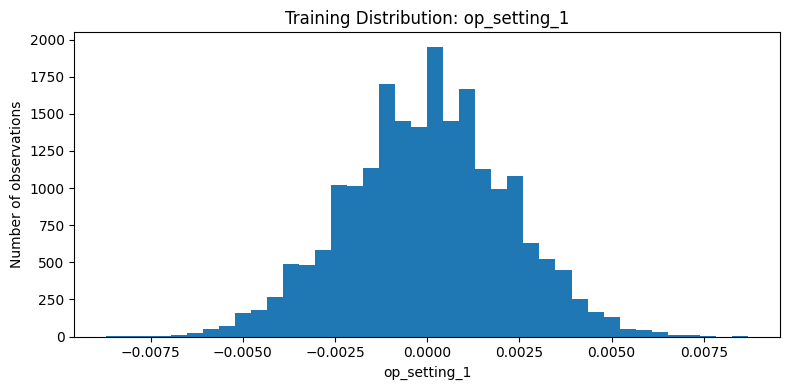

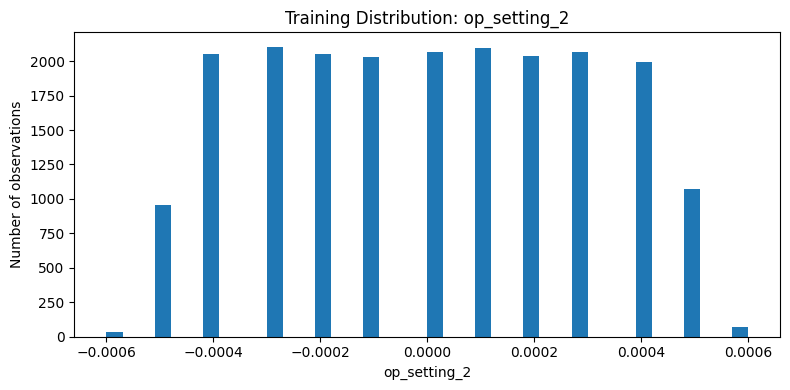

In [116]:
# --- Plot the global training distribution of each varying operating setting ---

for setting in varying_operating_settings:
    plt.figure(figsize=(8, 4))

    plt.hist(
        train_df[setting],
        bins=40,
    )

    plt.xlabel(setting)
    plt.ylabel("Number of observations")
    plt.title(f"Training Distribution: {setting}")
    plt.tight_layout()
    plt.show()

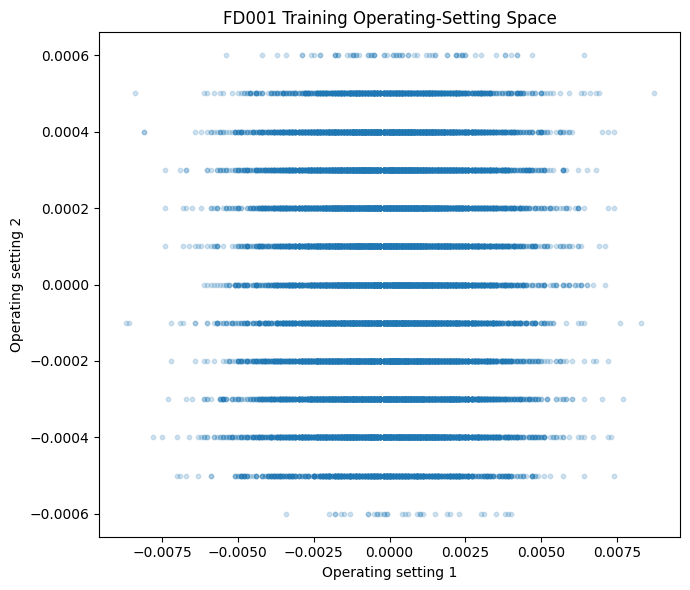

In [117]:
# --- Visualize the joint operating-setting structure in the training data ---

plt.figure(figsize=(7, 6))

plt.scatter(
    train_df["op_setting_1"],
    train_df["op_setting_2"],
    alpha=0.2,
    s=10,
)

plt.xlabel("Operating setting 1")
plt.ylabel("Operating setting 2")
plt.title("FD001 Training Operating-Setting Space")
plt.tight_layout()
plt.show()

In [118]:
# --- Standardize the varying settings for easier visual comparison ---

standardized_settings = (
    train_df[varying_operating_settings]
    - train_df[varying_operating_settings].mean()
) / train_df[varying_operating_settings].std()

standardized_settings.head()

,op_setting_1,op_setting_2
0,-0.315972,-1.372920
1,0.872701,-1.031695
2,-1.961827,1.015652
3,0.324083,-0.008022
4,-0.864590,-0.690471


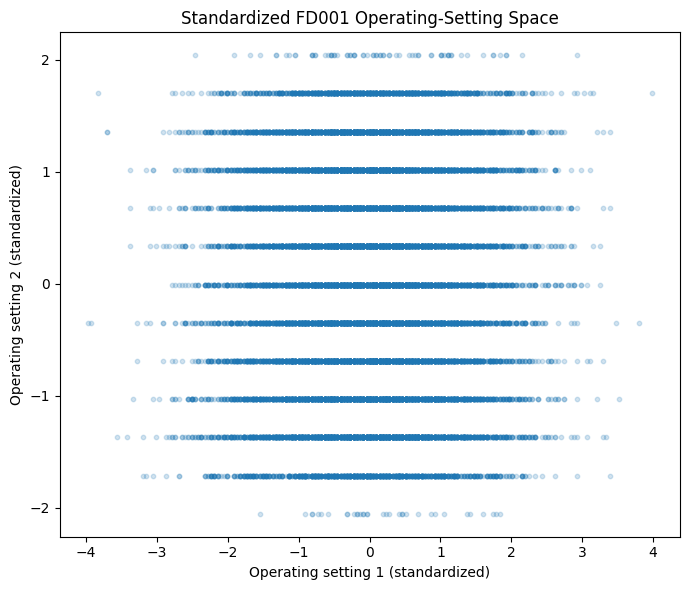

In [119]:
# --- Plot standardized operating-setting space ---

plt.figure(figsize=(7, 6))

plt.scatter(
    standardized_settings["op_setting_1"],
    standardized_settings["op_setting_2"],
    alpha=0.2,
    s=10,
)

plt.xlabel("Operating setting 1 (standardized)")
plt.ylabel("Operating setting 2 (standardized)")
plt.title("Standardized FD001 Operating-Setting Space")
plt.tight_layout()
plt.show()

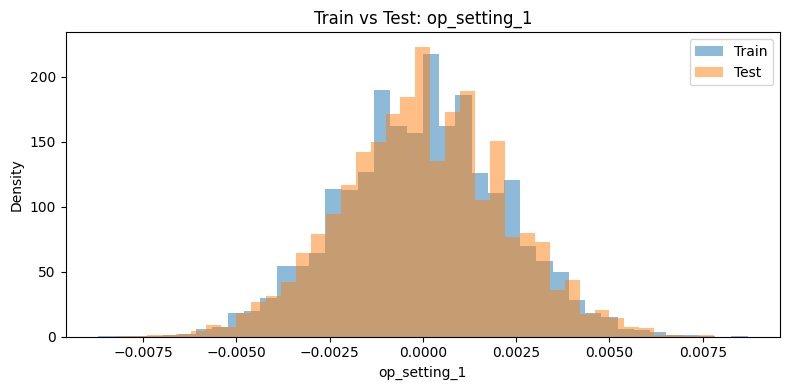

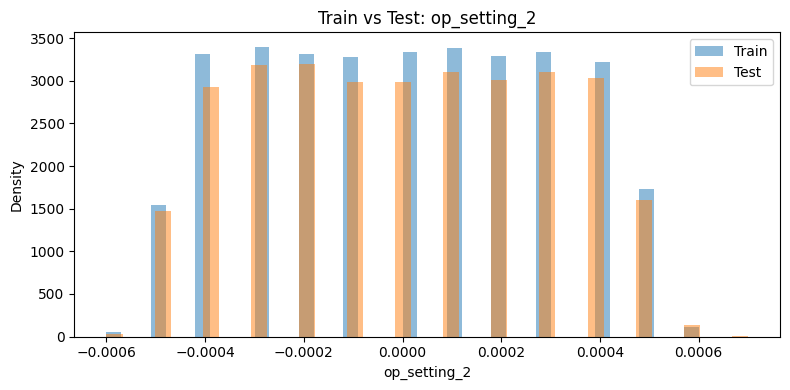

In [120]:
# --- Compare train and test operating-setting distributions ---

for setting in varying_operating_settings:
    plt.figure(figsize=(8, 4))

    plt.hist(
        train_df[setting],
        bins=40,
        density=True,
        alpha=0.5,
        label="Train",
    )

    plt.hist(
        test_df[setting],
        bins=40,
        density=True,
        alpha=0.5,
        label="Test",
    )

    plt.xlabel(setting)
    plt.ylabel("Density")
    plt.title(f"Train vs Test: {setting}")
    plt.legend()
    plt.tight_layout()
    plt.show()

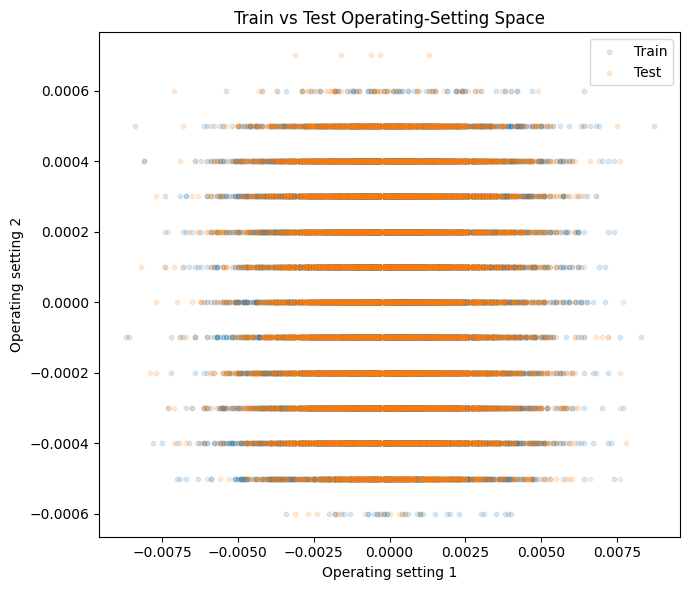

In [121]:
# --- Compare train and test observations in operating-setting space ---

plt.figure(figsize=(7, 6))

plt.scatter(
    train_df["op_setting_1"],
    train_df["op_setting_2"],
    alpha=0.15,
    s=10,
    label="Train",
)

plt.scatter(
    test_df["op_setting_1"],
    test_df["op_setting_2"],
    alpha=0.15,
    s=10,
    label="Test",
)

plt.xlabel("Operating setting 1")
plt.ylabel("Operating setting 2")
plt.title("Train vs Test Operating-Setting Space")
plt.legend()
plt.tight_layout()
plt.show()

In [122]:
# --- Summarize each engine's average operating settings ---

engine_setting_means = (
    train_df
    .groupby("unit_no")[varying_operating_settings]
    .mean()
)

engine_setting_means.describe()

,op_setting_1,op_setting_2
count,1.000000e+02,100.000000
mean,-4.591302e-06,0.000001
std,1.517774e-04,0.000048
min,-3.233831e-04,-0.000116
25%,-1.063256e-04,-0.000034
50%,-2.493883e-07,0.000001
75%,9.788008e-05,0.000034
max,5.116667e-04,0.000127


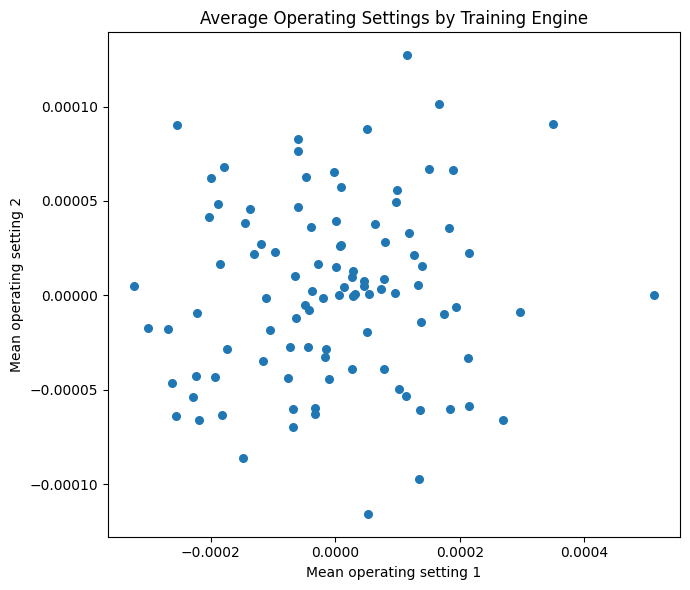

In [123]:
# --- Visualize average operating settings for each training engine ---

plt.figure(figsize=(7, 6))

plt.scatter(
    engine_setting_means["op_setting_1"],
    engine_setting_means["op_setting_2"],
    s=30,
)

plt.xlabel("Mean operating setting 1")
plt.ylabel("Mean operating setting 2")
plt.title("Average Operating Settings by Training Engine")
plt.tight_layout()
plt.show()

In [124]:
# --- Compare within-engine setting variability with differences between engines ---

operating_variation_comparison = []

for setting in varying_operating_settings:
    engine_means = (
        train_df.groupby("unit_no")[setting].mean()
    )

    engine_stds = (
        train_df.groupby("unit_no")[setting].std()
    )

    operating_variation_comparison.append(
        {
            "setting": setting,
            "between_engine_std_of_means": engine_means.std(),
            "mean_within_engine_std": engine_stds.mean(),
        }
    )

operating_variation_comparison = pd.DataFrame(
    operating_variation_comparison
)

operating_variation_comparison

,setting,between_engine_std_of_means,mean_within_engine_std
0,op_setting_1,0.000152,0.002187
1,op_setting_2,0.000048,0.000290


In [125]:
# --- Calculate within-engine cycle correlation for each varying operating setting ---

operating_setting_correlations = []

for setting in varying_operating_settings:
    for unit, engine_data in train_labeled_df.groupby("unit_no"):

        if engine_data[setting].nunique() < 2:
            correlation = np.nan
        else:
            correlation = engine_data["cycles"].corr(
                engine_data[setting]
            )

        operating_setting_correlations.append(
            {
                "setting": setting,
                "unit_no": unit,
                "cycle_correlation": correlation,
            }
        )

operating_setting_correlations = pd.DataFrame(
    operating_setting_correlations
)

In [126]:
# --- Summarize whether operating settings systematically change with cycle ---

operating_trend_summary = (
    operating_setting_correlations
    .groupby("setting")["cycle_correlation"]
    .agg(
        median_correlation="median",
        mean_correlation="mean",
        min_correlation="min",
        max_correlation="max",
    )
)

operating_trend_summary

,median_correlation,mean_correlation,min_correlation,max_correlation
setting,,,,
op_setting_1,-0.000324,0.001940,-0.174423,0.195458
op_setting_2,0.007699,0.010223,-0.205971,0.158268


### Regime-identification caution

A clustering algorithm will divide observations into groups whenever it is asked to do so, even if the underlying data represent one continuous operating region.

Therefore, algorithms such as K-means should not be used merely to manufacture operating regimes.

Explicit regime modeling would be justified only if the operating-setting data showed meaningful and reproducible separation that could plausibly affect sensor interpretation or model performance.

### Operating-setting feature policy

Operating settings do not need to predict degradation directly in order to be useful.

They may provide context that helps the model distinguish sensor changes caused by operating conditions from sensor changes caused by degradation.

Therefore:

- exactly constant operating settings can be removed,
- varying operating settings should remain in the baseline feature set,
- and explicit regime clustering should only be introduced if supported by the data or later modeling evidence.

**Which operating settings are constant, and which vary?**

Settings 1 and 2 vary (with 1 having higher variance than 2), while Setting 3 is constant.

**What do the individual distributions of Settings 1 and 2 look like?**

Setting 1 appears more gaussian-like, while Setting 2 appears much more discreet. But it's worth noting that Setting 2 climbs up to and then down from the most common value at the end of the spectrum of number of observations. 

**When Settings 1 and 2 are plotted jointly, do you see clearly separated clusters or mainly one operating region?**

I mainly see one operating region, there definitely isn't a clustering phenomenon. 

**Does standardizing the two axes change your interpretation of the joint structure?**

Standardizing the two axes results in a plot that's close to identical to the first plot. 

**Do train and test occupy roughly the same operating-setting space?**

For Operating Setting 1 it there are some variations but they seem to occupy the same space. For Operating Setting 2, however, the test set consistently has a slightly lower density.

**Train and test broadly occupy the same operating-setting region, with some differences in their marginal distributions.**

**Do different engines have noticeably different average operating settings, or are their means clustered together?**

Yes to the first part of the question, the average operating settings do not present as a clear cluster on a plot of average operating settings by training engine.

**How does within-engine variation compare with between-engine variation in the settings?**

There is a change in the order of magnitude moving from between engine to within engine (with an increase in value for each operating setting).

**Do Settings 1 or 2 show a consistent relationship with cycle number?**

No, for median correlation, mean correlation, minimum correlation, and maximum correlation a score above 0.2 is never observed. 

**Based on all of this evidence, how many practical operating regimes would you say FD001 appears to contain?**

I would say FD001 has many practival operating regimes, seeing as we have two operating settings that both vary. Would we maybe take the product of the number of unique values in each operating setting? I'm confused on this one.

**And in this case, we actually have authoritative dataset information that resolves the ambiguity: NASA describes FD001 as having ONE operating condition (sea level), whereas FD002 and FD004 have six operating conditions.**

**Why shouldn't we run K-means and automatically treat the resulting groups as real operating regimes?**

Because we are not observing a clustering phenomenon, which is what K-means is good at putting cluster centroids to. And even if there were a clear clustering phenomenon I'm not sure if K-means would be a good strategy. I need that part explained to me more. 

**If Settings 1 and 2 don't strongly track degradation, why might we still keep them as baseline predictive features?**

Because even if they don't strongly contribute to degradation signals, there still may be weak but present signals that will still boost predictive capabilities.

*So settings can serve as context variables.*

**Does this analysis change anything about the feature-engineering plan?**

No, I don't believe so. The original plan was to keep Settings 1 and 2 and drop Setting 3. That plan is remaining unchanged after this.

**Anything surprising or confusing?**

I don't know how K-means fits into analyses like this. And I especially don't know what I'm looking at on the operating-setting space graphs.

### Findings

- Operating Settings 1 and 2 vary throughout FD001, while Operating Setting 3 is exactly constant.
- The varying settings occupy one broadly continuous operating region rather than several clearly separated clusters.
- Standardizing the operating-setting axes does not reveal additional separated populations.
- Training and test observations occupy broadly similar operating-setting space.
- Engine-level average settings do not show clearly separated groups.
- Within-engine operating-setting variability is larger than the variation among engine-level average settings.
- Settings 1 and 2 show little consistent relationship with engine cycle number and therefore do not appear to behave as degradation trajectories.
- The observed setting structure is consistent with FD001's documented single operating condition.

### Modeling implications

- FD001 should be treated as containing one practical operating regime rather than defining a separate regime for each unique setting combination.
- No explicit operating-regime clustering is currently justified.
- K-means should not be applied merely to manufacture regime labels because it will partition the data whenever a value of `k` is specified, even when no meaningful clusters exist.
- Operating Setting 3 should remain excluded because it is constant.
- Operating Settings 1 and 2 should remain in the baseline feature set because they may provide context for interpreting condition-dependent sensor measurements even though they do not directly track degradation.
- More complex regime-specific normalization or modeling is unnecessary for the initial FD001 baseline.

## 9. Target behavior and prediction difficulty

### Question

How is the uncapped training RUL target distributed across FD001, which lifecycle stages and engines contribute the most training observations, and what alternative target or weighting strategies might be worth testing later?

### Why this matters

The distribution of the target affects what the model sees most often during training.

Because each engine contributes one row per operating cycle:

- longer-lived engines contribute more training rows,
- low RUL values occur for every engine that eventually reaches failure,
- very high RUL values occur only for longer-lived engines.

These properties can influence model fitting and evaluation.

This analysis will identify possible target and weighting experiments, but it will not choose among them before validation.

In [127]:
# --- Summarize the uncapped training RUL target ---

rul_summary = train_labeled_df["rul"].describe()

rul_summary

count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: rul, dtype: float64

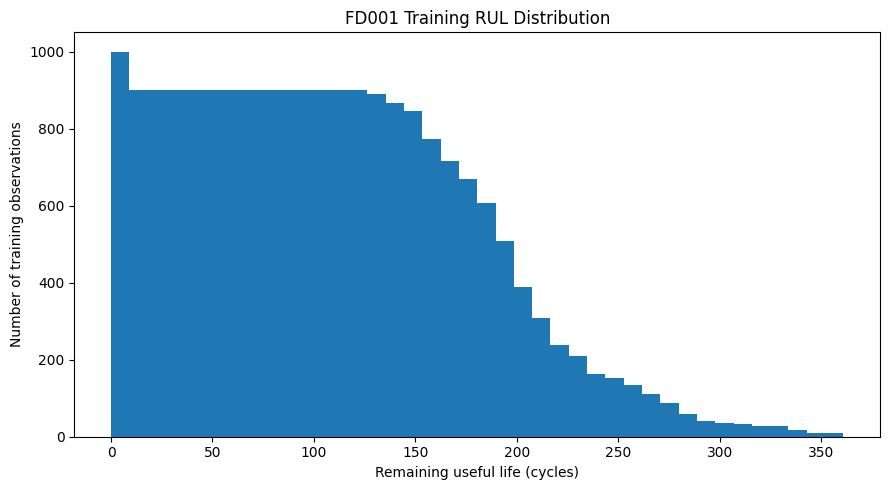

In [128]:
# --- Visualize the global distribution of training RUL values ---

plt.figure(figsize=(9, 5))

plt.hist(
    train_labeled_df["rul"],
    bins=40,
)

plt.xlabel("Remaining useful life (cycles)")
plt.ylabel("Number of training observations")
plt.title("FD001 Training RUL Distribution")
plt.tight_layout()
plt.show()

In [129]:
# --- Count how many training observations occur at each exact RUL value ---

rul_frequency = (
    train_labeled_df["rul"]
    .value_counts()
    .sort_index()
)

rul_frequency.head(20)

rul
0     100
1     100
2     100
3     100
4     100
5     100
6     100
7     100
8     100
9     100
10    100
11    100
12    100
13    100
14    100
15    100
16    100
17    100
18    100
19    100
Name: count, dtype: int64

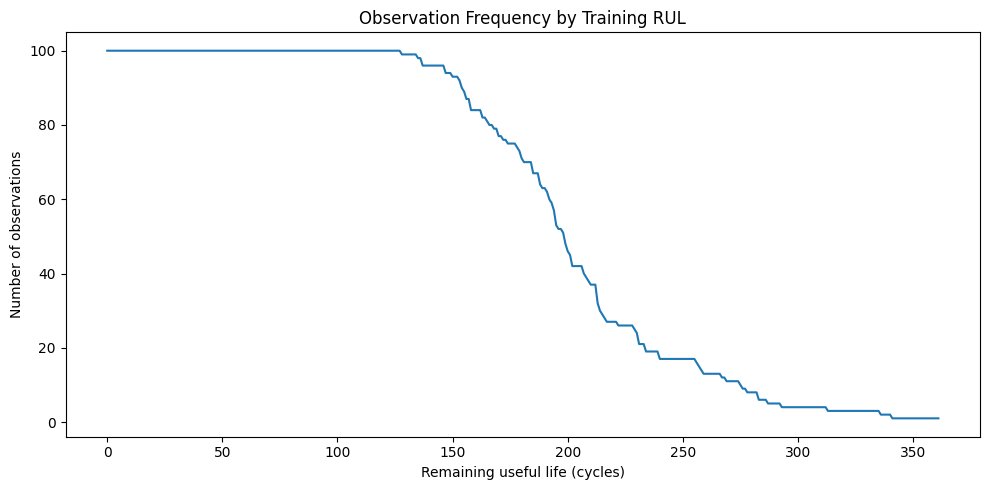

In [130]:
# --- Visualize training-row frequency across exact RUL values ---

plt.figure(figsize=(10, 5))

plt.plot(
    rul_frequency.index,
    rul_frequency.values,
)

plt.xlabel("Remaining useful life (cycles)")
plt.ylabel("Number of observations")
plt.title("Observation Frequency by Training RUL")
plt.tight_layout()
plt.show()

In [131]:
# --- Summarize complete training-engine lifetimes ---

training_lifetimes = (
    train_labeled_df
    .groupby("unit_no")["final_cycle"]
    .first()
)

training_lifetimes.describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: final_cycle, dtype: float64

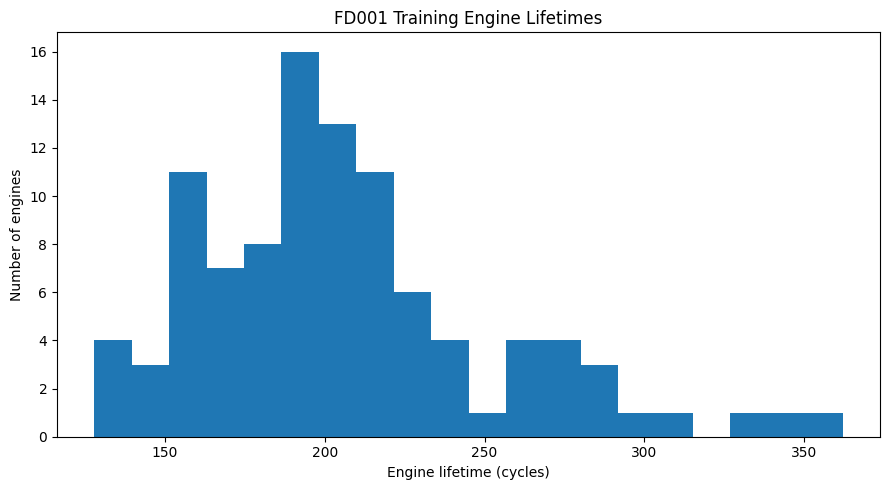

In [132]:
# --- Visualize complete run-to-failure lifetimes across training engines ---

plt.figure(figsize=(9, 5))

plt.hist(
    training_lifetimes,
    bins=20,
)

plt.xlabel("Engine lifetime (cycles)")
plt.ylabel("Number of engines")
plt.title("FD001 Training Engine Lifetimes")
plt.tight_layout()
plt.show()

In [133]:
# --- Measure how many training rows each engine contributes ---

engine_training_contribution = (
    train_labeled_df
    .groupby("unit_no")
    .size()
    .rename("training_rows")
    .to_frame()
)

engine_training_contribution["fraction_of_training_rows"] = (
    engine_training_contribution["training_rows"]
    / len(train_labeled_df)
)

engine_training_contribution.describe()

,training_rows,fraction_of_training_rows
count,100.000000,100.000000
mean,206.310000,0.010000
std,46.342749,0.002246
min,128.000000,0.006204
25%,177.000000,0.008579
50%,199.000000,0.009646
75%,229.250000,0.011112
max,362.000000,0.017546


In [134]:
# --- Compare the smallest and largest engine contributions ---

shortest_contribution = (
    engine_training_contribution["training_rows"].min()
)

largest_contribution = (
    engine_training_contribution["training_rows"].max()
)

print(f"Fewest rows contributed by one engine: {shortest_contribution}")
print(f"Most rows contributed by one engine:   {largest_contribution}")
print(
    "Largest / smallest contribution ratio: "
    f"{largest_contribution / shortest_contribution:.2f}"
)

Fewest rows contributed by one engine: 128
Most rows contributed by one engine:   362
Largest / smallest contribution ratio: 2.83


### Row-level weighting implication

If every training row receives equal weight, an engine with 300 observed cycles contributes 300 loss terms while an engine with 150 cycles contributes only 150.

Therefore, ordinary row-wise training implicitly gives longer-lived engines more total influence on the fitted model.

This is not necessarily wrong, but it is a modeling choice worth recognizing and potentially testing.

In [135]:
# --- Construct exploratory weights giving each engine equal total training weight ---

engine_row_counts = (
    train_labeled_df
    .groupby("unit_no")
    .size()
)

train_labeled_df["equal_engine_weight"] = (
    train_labeled_df["unit_no"]
    .map(1 / engine_row_counts)
)

In [136]:
# --- Verify equal-engine weights sum to one within every engine ---

engine_weight_totals = (
    train_labeled_df
    .groupby("unit_no")["equal_engine_weight"]
    .sum()
)

engine_weight_totals.describe()

count    1.000000e+02
mean     1.000000e+00
std      1.932650e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: equal_engine_weight, dtype: float64

In [137]:
# --- Group training observations into exploratory RUL bands ---

rul_bins = [
    -1,
    30,
    60,
    120,
    np.inf,
]

rul_labels = [
    "0-30",
    "31-60",
    "61-120",
    "121+",
]

train_labeled_df["rul_band"] = pd.cut(
    train_labeled_df["rul"],
    bins=rul_bins,
    labels=rul_labels,
)

rul_band_counts = (
    train_labeled_df["rul_band"]
    .value_counts(sort=False)
    .to_frame("observations")
)

rul_band_counts["percent"] = (
    100
    * rul_band_counts["observations"]
    / len(train_labeled_df)
)

rul_band_counts

,observations,percent
rul_band,,
0-30,3100,15.025932
31-60,3000,14.541224
61-120,6000,29.082449
121+,8531,41.350395


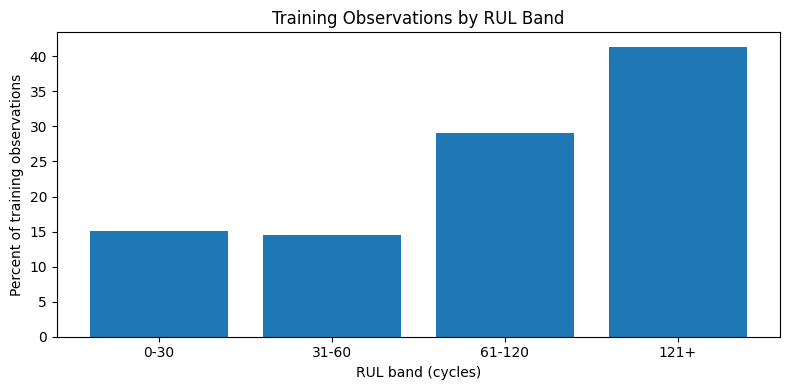

In [138]:
# --- Visualize the amount of training data available by RUL band ---

plt.figure(figsize=(8, 4))

plt.bar(
    rul_band_counts.index.astype(str),
    rul_band_counts["percent"],
)

plt.xlabel("RUL band (cycles)")
plt.ylabel("Percent of training observations")
plt.title("Training Observations by RUL Band")
plt.tight_layout()
plt.show()

In [139]:
# --- Quantify how candidate RUL caps would alter the training target ---

candidate_caps = [
    100,
    125,
    150,
]

cap_summary = []

for cap in candidate_caps:
    observations_capped = (
        train_labeled_df["rul"] > cap
    ).sum()

    cap_summary.append(
        {
            "rul_cap": cap,
            "observations_capped": observations_capped,
            "percent_capped": (
                100
                * observations_capped
                / len(train_labeled_df)
            ),
        }
    )

cap_summary = pd.DataFrame(cap_summary)

cap_summary

,rul_cap,observations_capped,percent_capped
0,100,10531,51.044545
1,125,8031,38.926858
2,150,5607,27.177548


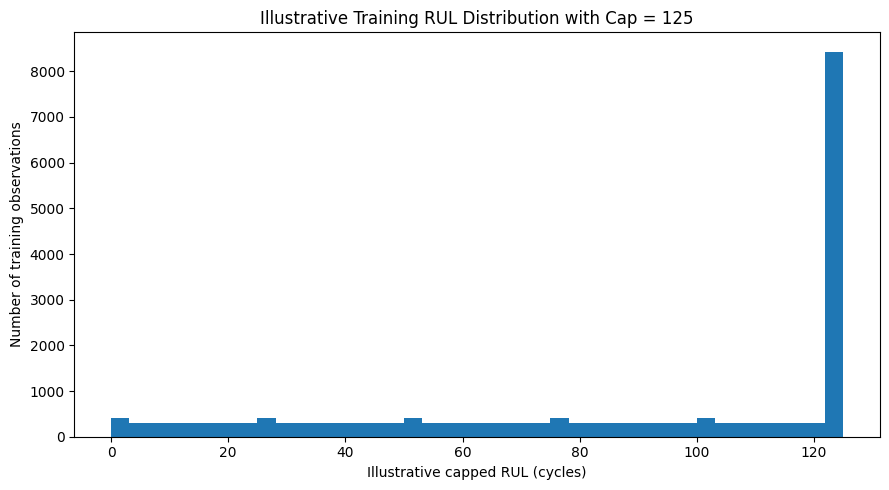

In [140]:
# --- Visualize an illustrative capped-RUL target without adopting it ---

illustrative_cap = 125

illustrative_capped_rul = (
    train_labeled_df["rul"]
    .clip(upper=illustrative_cap)
)

plt.figure(figsize=(9, 5))

plt.hist(
    illustrative_capped_rul,
    bins=40,
)

plt.xlabel("Illustrative capped RUL (cycles)")
plt.ylabel("Number of training observations")
plt.title(
    f"Illustrative Training RUL Distribution "
    f"with Cap = {illustrative_cap}"
)
plt.tight_layout()
plt.show()

### Capped-RUL interpretation

RUL capping is not simply a numerical cleanup operation.

It changes the supervised-learning target.

An uncapped target asks the model to estimate remaining life throughout the full engine trajectory.

A capped target instead treats sufficiently early engine states as approximately equivalent, based on the assumption that early-life sensor behavior may not contain enough information to distinguish exact long-horizon RUL.

Whether this improves prediction should be tested through grouped validation rather than assumed in advance.

### Test-label boundary

The official test RUL values should not be used to choose:

- the RUL cap,
- feature sets,
- model families,
- hyperparameters,
- or weighting strategies.

Those decisions should be made using the training data and engine-grouped validation.

The test RUL labels should remain reserved for final evaluation of the selected system.

**What does the uncapped RUL distribution look like? Is RUL represented equally across its full range?**

It remains somewhat constant until an RUL of about 150, and then a significant dropoff occurs. So no, RUL is not represented equally across its full range. Lower RUL values are disproportionately represented over higher RUL values.

**Why do low RUL values occur for more engines than very high RUL values?**

Because every single engine in the training set runs until failure. So every engine will eventually have an RUL of 0, but very few engines will have an RUL value of 350 (only a few engines with especially long lifecycles).

**How much more training data does the longest-lived engine contribute than the shortest-lived engine?**

The shortest-lived engine contributes 128 cycles. The longest-lived engine contributes 362 cycles. So more than double, to answer the question.

**Why does ordinary equal-per-row training implicitly give longer-lived engines more influence?**

Because they have more rows to contribute to the dataset, meaning the model becomes skewed towards being more skilled at predicting the RUL of longer-lived engines.

*Longer-lived engines contribute more individual loss terms during training, so they exert more total influence on the fitted parameters.*

**How would equal-engine weighting change that?**

Equal engine weighting would (in theory) make the model equally skilled at predicting RUL for short-lived engines as with long-lived engines.

**How are the training observations distributed across the four exploratory RUL bands?**

About 15-percent each for the 0-30 and 31-60 bands. 30-percent for the 61-120 band. And about 40-percent for the 121+ band. So lower observation bands contribute far less to the dataset.

**Why might predicting exact very-high RUL values be intrinsically difficult from sensor data?**

Because predicting very high RUL values would imply you're at the start of the lifecycle of a long-lived engine. The farther out a potential failure is, the more likely unexpected phenomenon will occur. It's much easier to predict failures at the end of a lifecycle because there is more training data there.

*Early-life engines may look very similar in their sensor measurements even when they will ultimately have very different lifetimes.*

**What assumption does a capped-RUL target make about early engine life?**

This one I don't really have a speculative answer for. It assumes that sufficiently early engine states are approximately equivalent to each other, but I don't really know what's going on conceptually here. 

**For caps of 100, 125, and 150, how much of the training data would be altered?**

For 100 it would be about 50% of the training data, for 125 it would be about 39% of the training data, and for 150 it would be about 27% of the training data. 

**Why shouldn't we simply choose whichever cap makes the target distribution look nicest?**

Not really sure about an answer on this one. Because grouped validation need to be done? And it's plausible that an ugly distribution might lead to better predictions than a pretty distribution.

**Why shouldn't we use test_rul_df to decide whether capped RUL or equal-engine weighting works better?**

Because the test set does not run until failure. The test set ends while the engines are still functional. But I'm not sure what extra details to describe to demonstrate conceptual knowledge here.

*Validation tells us what to build. Test tells us how the finished system performs.*

**For the first baseline, would you currently choose uncapped RUL or capped RUL, and why?**

I can't really give a confident answer on this one. But I'd choose capped because of the variance across engine lifespans. If there were little variance in total engine life within the fleet we could probably go with uncapped, but that's definitely not the case in this dataset.

**Would you initially use ordinary row weighting or equal-engine weighting, and why?**

Again, not really sure. But I'd used equal engine weighting because that sounds like something that could balance out the fact that there are some long-lived engines that make bigger contributions to the dataset.

*Equal-engine weighting gives every engine the same total contribution to the training objective, regardless of how many rows it contains.*

**Anything surprising or confusing?**

I made note of the ones that confused me in my answers above.

### Findings

- The uncapped training RUL target is not uniformly represented across its full range.
- Low and moderate RUL values are represented by more engines, while very high RUL values can only be contributed by sufficiently long-lived engines.
- Training-engine lifetimes range from 128 to 362 cycles, so the longest-lived engine contributes approximately 2.8 times as many training rows as the shortest-lived engine.
- Ordinary row-level training therefore gives longer-lived engines greater total influence on the fitting objective.
- Approximately 15% of observations fall in each of the 0–30 and 31–60 RUL bands, approximately 30% fall in 61–120, and approximately 40% fall above 120 cycles.
- Exact high-RUL prediction may be intrinsically difficult because early-life sensor states can look similar even for engines that eventually have substantially different lifetimes.
- Candidate caps of 100, 125, and 150 would alter progressively smaller but still substantial portions of the training target.

### Modeling implications

- The initial reference baseline should use uncapped RUL and ordinary equal-per-row weighting because these introduce the fewest additional modeling assumptions.
- Capped RUL should be treated as a controlled modeling experiment rather than a data-cleaning operation.
- A capped target assumes that exact long-horizon RUL is not sufficiently distinguishable or operationally necessary during early healthy engine life.
- Equal-engine weighting is a separate experiment that gives every engine equal total influence regardless of sequence length; it does not guarantee equal predictive accuracy across engines.
- Candidate caps and weighting strategies should be selected using engine-grouped validation rather than the official test labels.
- The official test RUL values should remain reserved for final evaluation after modeling choices are fixed.
- Later error analysis should examine performance by RUL band so acceptable aggregate error does not conceal poor near-failure performance.

## 10. Leakage audit

### Question

Which variables and data-processing choices could leak future, target, engine, validation, or test information into the RUL model, and what safeguards should the modeling pipeline enforce?

### Why this matters

Predictive-maintenance datasets make leakage especially easy because complete training trajectories reveal information that would not be known during real-time prediction.

Retrospective EDA may legitimately use future failure information to construct labels and understand degradation.

Predictive features, model preprocessing, and model-selection decisions must instead reproduce the information boundary that would exist at inference time.

In [141]:
# --- Identify columns added during target construction and EDA ---

original_columns = set(CMAPSS_COLUMNS)

added_training_columns = [
    column
    for column in train_labeled_df.columns
    if column not in original_columns
]

added_training_columns

['final_cycle', 'rul', 'equal_engine_weight', 'rul_band']

In [142]:
# --- Define explicit roles for identifiers, targets, and predictive features ---

identifier_columns = [
    "unit_no",
]

sequence_columns = [
    "cycles",
]

target_columns = [
    "rul",
]

future_information_columns = [
    "final_cycle",
]

analysis_only_columns = [
    "equal_engine_weight",
    "rul_band",
]

constant_columns = constant_train_features

baseline_predictive_features = (
    sequence_columns
    + baseline_measurement_features
)

print("Baseline predictive feature count:", len(baseline_predictive_features))
print(baseline_predictive_features)

Baseline predictive feature count: 18
['cycles', 'op_setting_1', 'op_setting_2', 'sensor_measurement_2', 'sensor_measurement_3', 'sensor_measurement_4', 'sensor_measurement_6', 'sensor_measurement_7', 'sensor_measurement_8', 'sensor_measurement_9', 'sensor_measurement_11', 'sensor_measurement_12', 'sensor_measurement_13', 'sensor_measurement_14', 'sensor_measurement_15', 'sensor_measurement_17', 'sensor_measurement_20', 'sensor_measurement_21']


In [143]:
# --- Verify that known target and future-information columns are excluded ---

forbidden_predictive_columns = set(
    identifier_columns
    + target_columns
    + future_information_columns
    + analysis_only_columns
)

accidental_leakage_columns = (
    forbidden_predictive_columns
    .intersection(baseline_predictive_features)
)

assert not accidental_leakage_columns, (
    "Leakage-risk columns found in feature set: "
    f"{sorted(accidental_leakage_columns)}"
)

print("No known leakage-risk columns are present in the baseline feature set.")

No known leakage-risk columns are present in the baseline feature set.


### Target leakage: `rul`

`rul` is the quantity the model is trying to predict.

Including it, or any direct transformation of it, in the predictive feature matrix would give the model access to the answer.

The RUL target may be used for:

- supervised training labels,
- validation metrics,
- retrospective EDA,
- and error analysis.

It may not be used as a predictive input.

### Future-information leakage: `final_cycle`

`final_cycle` is known for the complete run-to-failure training trajectories only because the eventual failure has already occurred.

It is required to construct the training label:

`rul = final_cycle - cycles`

At inference time, the eventual failure cycle is precisely what is unknown.

Therefore, `final_cycle` is valid for retrospective label construction but forbidden as a predictive feature.

In [144]:
# --- Document retrospective lifecycle features that must remain EDA-only ---

eda_only_future_features = [
    "lifecycle_fraction",
    "lifecycle_stage",
]

eda_only_future_features

['lifecycle_fraction', 'lifecycle_stage']

### Leakage risk: normalized lifecycle position

Normalized lifecycle position is useful retrospectively because completed training trajectories reveal the eventual lifetime of each engine.

However:

`lifecycle_fraction = cycles / final_cycle`

requires knowing the future failure cycle.

Therefore, normalized lifecycle fraction and lifecycle-stage labels are EDA-only quantities and must never become predictive inputs.

### Why `cycles` is not automatically leakage

The current cycle number is known at prediction time and therefore does not reveal future information.

It can legitimately act as an engine-age feature.

However, strong predictive performance from `cycles` alone should be interpreted carefully because it may exploit average lifetime patterns rather than detailed degradation state.

Its value should therefore be measured empirically against sensor-based models.

### Identifier leakage and memorization risk

`unit_no` is an arbitrary engine identifier.

It is useful for:

- grouping observations,
- preserving sequence boundaries,
- constructing grouped validation splits,
- creating temporal features,
- and tracing predictions.

It should not be treated as a numerical predictive feature.

A model could otherwise learn engine-specific associations that do not generalize to unseen engines.

In [145]:
# --- Demonstrate an engine-grouped train/validation split ---

from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

train_indices, validation_indices = next(
    splitter.split(
        train_labeled_df,
        groups=train_labeled_df["unit_no"],
    )
)

development_train_df = train_labeled_df.iloc[train_indices]
validation_df = train_labeled_df.iloc[validation_indices]

In [146]:
# --- Verify that no engine appears in both development and validation data ---

development_engines = set(
    development_train_df["unit_no"].unique()
)

validation_engines = set(
    validation_df["unit_no"].unique()
)

engine_overlap = (
    development_engines
    .intersection(validation_engines)
)

print("Development engines:", len(development_engines))
print("Validation engines:", len(validation_engines))
print("Engine overlap:", engine_overlap)

assert len(engine_overlap) == 0

Development engines: 80
Validation engines: 20
Engine overlap: set()


### Group leakage from random row splitting

Rows from the same engine are temporally related and share engine-specific characteristics.

Randomly splitting rows could place observations from the same engine into both training and validation data.

That would make validation easier than the real deployment problem, where the model must generalize to engines that were not present during model fitting.

Validation must therefore be grouped by `unit_no`.

In [147]:
# --- Example of a causal one-cycle sensor lag ---

example_safe_lag = (
    train_df
    .groupby("unit_no")["sensor_measurement_4"]
    .shift(1)
)

In [148]:
# --- Example of a causal trailing rolling mean within each engine ---

example_safe_rolling_mean = (
    train_df
    .groupby("unit_no")["sensor_measurement_4"]
    .transform(
        lambda series: (
            series
            .rolling(
                window=10,
                min_periods=1,
            )
            .mean()
        )
    )
)

### Preprocessing leakage

Any preprocessing operation that learns parameters from data must be fit only on the training portion of each validation split.

Examples include:

- feature scaling,
- imputation statistics,
- PCA,
- learned feature selection,
- dimensionality reduction,
- and other data-dependent transformations.

Validation and test observations may be transformed using training-derived parameters, but they must not influence those parameters.m

### Test-set boundary

The official test features may eventually be used as model inputs for final prediction.

The official test RUL labels must not influence:

- feature selection,
- target-capping decisions,
- weighting strategies,
- model-family selection,
- hyperparameter selection,
- or preprocessing choices.

Those labels are reserved for evaluating the final selected system.

In [149]:
# --- Verify that official test labels remain separate from test features ---

assert "endpoint_rul" not in test_df.columns

print("Official endpoint RUL labels remain separate from test feature rows.")

Official endpoint RUL labels remain separate from test feature rows.


In [150]:
# --- Summarize the leakage policy for important dataset variables ---

leakage_policy = pd.DataFrame(
    [
        ["unit_no", "Grouping / identifier", False,
         "Arbitrary engine ID; used for grouping and splitting."],

        ["cycles", "Observed sequence state", True,
         "Current cycle is known at inference time."],

        ["operating settings 1-2", "Observed measurements", True,
         "Available at the current prediction cycle."],

        ["retained sensors", "Observed measurements", True,
         "Available at the current prediction cycle."],

        ["rul", "Target", False,
         "This is the prediction target."],

        ["final_cycle", "Future information", False,
         "Failure endpoint is unknown at inference time."],

        ["lifecycle_fraction", "EDA-only future information", False,
         "Requires final_cycle."],

        ["lifecycle_stage", "EDA-only future information", False,
         "Derived using completed lifetime."],

        ["rul_band", "Target-derived analysis label", False,
         "Derived directly from RUL."],

        ["equal_engine_weight", "Training metadata", False,
         "May be used as sample weight, not as a predictor."],
    ],
    columns=[
        "variable",
        "role",
        "allowed_as_predictor",
        "reason",
    ],
)

leakage_policy

,variable,role,allowed_as_predictor,reason
0,unit_no,Grouping / identifier,False,Arbitrary engine ID; used for grouping and spl...
1,cycles,Observed sequence state,True,Current cycle is known at inference time.
2,operating settings 1-2,Observed measurements,True,Available at the current prediction cycle.
3,retained sensors,Observed measurements,True,Available at the current prediction cycle.
4,rul,Target,False,This is the prediction target.
5,final_cycle,Future information,False,Failure endpoint is unknown at inference time.
6,lifecycle_fraction,EDA-only future information,False,Requires final_cycle.
7,lifecycle_stage,EDA-only future information,False,Derived using completed lifetime.
8,rul_band,Target-derived analysis label,False,Derived directly from RUL.
9,equal_engine_weight,Training metadata,False,"May be used as sample weight, not as a predictor."


### Modeling information boundary

For a prediction made for engine `i` at cycle `t`, the model may use only information that would have been available by cycle `t`.

Allowed information includes:

- the current cycle number,
- current operating settings,
- current sensor measurements,
- prior measurements from the same engine,
- and causal summaries computed from that available history.

The model may not use:

- the engine's eventual failure cycle,
- its true RUL,
- normalized completed-lifetime position,
- future measurements,
- measurements from another engine's sequence,
- validation-derived preprocessing parameters,
- or official test labels during model development.

**Why is rul forbidden as a predictive feature?**

RUL is the quantity the model is trying to predict. If RUL or anthing that is a direct transform of RUL is in the training data, then the model will catch on. The predictive feature matrix will set all other weights and biases to zero and just focus on that feature that's isomorphic to RUL. No predictive capabilities will be gained.

*rul is the quantity being predicted.*

*Including RUL or a direct target-derived quantity in the predictive feature matrix gives the model access to the answer during training.*

*The resulting performance would therefore measure leakage rather than the model's ability to infer RUL from observable engine state.*

***Target leakage gives the model information that would not exist at inference time.***

**Why is final_cycle legal for target construction but illegal as a model input?**

Because final cycle is needed to construct the target RUL. RUL is obtained at a given cycle by subtracting that cycle number from the final cycle. So we need to construct it as a training target, but leaving it in the training data would put a direct transform of RUL into the training data and the model would erroneously develop 100% predictive accuracy.

*We may use final cycle retrospectively to constuct labels because training trajectories are already complete.*

*But at inference time we do not know when an operating engine will eventually fail.*

*Therefore final_cycle is legitimate label construction information but illegal predictive information.*

**Why are lifecycle_fraction and lifecycle_stage leaking even though they were useful in EDA?**

Because those two quantities exist as transforms of RUL (our target varaible). Basically for each of those, we can construct an equation to figure out the RUL at that point in the engine's lifecycle. The model needs to be blind to those quantities or else it will wind up settings the weights of the useful quantities to zero.

*lifecycle_fraction and lifecycle_stage depend on the completed lifetime of an engine, which requires knowing its eventual failure endpoint.*

*They are useful for retrospective EDA but impossible to compute for an operating engine whose failure time is still unknown.*

**Why is cycles different from final_cycle? Why can one potentially be used while the other cannot?**

Cycles is just how many iterations have passed since the start of an engine's lifecycle, this is a key piece of data needed to make predictions. Knowing the current cycle does not reveal future data. Final cycle, on the other hand, means the engine is a single iteration away from failure. Again, we have a quantity that's a direct transform of RUL, so we need to leave it out of the training data. 

*Could this value be known at the moment of prediction?*

*For cycles the answer is yes.*

*For final_cycle the answer is no.*

**Why should unit_no be retained for grouping but excluded from the predictive feature matrix?**

Unit_no is useful for grouping observations and distinguishing boundaries in the training rows. But the goal is to create a model that will generalize to unseen data. If unit_no were left in the training data, then the model would learn engine specific associations that would degrade the model's ability to generalize to engine's not in the training data. 

*unit_no is an arbitrary engine identifier. It is essential for preserving these things:*
* sequence boundaries
* grouped splitting
* temporal feature construction
* traceability

*But its numerical value has no physical meaning. But its numerical value has no physical meaning.*

*Allowing the model to use it could encourage engine-specific memorization that cannot generalize to previously unseen engines. Allowing the model to use it could encourage engine-specific memorization that cannot generalize to previously unseen engines.*

**What is wrong with randomly splitting engine-cycle rows into train and validation sets?**

There is a temporal component to rows in the training and validation data. This means that any row past the first row in an engine's lifecycle is dependent on the rows that came before it. Randomly splitting engine-cycle rows would create gaps and inconsistencies in the data. To create an accurate prediction model, there needs to features such as lag, which would be destroyed by randomly splitting rows. 

*The same engine can appear in both training and validation.*

**What does grouping the split by unit_no protect us against?**

It protects us against data from one engine leaking into data from another engine. Each engine needs to exist as a separate entity when it comes to contributing to predictive accuracy. Mixing engine data would create a model trained on data that couldn't generalize to single unseen engines. 

*Something we really don't want is the same engine appearing in both the training and validation data. Something we really don't want is the same engine appearing in both the training and validation data.*

*We want to protect our generalization to unseen engines. We want to protect our generalization to unseen engines.*

**What are the two requirements for a legal lag or rolling feature?**

First, the lag must only depend on rows in the training data that appeared before it. Second, I don't know and I need help understanding this one. 

*Temporal featured must be casual and group-bounded. Temporal features must be casual and group-bounded.*

*Casual means it can only use current and earlier cycles, never future cycles. Casual means it can only use current and earlier cycles, never future cycles.*

*Engine grouped means it can only use history from the same engine. Engine grouped means it can only access history from the same engine.*

**Why would shift(-1) create temporal leakage?**

That I don't know and I'll need help answering. 

*Shifting by a negative number future shifts and is not allowed. Shifting by a negative number future shifts and is never allowed.*

*Shifting by a positive number shifts to the past and is allowed. Shifting by a positive number shifts to the past and is allowed.*

**Why can a centered rolling window leak future information?**

Because the center of a rolling window appears in between data in the past and data in the future. Predicting RUL at a given point cannot depend on data in the future. 

*Rolling windows must trail backwards from the prediction point rather than extend beyond it. Rolling windows must trail backwards from the prediction point rather than extending beyond it.*

**Why must scaling, PCA, imputation, or learned feature selection be fit only on the training fold?**

That I don't know and I'll need help with. 

*Validation may be transformed by what training learned. Validation must not help training learn the transformation.*

*Validation may be transformed by what training learned. Validation must not help training learn the transformation.*

**Why is rul_band legal for error analysis but illegal as a model input?**

Because RUL band contains information on how many cycles are left until a failure occurs. For example, if an engine is classified as being in rul_band 1 at the start of its lifecycle, then we know it is one of the shorter-lived engines in the fleet and we therefore have access to future information, which isn't possible when generalizing to a new, unseen engine.

*Before prediction the rul_band is unavailable, so it's illegal as an input. Before prediction the rul_band is unavailable, so it's illegal as input.*

*After prediction the true RUL is available for evaluation, so it can legally be used in an analysis. After prediction the true RUL is available for evaluation, so it can legally be used in an analysis.*

**How could equal_engine_weight legally be used without becoming a predictive feature?**

That I don't know and I'll need help with that one. 

*What does a model see? An input feature. What does a model see? An input feature.*

*How much should this training example affect the fitting? That's where sample weight comes in. How much should this training example affect the fitting? That's where sample weight comes in.*

**Why must test_rul_df remain separate during model development?**

Because test_rul_df contains the values that we compare our model's predictions against. If we had access to it during development, then we would know all the answers about when an engine in the training data fails. Maybe it could be compared to getting to peek at the answer sheet before a test. 

*The test labels must remain untouched during model development so they provide an unbiased estimate of how the already-selected system performs on unseen engines. Training and grouped validation determine what we build. Test labels evaluate the finished system.*

*The test lavels must remain untouched during model development so they provide an unbiased estimate of hwo the already-selected system performs on unseen engines. Training and grouped validation determine what we build. Test labels evaluate the finished system.*

**At cycle 100 of an unseen engine, describe exactly what information the model is and is not allowed to use.**

The model will not be allowed to use anything related (i.e., a transform) of its eventual failure cycle or its true RUL. It will also not be allowed to access to its normalized lifetime position. It cannot have measurements from its own future or from another engine. It cannot have validation derived preprocessing parameters (though I dont' know what these are conceptually and I'll need help understanding). Finally, it cannot have access to official test labels during development. 

*At cycle 100, pretend the universe ends at cycle 100. At cycle 100, pretend the universe ends at cycle 100.*

**Which leakage risk do you think would be easiest to accidentally introduce in this project?**

Among all the ones discussed here, probably a centered rolling window. Anything having to do with RUL would be a very blatantly introduced case of leakage, which is easy to spot and avoid. But a centered rolling window would just have access to datapoints slightly in the future, which is a more subtle error to make. But my intuition for this question is perhaps not good yet, so I'll need help understanding this one.

*The biggest practical risk in a project like this one is incorrect train/validation splitting by row instead of engine. The second biggest risk is preprocessing before grouped splitting.*

*The biggest practical risk in a project like this one is incorrect train/validation splitting by row instead of engine. The second biggest risk is preprocessing before grouped splitting.*

**Anything surprising or confusing?**

I made note of the questions I don't know how to answer above. And I'm guessing I got some of them wrong. So please give me corrected versions of the answer.

### Findings

- Complete training trajectories contain retrospective failure information that is useful for label construction and EDA but unavailable during real-time inference.
- `rul`, `final_cycle`, lifecycle fraction, lifecycle stage, and RUL-derived analysis labels must not enter the predictive feature matrix.
- Current cycle number is available at inference time and is therefore not inherently leakage.
- `unit_no` is required for grouping, sequence construction, and validation splitting but should not be treated as a predictive numerical feature.
- Random row-level validation splitting would allow observations from the same engine to appear in both training and validation sets.
- Temporal engineered features must use only current and historical observations from the same engine.
- Learned preprocessing steps can leak validation information if they are fit before the grouped train/validation split.
- Official test RUL labels must remain separated from model-development decisions.

### Modeling implications

- Validation must be grouped by `unit_no` so engines do not overlap between development-training and validation sets.
- Every lag, difference, rolling, or slope feature must be both causal and bounded within its engine sequence.
- Future-looking operations such as negative shifts or centered rolling windows must not be used.
- Data-dependent preprocessing should be fit only on the training engines within each validation split and then applied unchanged to validation data.
- `equal_engine_weight` may later be used as sample-weight metadata but must not be included as a predictive feature.
- Explicit feature-role definitions and assertions should be included in the modeling pipeline to prevent accidental target or future-information leakage.
- The official test labels should be accessed only after feature engineering, model selection, weighting strategy, target definition, and hyperparameters have been finalized.

## 11. EDA conclusions → modeling plan

### Question

How should the findings from data structure, target construction, sequence integrity, feature variability, temporal behavior, operating conditions, target behavior, and leakage analysis determine the initial modeling plan for FD001?

### Why this matters

EDA is valuable only if it changes or justifies downstream modeling decisions.

The goal of this section is to convert exploratory findings into an explicit modeling contract covering:

- prediction target,
- predictive features,
- identifiers and metadata,
- validation strategy,
- preprocessing,
- temporal feature engineering,
- weighting,
- operating-condition handling,
- and test-set usage.

The first baseline should remain simple enough to interpret while providing a clean reference for later controlled experiments.

In [151]:
# --- Summarize major EDA findings and resulting modeling decisions ---

eda_modeling_decisions = pd.DataFrame(
    [
        [
            "Dataset structure",
            "Rows are engine-cycle observations grouped into 100 training trajectories.",
            "Treat observations as grouped longitudinal data rather than independent rows.",
        ],
        [
            "Training target",
            "Training trajectories run through failure, allowing retrospective RUL construction.",
            "Use RUL as the supervised target and exclude failure-endpoint information from predictors.",
        ],
        [
            "Sequence integrity",
            "Engine cycles are ordered, consecutive, and do not contain duplicate engine-cycle keys.",
            "Temporal features may be constructed within engine boundaries.",
        ],
        [
            "General data quality",
            "No missing values, infinities, or exact duplicate rows were found.",
            "Do not introduce generic cleaning or outlier removal before modeling.",
        ],
        [
            "Constant features",
            "Seven measurement features are exactly constant in training.",
            "Remove those seven features from the baseline predictive feature set.",
        ],
        [
            "Near-constant Sensor 6",
            "Sensor 6 has rare variation that is not tightly concentrated near failure.",
            "Retain initially; evaluate later through controlled feature ablation.",
        ],
        [
            "Global distributions",
            "Features differ substantially in scale, shape, skewness, and concentration.",
            "Apply model-appropriate preprocessing rather than interpreting scale as importance.",
        ],
        [
            "Temporal degradation signal",
            "Several sensors show consistent within-engine lifecycle trends.",
            "Later test causal lag, difference, rolling, and slope feature families.",
        ],
        [
            "Operating conditions",
            "FD001 behaves as one practical operating regime with two varying settings.",
            "Keep Settings 1 and 2; do not introduce regime clustering for the baseline.",
        ],
        [
            "RUL distribution",
            "High RUL values are contributed by fewer engines and exact long-horizon RUL may be difficult to identify.",
            "Use uncapped RUL for the reference baseline; test capping separately.",
        ],
        [
            "Engine contribution",
            "Long-lived engines contribute more rows under ordinary training.",
            "Use ordinary row weighting first; test equal-engine weighting separately.",
        ],
        [
            "Leakage",
            "Future, target, group, preprocessing, and test leakage are all plausible risks.",
            "Use grouped validation and causal feature construction with fold-local preprocessing.",
        ],
    ],
    columns=[
        "eda_area",
        "finding",
        "modeling_decision",
    ],
)

eda_modeling_decisions

,eda_area,finding,modeling_decision
0,Dataset structure,Rows are engine-cycle observations grouped int...,Treat observations as grouped longitudinal dat...
1,Training target,"Training trajectories run through failure, all...",Use RUL as the supervised target and exclude f...
2,Sequence integrity,"Engine cycles are ordered, consecutive, and do...",Temporal features may be constructed within en...
3,General data quality,"No missing values, infinities, or exact duplic...",Do not introduce generic cleaning or outlier r...
4,Constant features,Seven measurement features are exactly constan...,Remove those seven features from the baseline ...
5,Near-constant Sensor 6,Sensor 6 has rare variation that is not tightl...,Retain initially; evaluate later through contr...
6,Global distributions,"Features differ substantially in scale, shape,...",Apply model-appropriate preprocessing rather t...
7,Temporal degradation signal,Several sensors show consistent within-engine ...,"Later test causal lag, difference, rolling, an..."
8,Operating conditions,FD001 behaves as one practical operating regim...,Keep Settings 1 and 2; do not introduce regime...
9,RUL distribution,High RUL values are contributed by fewer engin...,Use uncapped RUL for the reference baseline; t...


In [152]:
# --- Define the raw predictive feature set for the first modeling baseline ---

baseline_raw_features = [
    "cycles",
    *baseline_measurement_features,
]

print(f"Baseline raw predictive features: {len(baseline_raw_features)}")
baseline_raw_features

Baseline raw predictive features: 18


['cycles',
 'op_setting_1',
 'op_setting_2',
 'sensor_measurement_2',
 'sensor_measurement_3',
 'sensor_measurement_4',
 'sensor_measurement_6',
 'sensor_measurement_7',
 'sensor_measurement_8',
 'sensor_measurement_9',
 'sensor_measurement_11',
 'sensor_measurement_12',
 'sensor_measurement_13',
 'sensor_measurement_14',
 'sensor_measurement_15',
 'sensor_measurement_17',
 'sensor_measurement_20',
 'sensor_measurement_21']

In [153]:
# --- Verify the variables deliberately excluded from baseline prediction ---

baseline_excluded_columns = {
    "unit_no",
    "rul",
    "final_cycle",
    "op_setting_3",
    "sensor_measurement_1",
    "sensor_measurement_5",
    "sensor_measurement_10",
    "sensor_measurement_16",
    "sensor_measurement_18",
    "sensor_measurement_19",
    "equal_engine_weight",
    "rul_band",
}

print("Explicitly excluded baseline columns:")
for column in sorted(baseline_excluded_columns):
    print(column)

Explicitly excluded baseline columns:
equal_engine_weight
final_cycle
op_setting_3
rul
rul_band
sensor_measurement_1
sensor_measurement_10
sensor_measurement_16
sensor_measurement_18
sensor_measurement_19
sensor_measurement_5
unit_no


In [154]:
# --- Assert that baseline predictive features exclude known forbidden columns ---

baseline_overlap = (
    set(baseline_raw_features)
    .intersection(baseline_excluded_columns)
)

assert not baseline_overlap, (
    "Unexpected excluded columns found in baseline features: "
    f"{sorted(baseline_overlap)}"
)

print("Baseline raw feature set passes the exclusion audit.")

Baseline raw feature set passes the exclusion audit.


In [155]:
# --- Define the reference target used for the first baseline ---

baseline_target = "rul"
baseline_rul_policy = "uncapped"

print("Baseline target:", baseline_target)
print("RUL policy:", baseline_rul_policy)

Baseline target: rul
RUL policy: uncapped


### Baseline target policy

The first reference model will predict uncapped RUL.

This preserves the original constructed regression target without introducing an additional assumption about when exact long-horizon RUL becomes unidentifiable.

Capped-RUL targets will be evaluated later as controlled experiments using engine-grouped validation.

In [156]:
# --- Define the reference sample-weighting policy ---

baseline_weighting_policy = "equal weight per training row"

baseline_weighting_policy

'equal weight per training row'

### Baseline weighting policy

The reference baseline will give every training row equal weight.

Equal-engine weighting remains a later experiment because it changes how much total influence each engine receives during optimization.

The two weighting strategies should be compared while holding the remaining pipeline fixed.

In [157]:
# --- Define the validation grouping variable ---

validation_group_column = "unit_no"

validation_group_column

'unit_no'

### Validation contract

All model-selection estimates must separate complete engines rather than randomly splitting engine-cycle rows.

`unit_no` will therefore be used as the grouping variable for validation.

No engine may appear in both the fitting and validation portions of the same split.

Any preprocessing step that learns parameters from data must be fit only on the fitting engines within that split.

### Preprocessing policy

Preprocessing will depend on model family.

For scale-sensitive models, numerical transformations such as standardization must be learned only from the training engines within each validation split.

Tree-based models generally do not require feature standardization.

No generic outlier removal, imputation, or distribution normalization is currently justified by the EDA.

In [158]:
# --- Record sensors prioritized for later temporal feature experiments ---

temporal_feature_candidates = [
    "sensor_measurement_4",
    "sensor_measurement_7",
    "sensor_measurement_9",
    "sensor_measurement_11",
    "sensor_measurement_12",
    "sensor_measurement_14",
]

temporal_feature_candidates

['sensor_measurement_4',
 'sensor_measurement_7',
 'sensor_measurement_9',
 'sensor_measurement_11',
 'sensor_measurement_12',
 'sensor_measurement_14']

### Temporal feature-engineering plan

Several sensors show systematic within-engine degradation behavior and are plausible candidates for temporal feature engineering.

Priority candidates include Sensors 4, 7, 9, 11, 12, and 14.

Later experiments may evaluate causal:

- lag values,
- cycle-to-cycle differences,
- trailing rolling means,
- trailing rolling standard deviations,
- and trailing slopes.

Every temporal feature must use only current or previous observations from the same engine.

### Operating-condition policy

FD001 does not provide evidence that explicit regime clustering is necessary.

Operating Settings 1 and 2 will remain as baseline contextual features because sensor behavior may depend on operating conditions.

Operating Setting 3 will remain excluded because it is exactly constant.

K-means or regime-specific models will not be introduced without later evidence that they improve validation performance or correspond to meaningful operating structure.

### Sensor 6 policy

Sensor 6 is near constant rather than exactly constant.

Its rare alternate value does not appear strongly concentrated near the end of engine life, so the EDA provides limited evidence that it carries strong degradation information.

However, it will remain in the initial baseline because near-constant behavior alone does not prove uselessness.

A later ablation experiment can compare model performance with and without Sensor 6.

In [159]:
# --- Define the controlled modeling experiment roadmap ---

experiment_roadmap = pd.DataFrame(
    [
        [
            "Reference baseline",
            "Raw nonconstant features + cycles",
            "Uncapped",
            "Equal per row",
            "Establish reference performance",
        ],
        [
            "RUL capping",
            "Same as baseline",
            "Test candidate caps",
            "Equal per row",
            "Test whether exact early-life RUL should be collapsed",
        ],
        [
            "Engine weighting",
            "Same as baseline",
            "Best current target policy",
            "Equal total weight per engine",
            "Test unequal sequence-length influence",
        ],
        [
            "Sensor 6 ablation",
            "Baseline minus Sensor 6",
            "Best current target policy",
            "Best current weighting",
            "Test whether near-constant Sensor 6 contributes useful signal",
        ],
        [
            "Temporal lags",
            "Add selected causal lag features",
            "Best current target policy",
            "Best current weighting",
            "Test value of recent sensor history",
        ],
        [
            "Differences",
            "Add selected causal difference features",
            "Best current target policy",
            "Best current weighting",
            "Test short-term degradation movement",
        ],
        [
            "Rolling statistics",
            "Add selected trailing statistics",
            "Best current target policy",
            "Best current weighting",
            "Test persistent level and volatility",
        ],
        [
            "Rolling slopes",
            "Add selected causal slope features",
            "Best current target policy",
            "Best current weighting",
            "Test recent degradation direction and rate",
        ],
    ],
    columns=[
        "experiment",
        "feature_policy",
        "target_policy",
        "weighting_policy",
        "question_answered",
    ],
)

experiment_roadmap

,experiment,feature_policy,target_policy,weighting_policy,question_answered
0,Reference baseline,Raw nonconstant features + cycles,Uncapped,Equal per row,Establish reference performance
1,RUL capping,Same as baseline,Test candidate caps,Equal per row,Test whether exact early-life RUL should be co...
2,Engine weighting,Same as baseline,Best current target policy,Equal total weight per engine,Test unequal sequence-length influence
3,Sensor 6 ablation,Baseline minus Sensor 6,Best current target policy,Best current weighting,Test whether near-constant Sensor 6 contribute...
4,Temporal lags,Add selected causal lag features,Best current target policy,Best current weighting,Test value of recent sensor history
5,Differences,Add selected causal difference features,Best current target policy,Best current weighting,Test short-term degradation movement
6,Rolling statistics,Add selected trailing statistics,Best current target policy,Best current weighting,Test persistent level and volatility
7,Rolling slopes,Add selected causal slope features,Best current target policy,Best current weighting,Test recent degradation direction and rate


### Sanity benchmark

A cycle-only model should be evaluated alongside the first multivariate baseline.

Because current cycle number is available at inference time and is naturally related to remaining life, this benchmark answers an important question:

"How much predictive value do the operating settings and sensor measurements add beyond simple engine age?"

A sophisticated model should demonstrate value beyond this trivial age-based reference.

### Prediction-time information contract

For an unseen engine at cycle `t`, the model may use:

- the current cycle number,
- current operating settings,
- current sensor measurements,
- prior measurements from that same engine,
- and causal features derived from the history available through cycle `t`.

The model may not use:

- `unit_no` as a predictive quantity,
- future sensor observations,
- eventual `final_cycle`,
- true RUL,
- completed-lifetime fraction or stage,
- target-derived analysis labels,
- information learned from validation or test data during fitting,
- or official test RUL labels during model development.

### Official test-set policy

Model development will use the run-to-failure training trajectories and engine-grouped validation.

The official test labels will not be used to choose:

- target definition,
- feature engineering,
- model family,
- preprocessing,
- sample weighting,
- hyperparameters,
- or feature selection.

Once the modeling pipeline is finalized, one endpoint prediction will be produced for each test engine and compared with the corresponding official RUL label.

## Initial Modeling Plan

The first reference modeling pipeline will use:

**Prediction target**
- Uncapped training RUL

**Predictive inputs**
- Current cycle number
- Operating Settings 1 and 2
- Fifteen nonconstant sensor measurements

**Excluded inputs**
- `unit_no`
- Operating Setting 3
- Sensors 1, 5, 10, 16, 18, and 19
- `final_cycle`
- RUL-derived variables
- normalized lifecycle variables
- analysis-only metadata

**Training weighting**
- Equal weight per engine-cycle row

**Validation**
- Complete engines separated between fitting and validation data
- No row-level random split across engines

**Preprocessing**
- Model-dependent
- Learned only from fitting engines within each validation split

**Initial feature representation**
- Raw current-cycle features only

**Later controlled experiments**
- RUL capping
- equal-engine weighting
- Sensor 6 ablation
- causal lag features
- causal differences
- trailing rolling statistics
- trailing slopes

**Operating regimes**
- No explicit regime clustering for FD001

**Final evaluation**
- Official test RUL labels remain untouched until model development is complete

In [160]:
# --- Construct the baseline feature matrix and target for modeling readiness ---

X_baseline = train_labeled_df[
    baseline_raw_features
].copy()

y_baseline = train_labeled_df[
    baseline_target
].copy()

print("Baseline X shape:", X_baseline.shape)
print("Baseline y shape:", y_baseline.shape)

print("\nMissing values in X:")
print(X_baseline.isna().sum().sum())

print("\nMissing values in y:")
print(y_baseline.isna().sum())

Baseline X shape: (20631, 18)
Baseline y shape: (20631,)

Missing values in X:
0

Missing values in y:
0


In [161]:
# --- Verify baseline modeling data contain no obvious target or future leakage ---

assert "rul" not in X_baseline.columns
assert "final_cycle" not in X_baseline.columns
assert "unit_no" not in X_baseline.columns

assert len(X_baseline) == len(y_baseline)
assert X_baseline.isna().sum().sum() == 0
assert y_baseline.isna().sum() == 0

print("Baseline feature matrix is ready for grouped modeling.")

Baseline feature matrix is ready for grouped modeling.


In [162]:
# --- Preserve engine identifiers separately for grouped validation ---

baseline_groups = train_labeled_df[
    "unit_no"
].copy()

baseline_groups.head()

0    1
1    1
2    1
3    1
4    1
Name: unit_no, dtype: int64

**1. What are the 18 raw predictive features in the initial baseline, conceptually?**

* One column for cycles. This indicates how long an engine's lifetime has gone on for.

* Two columns for operation settings. These are settings having to do with the environment that the engine is operating in. For FD001 there is effectively only operation setting, and it's supposedly sea level.

* 15 columns for sensor measurements. These are not defined, but we can infer that the come from devices situated in or near the engine (e.g., temperature on the surface outside the engine, decibels of sound being emitted by the engine during operation).

*The baseline contains the current cycle number, the two nonconstant operating setting variables, and 15 nonconstant anonymous sensor measurements. The operating settings describe operating conditions, while the sensor channels represent engine measurements whose specific physical identities are not provided in our working schema.*

*The baseline containts the current cycle number, the two nonconstant operating setting variables, and 15 nonconstant anonymous sensor measurements. The operating settings describe operating conditions, while the sensor channels represent engine measurements whose specific physical identities are not provided in our working schema.*

**2. Which seven measurement features are excluded, and why?**

One operation setting and 6 sensor measurements were removed from the training data. These features were found to be constant and therefore non-contributors to predictive capabilities.

*They are exactly constant in training and therefore cannot distinguish one training observation from another.*

*They are exactly constant in training and therefore cannot distinguish one training observation from another.*

**3. Why is cycles retained while unit_no is not?**

Cycles indicates how long an individual engine has been operating for, which is highly relevant information in the lead-up to failure. The longer and engine has been operating, the more likely its performance will start degrading. 

*Cycles gives the model observalble information about how much operating history has elapsed and may therefore provide useful age-related information about RUL.*

*Cycles gives the model observable information about how much operating history has elapsed and may therefore provide useful age-related information about RUL.*

Unit_no is an arbitrary engine identifier. It's useful for discerning boundaries between different engines in the rows of training data, but offers no predictive usefulness. Leaving it in the training data will lead to the model treating it like a measurement or learning useless specifics to a particular engine that will not generalize to an unseen engine that wasn't encountered in the training set. 

**4. What target and weighting strategy will the first reference baseline use?**

The baseline target policy will predict uncapped RUL. But I don't know why this is important conceptually. It preserves the original constructed regression target without introducing an additional assumption about when exactly long-horizon RUL becomes unidentifiable.

*How well can we solve the original regression problem with the simplest defensible assumptions?*

*How well can we solve the original regression problem with the simplest defensible assumptions?*

The baseline weighting policy will give every training row equal weight. Equal-engine weighting will be done as a later experiment because it changes how much total influence each engine receives during optimization.

*Capping assumption: Exact long-horizon RUL should be treated as equivalent above some threshold.*

*Capping assumption: Exact long-horizon RUL should be treated as equivalent above some threshold.*

*Equal engine weighting: Each engine should exert equal total influence regardless of sequence length.*

*Equal engine weighting: Each engine should exert equal total influence regardless of sequence length.*

**5. Why are capped RUL and equal-engine weighting experiments rather than baseline assumptions?**

Because it is not known beforehand if capped RUL and equal-engine weighting will improve or diminish predictive accuracy. Establishing a baseline needs to use the "bare bones" methods rather than jumping straight to data augmentation methods.

*Capped RUL and equal engine weighting introduce additional modeling assumptions whose benefits are not known in advance. Using the simplest target and weighting scheme first gives us a reference model against which those assumptions can be tested through controlled validation experiments.*

*Capped RUL and equal engine weighting introduce additional modeling assumptions whose benefits are not known in advance. Using the simplest target and weighting scheme first gives us a reference model against which those assumptions can be tested through controlled validation experiments.*

**6. What is the validation unit: rows or engines? Why?**

Engines. If we were to use rows we would run the risk of having an engine contribute data to both the training and validation data. This would create a leakage issue.

*Engines are the validation unit.*

*Engines are the validation unit.*

**7. What did the EDA tell us about whether generic missing-value cleaning or outlier removal is necessary?**

No missing values were found in the dataset, so generic missing-value clearning was unnecessary. 

Outlier removal was also found to be unnecessary. But I don't feel all that capable of giving a detailed justification as to why execlty is was unnecessary. There were some outliers in the data, but they weren't extreme. 

*We found no evidence that unusual values were erroneous.*

*We found no evidence that unusual values were erroneous.*

*Missing value cleaning was unnecessary because no missing values were found. Generic outlier removal was not justified because unusual measurements were not shown to be corrupt, and statistically extreme values may represent legitimate degradation behaviors. Removing them without evidence could destroy predictive signal.*

*Missing value cleaning wasn't needed because no missing values were found. Generic outlier removal was not justified because unusual measurements were not shown to be corrupt, and statistical outliers may be representative of relevant degradation behaviors. Removing them without evidence could detroy predictive signal.*

**8. Why are Operating Settings 1 and 2 retained even though they don't strongly track degradation?**

Even though they don't strongly track degradation, they were still nonconstant measurments associated with the engines. It is plausible that a small amount of information about time until failure is contained in the operation settings, therefore they should be kept in.

*Settings 1 and 2 are retained primarily as contextual variables. Even though they do not show strong degradation trends themselves, sensor values may depend on operating conditions, so the settings can help the model distinguish condition-driven sensor variation from degradation-driven variation*

*Settings 1 and 2 are retained because they provide context for sensor readings. Even though they don't show obvious degradation trends (as was the case for some of the sensor behaviors), there is a nonnegligible chance that sensor values depend on operating conditions, so these settings can help the model distinguish between variation driven by the operating conditions from variations driven by age-related degradation.*

**9. Why are we not creating operating-regime clusters for FD001?**

There are perhaps two reasons for this. First, the dataset was described by NASA as only having one operating regime. Two, when graphical representations of the two operating regimes were created, no clustering phenomenon were observed. This further indicated the statement from NASA about there only being one operating regime. 

*Instead of two operating regimes, there are two varying operating settings.*

*Instead of two operating regimes, there are two varying operating settings.*

**10. Which sensors currently look most promising for later temporal feature engineering, and what evidence made them interesting?**

While there were several sensors that showed a clear upward or downward trend, there were two that deviated significantly from the pack in how very obvious the trend was. These were Sensor Measurements 9 and 14, and they both showed an upward trend.

*Sensors 4, 7, 9, 11, 12, and 14 are priority temporal-feature candidates. *

*The Sensor readings most worth prioritizing are those associated with 4, 7, 9, 11, 12, and 14. Sensors 9 and 14 were especially visually obvious, while sensors 4, 7, 11, and 12 also showed strong quantitative lifecycle relationships.*

*The readings most worth prioritizing are those associated with Sensors 4, 7, 9, 11, 12, and 14. Sensors 9 and 14 were especially visually obvious, while sensors 4, 7, 11, and 12 also showed strong quantitative lifecycle relationships.*

**11. Why are we keeping Sensor 6 for the baseline despite weak evidence that its rare variation is useful?**

Because weak evidence is not the same as zero evidence. Sensor 6 is worth keeping in for experimentation. Chances aren't zero that it is making meaningful contributions to RUL predictions, so it's worth training a model with it and then training a model without it before making the final call. 

*Sensor 6 is near constant but not exactly constant. The EDA weakened the case for its usefulness because its rare alternate value was not concentrated near failure, but that still does not prove it contains zero useful information. *

*Sensor 6 is not constant, but it is almost constant. If it were constant, then we could assume it contains zero useful information. But that's not the case. But it is worth noting that its rare alternative value was not concentrated near failure.*

**12. What is the purpose of a cycle-only benchmark?**

Cycle is a trivial age-based quantity that will always be available at inference time. The same could not be said about sensor readings and operation settings. A model should be able to show predictive capabilities beyond just the age of the engine as the variable needed to predict RUL. So, it's good to have a cycle-only model to compare to a more complex model to show the other quantities make meaningful contributions to predictive capabilities.

*How much value does degradation sensing add beyond simply knowing engine age?*

*We seek to find out how much value degradation sensing adds beyond simply knowing the engine age?*

**13. What must be true of every lag, difference, rolling, or slope feature we create later?**

All of these quantities cannot have access to data in the future relative to inference time. Data from the future cannot leak into the RUL prediction. For example, if a rolling window feature were centered at the inference point, then datapoints to the left (past) and datapoints to the right (future) would be contributing to the prediction. This would render the model invalid to at least a small extent. 

*Temporal features must be casual and group-bounded. Temporal features must be casual and group-bounded.*

*Casual: we can only ever use existing and pre-existing information. Never future information.*

*Casual: all information we use must be present and past, never future.*

*Group-bounded: All historical readings must come from the same engine.*

*Group-bounded: All historical readings must come from the same engine.*

**14. What does it mean for preprocessing to occur “inside” grouped validation?**

I'm not sure how to answer this question but I'll make a guess. For preprocessing to occur inside grouped validation would mean that preprocessing is done after grouping was done. Basically, engines gets grouped together and then the groups are put through preprocessing one at a time instead of the dataset having it done all at once. This would result in an engine only being normalized against itself instead of against the fleet. I'm not sure if that would be a good or a bad thing though. 

*We are not preprocessing each engine independently.*

*We are not preprocessing each engine independently.*

*We do not recalculate anything from validation engines.*

*We do not recalculate anything from validation engines.*

*Split into training/dev -> fit preprocessing on the training fold -> apply the already-fitted preprocessing to the dev fold*

*split into training/dev -> fit preprocessing on the training fold -> apply the preprocessing obtained on the training set to the dev set*

**15. What modeling decisions must be finalized before the official test RUL labels are examined?**

I'm unsure of this one. I'm guessing the official test-set policy needs to be decided on? And all the subdecisions that fall under that umbrella? It's necessary to pick that the official test labels will not be used to choose such as target definition, feature engineering, model family, etc.

*99% of the things that could be considered a model choice.*

*99% of the things that could be considered a model choice.*

*The test set does not help us decide what system to build. It tells us how well our system performs once we're done building it.*

*The test set does not help us decide what system to build. It tells us how well our system performs once we're done building it.*

**16. Suppose the temporal-feature model substantially beats the raw baseline. What would that tell us conceptually?**

That would tell us that RUL is purely (or almost purely) a function of time. The number of cycles is far more important that any sensor readings or operation settings. 

*A large improvement from temporal features would suggest that RUL has a meaningul dependence on sensor dynamics (i.e., how measurements have recently changed), not merely their current values or engine age.*

*A large improvement from temporal features would suggest that RUL has a meaningful dependence on fluctuations in sensor readings, not just the current cycle value or engine age.*

**17. Suppose the raw multivariate model barely beats the cycle-only benchmark. What would that suggest?**

This would be less unexpected. This would indicate that RUL decreases as a function of more than just time, and that sensor measurements and perhaps operation settings can be thought of as meaningful contributors to the ability to predict RUL. 

*That would tell us that RUL is purely (or almost purely) a function of time. The number of cycles is far more important that any sensor readings or operation settings.*

**18. In two or three sentences, explain how EDA changed or justified the modeling plan.**

This one I'm rather unsure about, but I'll try to answer it. 

There are a few ways that EDA changed or justified the modeling plan. We found that there were multiple constant features. Thanks to our EDA we were able to remove these. We found that a unit number was among the columns in the training data, providing a tool for grouping engine data. But it was also decided thanks to our EDA that it should not be included in the training. There are other things that were discovered in the EDA, but I'm struggling to think about how to rank the top two or three things that were important findings in the EDA. 

*EDA showed that C-MAPPS must be treated as grouped longitudinal engine data rather than independent rows, so that validation will separate complete engines and all temporal features will be constructed casually within engine boundaries.*

*EDA shows that the C-MAPPS dataset needs to be treated as grouped longitudinal data instead of independent rows, having the consequence that validation will need to separate distinct engines and all temporal features will need to be constructed casually within engine boundaries.*

*It also identified seven exactly constant measurements that could be removed from consideration and revealed there were several sensors that showed systematic degradation trajectories that warrant conducting lag, difference, rolling, and slope experiments.*

*Finally, the analysis supported a simple uncapped, equal row-weighted baseline with no explicit operating-regime clustering, allowing target-capping, engine weighting, and temporal engineering to be evaluated as controlled experiments.*

**19. Anything about the modeling plan that still feels unclear or unjustified?**

I made note about what was confusing to me in the questions above. 

## Phase 1.2 EDA Conclusions

### Findings

- FD001 is a grouped longitudinal dataset containing complete run-to-failure training trajectories and truncated test trajectories.
- Training RUL can be constructed retrospectively as `final_cycle - cycles`, but failure-endpoint information must not enter predictive features.
- Engine-cycle sequences are complete, ordered, and suitable for causal temporal feature engineering.
- No missing values, infinities, exact duplicate rows, or other general data-quality defects were found that justify generic cleaning.
- Seven measurement features are exactly constant and provide no discriminative training information.
- Sensor 6 is near constant but retains limited variation, so its usefulness should be evaluated empirically rather than assumed.
- Several retained sensors show systematic within-engine degradation trends, making temporal feature engineering a promising later direction.
- FD001 behaves as one practical operating regime; explicit operating-regime clustering is not justified for the initial model.
- Training RUL and engine sequence lengths are unevenly distributed, motivating later experiments with RUL capping and equal-engine weighting.
- Multiple forms of leakage are possible, including target/future leakage, engine-group leakage, temporal leakage, preprocessing leakage, and test-set leakage.

### Modeling Plan

The initial reference system will:

- predict uncapped RUL;
- give every training row equal weight;
- use current cycle number, Operating Settings 1 and 2, and the 15 nonconstant sensor measurements;
- exclude `unit_no`, exact constant measurements, `final_cycle`, RUL-derived quantities, completed-lifetime quantities, and other analysis-only metadata;
- separate complete engines during validation;
- fit any learned preprocessing only on the fitting engines within each validation split;
- use raw current-cycle features before introducing temporal feature engineering;
- retain Sensor 6 initially;
- avoid explicit operating-regime clustering;
- and reserve official test RUL labels for final evaluation after all modeling decisions are fixed.

Controlled experiments will subsequently evaluate:

- capped versus uncapped RUL;
- ordinary row weighting versus equal-engine weighting;
- Sensor 6 ablation;
- causal lag features;
- cycle-to-cycle sensor differences;
- trailing rolling statistics;
- trailing sensor slopes;
- and alternative model families and hyperparameters.

A cycle-only benchmark will provide a sanity reference for determining how much predictive information the multivariate engine measurements add beyond simple engine age.